# Lab 1 – Feed-Forward Neural Network on CICIDS2017
## Task 1 – Preprocessing

In [1]:
# import necessary libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.optim as optim
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.metrics import accuracy_score, confusion_matrix, ConfusionMatrixDisplay, classification_report
import time
import copy
import os

#all the figures used in the report are saved in this folder
FIG_DIR = "figures"
os.makedirs(FIG_DIR, exist_ok=True)

In [2]:
#reproducibility: same seed for numpy (split, analysis) and torch (weights init, batch shuffling)
SEED = 42
np.random.seed(SEED)
torch.manual_seed(SEED)

### 1.1 Inspection
Number of samples, classes and their balance, data quality issues (missing, infinite, negative values, duplicated rows, identical columns).

In [3]:
df = pd.read_csv("dataset_lab_1.csv") #read dataset
features_names = df.columns.drop("Label") #list of features (all columns except "Label")

#1. INSPECTION
print(df.shape)                                                     #how many rows and columns
print(list(df.columns))                                             #names of columns (features)
print(df["Label"].value_counts())                                   #how many values for each class
print((df["Label"].value_counts(normalize=True) * 100).round(2))    #distribution (%) of classes
print(df.isna().sum())                                              #counts how many NaN (missing values)
print("inf values:\n", np.isinf(df[features_names]).sum())          #counts infinite values (isna() does not detect them)
print("negative values:\n", (df[features_names] < 0).sum())         #implausible for durations, counts and rates
print("duplicated rows: ", df.duplicated().sum())                   #counts how many duplicated rows

#identical columns (redundant features)
for i, a in enumerate(features_names):
    for b in features_names[i + 1:]:
        if df[a].equals(df[b]):
            print("identical columns:", a, "|", b)

print(df.describe().T)                                              #count (not NaN values), mean, std, min, 25%, 50%, 75%, max of each feature

(31507, 17)
['Flow Duration', 'Flow IAT Mean', 'Fwd PSH Flags', 'Bwd Packet Length Mean', 'Bwd Packet Length Max', 'Flow Bytes/s', 'Down/Up Ratio', 'SYN Flag Count', 'Fwd Packet Length Mean', 'Fwd IAT Std', 'Packet Length Mean', 'Fwd Packet Length Max', 'Subflow Fwd Packets', 'Flow Packets/s', 'Total Fwd Packets', 'Destination Port', 'Label']
Label
Benign         20000
DoS Hulk        5000
PortScan        5000
Brute Force     1507
Name: count, dtype: int64
Label
Benign         63.48
DoS Hulk       15.87
PortScan       15.87
Brute Force     4.78
Name: proportion, dtype: float64
Flow Duration              0
Flow IAT Mean              0
Fwd PSH Flags              0
Bwd Packet Length Mean     0
Bwd Packet Length Max      0
Flow Bytes/s              20
Down/Up Ratio              0
SYN Flag Count             0
Fwd Packet Length Mean     0
Fwd IAT Std                0
Packet Length Mean         0
Fwd Packet Length Max      0
Subflow Fwd Packets        0
Flow Packets/s             0
Total Fwd 

/mnt/c/Users/david/Desktop/AI & Cybersecurity/labs/.venv/lib/python3.12/site-packages/pandas/core/nanops.py:1028: RuntimeWarning: invalid value encountered in subtract
  sqr = _ensure_numeric((avg - values) ** 2)
/mnt/c/Users/david/Desktop/AI & Cybersecurity/labs/.venv/lib/python3.12/site-packages/pandas/core/nanops.py:1028: RuntimeWarning: invalid value encountered in subtract
  sqr = _ensure_numeric((avg - values) ** 2)


**What we found.**

- 31,507 flows, 16 features, 4 classes: Benign 63.5%, DoS Hulk 15.9%, PortScan 15.9%, Brute Force 4.8% → imbalanced, Brute Force is the rare class.
- Missing values: 20 NaN in Flow Bytes/s. Infinite values: 7 in Flow Bytes/s, 27 in Flow Packets/s. Negative values: 2 rows (Flow Duration = −1). Duplicated rows: 2,111. → handled in 1.2.
- Identical columns: Fwd PSH Flags = SYN Flag Count and Subflow Fwd Packets = Total Fwd Packets. We keep both: for a neural network a duplicated input adds no information but does no harm, and we prefer not to alter the feature set provided.

### 1.2 Missing values and duplicates

After removing inf/NaN: 31480
After removing negative values: 31478
After removing exact duplicates: 29384
Conflicting rows:
 Label
Benign      7
DoS Hulk    7
Name: count, dtype: int64
After removing conflicting duplicates: 29370
               raw  after NaN/inf  after negatives  after duplicates  clean  \
Label                                                                         
Benign       20000          19992            19990             19240  19233   
Brute Force   1507           1507             1507              1427   1427   
DoS Hulk      5000           4982             4982              3868   3861   
PortScan      5000           4999             4999              4849   4849   
TOTAL        31507          31480            31478             29384  29370   

             % lost  
Label                
Benign          3.8  
Brute Force     5.3  
DoS Hulk       22.8  
PortScan        3.0  
TOTAL           6.8  


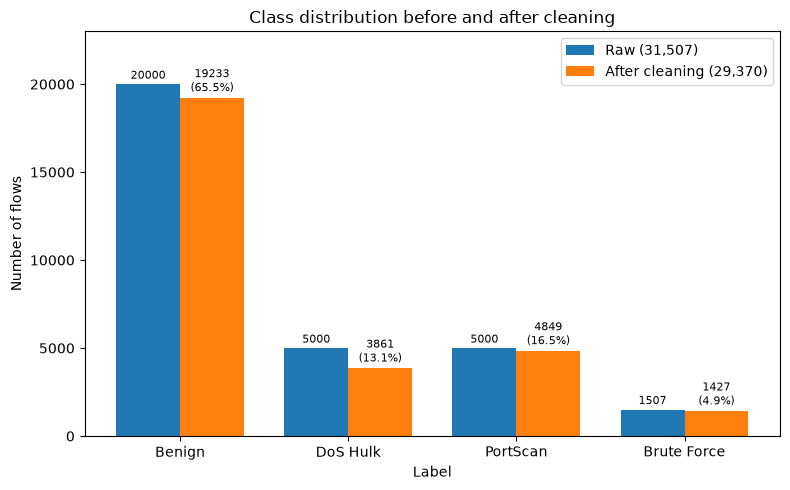

In [4]:
#2. HANDLE MISSING, INVALID AND DUPLICATED VALUES

raw_counts = df["Label"].value_counts()                     #per-class counts before cleaning

#(a) inf and NaN: all 27 affected rows have Flow Duration = 0, so the rate features
#    (Flow Bytes/s, Flow Packets/s) are x/0 = inf or 0/0 = NaN -> not recoverable, dropped
data = df.replace([np.inf, -np.inf], np.nan)
data = data.dropna()
naninf_counts = data["Label"].value_counts()
print("After removing inf/NaN:", len(data))

#(b) negative values: implausible for durations, counts and rates (Flow Duration = -1)
data = data[(data[features_names] >= 0).all(axis=1)]
neg_counts = data["Label"].value_counts()
print("After removing negative values:", len(data))

#(c) exact duplicates (features AND label): removed before the split,
#    so identical copies cannot end up in both train and test (leakage)
data = data.drop_duplicates()
dup_counts = data["Label"].value_counts()
print("After removing exact duplicates:", len(data))

#(d) conflicting duplicates: same feature vector with different labels.
#    After (c) every remaining feature-duplicate has a different label.
#    No model can classify them correctly -> all copies are dropped (keep=False)
conflict = data.duplicated(subset=features_names, keep=False)
print("Conflicting rows:\n", data.loc[conflict, "Label"].value_counts())
df_clean = data[~conflict]
clean_counts = df_clean["Label"].value_counts()
print("After removing conflicting duplicates:", len(df_clean))

#per-class counts at each cleaning step
cleaning = pd.DataFrame({"raw": raw_counts,
                         "after NaN/inf": naninf_counts,
                         "after negatives": neg_counts,
                         "after duplicates": dup_counts,
                         "clean": clean_counts}).fillna(0).astype(int)
cleaning.loc["TOTAL"] = cleaning.sum()
cleaning["% lost"] = ((1 - cleaning["clean"] / cleaning["raw"]) * 100).round(1)
print(cleaning)

#plot: class distribution before and after cleaning
order = ["Benign", "DoS Hulk", "PortScan", "Brute Force"]
x = np.arange(len(order)); w = 0.38

fig, ax = plt.subplots(figsize=(8, 5))
b1 = ax.bar(x - w/2, raw_counts[order],   w, label=f"Raw ({raw_counts.sum():,})")
b2 = ax.bar(x + w/2, clean_counts[order], w, label=f"After cleaning ({clean_counts.sum():,})")
ax.bar_label(b1, fontsize=8, padding=2)
ax.bar_label(b2, labels=[f"{v}\n({v/len(df_clean):.1%})" for v in clean_counts[order]], fontsize=8, padding=2)
ax.set_xticks(x, order)
ax.set_title("Class distribution before and after cleaning")
ax.set_xlabel("Label"); ax.set_ylabel("Number of flows")
ax.set_ylim(0, raw_counts.max() * 1.15)
ax.legend()
plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, "1_class_distribution.png"), dpi=300)   #figure for the report
plt.show()

### 1.3 Train / validation / test split
70% / 15% / 15%, stratified on the labels.

**Why 70 / 15 / 15.** With 15%, the rarest class (Brute Force) still has 214 flows in validation and in test: enough to read its recall and precision (one flow ≈ 0.5% of recall). A smaller share would make the per-class metrics of the rare class too noisy.

**Q: Should the split be stratified? Why?**
Yes. The classes are imbalanced (Benign 65%, Brute Force under 5%). A random split could leave validation or test with noticeably fewer Brute Force flows than the training set, so the per-class metrics would depend on the luck of the split. Stratification keeps the same class proportions in all three partitions (table below).

**Q: Where did you fit the scaler, and what goes wrong if you fit it on all the data?**
On the training set only (see 1.4.2). Validation and test are transformed with the training mean and std. If the scaler were fitted on all the data, the mean and std would contain information from the validation and test flows (data leakage): the model would be evaluated on data that already influenced its preprocessing, and the validation/test scores would be optimistic.


In [5]:
#3. SPLIT

X = df_clean.drop(columns="Label") #data frame without column "Label" (only features)
y = df_clean["Label"].values

#70% training, 15% validation, 15% test

X_train, X_temp, y_train, y_temp = train_test_split(X, y, test_size=0.3, stratify=y, random_state=SEED)
#test_size=0.3 --> 30% of data in (X_temp, y_temp), 70% in (X_train, y_train)
#stratify is used to maintain the same distribution (%) of classes with respect to labels (y)
#random_state=SEED is the seed used to shuffle the data, so that the split is reproducible

X_val, X_test, y_val, y_test = train_test_split(X_temp, y_temp, test_size=0.5, stratify=y_temp, random_state=SEED)
#test_size=0.5 --> 50% of previous temp_data
#                  (50% of 30% of total data --> 15%)
#                  15% in (X_test, y_test)
#                  15% in (X_val, y_val)
#stratify is used to maintain the same distribution (%) of classes with respect to previous temp_labels (y_temp)

#build a DataFrame (table) in which classes are counted
split_counts = pd.DataFrame({
    "train": pd.Series(y_train).value_counts(),
    "val":   pd.Series(y_val).value_counts(),
    "test":  pd.Series(y_test).value_counts(),
})
split_counts.loc["TOTAL"] = split_counts.sum()
print(split_counts)

#class distribution (%) per partition: with stratification the columns must be (almost) identical
split_pct = (split_counts.drop("TOTAL") / split_counts.drop("TOTAL").sum() * 100).round(2)
print(split_pct)

             train   val  test
Benign       13463  2885  2885
PortScan      3394   727   728
DoS Hulk      2703   579   579
Brute Force    999   214   214
TOTAL        20559  4405  4406
             train    val   test
Benign       65.48  65.49  65.48
PortScan     16.51  16.50  16.52
DoS Hulk     13.15  13.14  13.14
Brute Force   4.86   4.86   4.86


### 1.4 Scaling

#### 1.4.1 Pre-scaling analysis
How to read the boxplot: the box goes from Q1 (25th percentile) to Q3 (75th percentile) and contains the central 50% of the data; its width is the IQR (Q3 − Q1).
The line inside the box is the median. The whiskers reach the most extreme point within 1.5 × IQR from Q1 / Q3.
Circles are the points beyond the whiskers (outliers according to Tukey's rule).

inf: 0 | NaN: 0


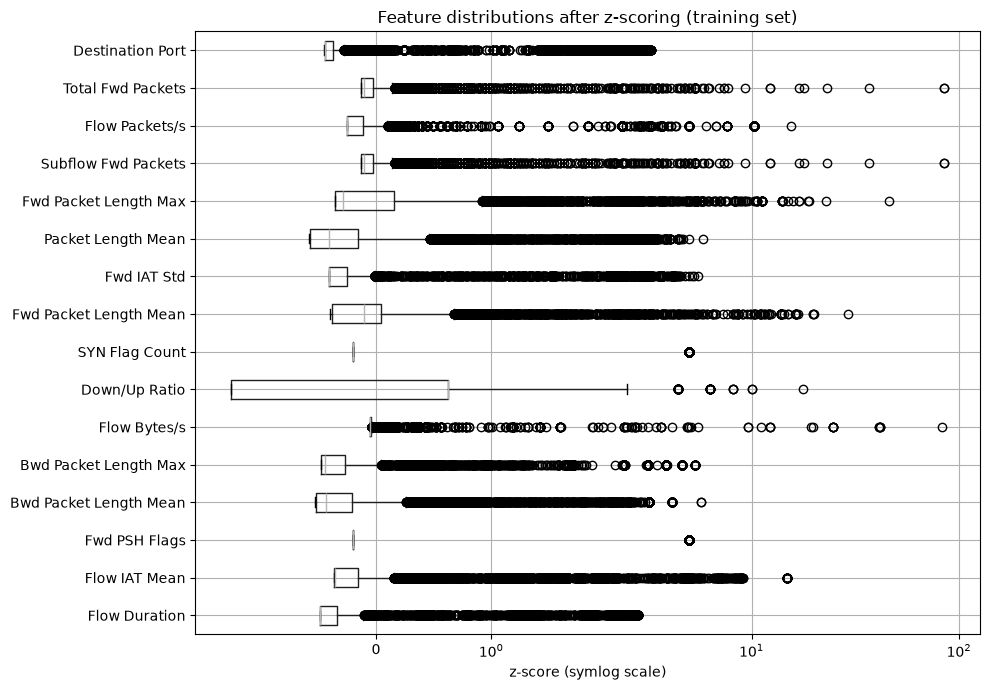

                         skew  max_z  pct_outlier  pct_zero  iqr_in_z
Subflow Fwd Packets     63.44  84.95         8.46      0.00      0.11
Total Fwd Packets       63.44  84.95         8.46      0.00      0.11
Flow Bytes/s            49.63  82.66        16.18     12.08      0.01
Fwd Packet Length Max   11.98  46.17         4.86     21.01      0.51
Fwd Packet Length Mean  11.44  29.30         5.63     21.01      0.42
Flow Packets/s           7.22  15.46         7.97      0.00      0.14
Flow IAT Mean            6.95  14.79        16.57      0.00      0.21
SYN Flag Count           4.78   4.98         3.87     96.13      0.00
Fwd PSH Flags            4.78   4.98         3.87     96.13      0.00
Fwd IAT Std              2.54   5.52        15.18     60.41      0.16
Bwd Packet Length Max    2.46   5.34        22.47     20.74      0.21
Destination Port         2.14   3.26        22.08      0.02      0.07
Bwd Packet Length Mean   2.11   5.69        18.10     20.74      0.31
Packet Length Mean  

In [6]:
#4.1 PRE-SCALING

#sanity check on infinity and NaN
print("inf:", np.isinf(X_train).sum().sum(), "| NaN:", X_train.isna().sum().sum())

#Z-SCORE = how many std a value is from the mean (computed on training only)
Z = (X_train - X_train.mean()) / X_train.std()

plt.figure(figsize=(10, 7))
Z.boxplot(vert=False)
plt.xscale("symlog")
plt.xlabel("z-score (symlog scale)")
plt.title("Feature distributions after z-scoring (training set)")
plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, "1_boxplot_zscore.png"), dpi=300)   #figure for the report
plt.show()

#Quantification of outliers
q1, q3 = X_train.quantile(0.25), X_train.quantile(0.75)
iqr = q3 - q1                                                       #interquartile range: spread of the central 50% of data, not affected by extremes
is_out = (X_train < q1 - 1.5 * iqr) | (X_train > q3 + 1.5 * iqr)    #outliers by Tukey's rule (1.5 x IQR below Q1 or above Q3)

diag = pd.DataFrame({
    "skew":        X_train.skew(),                  #asymmetry: > 0 means a long right tail
    "max_z":       Z.max(),                         #how many std the most extreme value is from the mean
    "pct_outlier": is_out.mean() * 100,             #% of outliers per feature
    "pct_zero":    (X_train == 0).mean() * 100,     #% of zeros (identifies quasi-binary features)
    "iqr_in_z":    iqr / X_train.std(),             #width of the central 50% after standard scaling
}).sort_values("skew", ascending=False)             #descending skew: worst features first
print(diag.round(2), "\n")

out_by_class = (is_out.groupby(y_train).mean() * 100).round(1).T    #% of each class beyond the whiskers
print(out_by_class, "\n")


#Min-Max vs Standard: share of the scale occupied by the central 50% of the data
rng = X_train.max() - X_train.min()
cmp = pd.DataFrame({"iqr_standard": iqr / X_train.std(),
                    "iqr_minmax":   iqr / rng})
cmp["ratio"] = cmp["iqr_standard"] / cmp["iqr_minmax"]
print(cmp.round(4).sort_values("ratio", ascending=False), "\n")

#effect of log1p: skew, compression of the bulk (% of flows with |z| < 0.1) and max |z|
Z_log = (np.log1p(X_train) - np.log1p(X_train).mean()) / np.log1p(X_train).std()
print(pd.DataFrame({"skew_raw":      X_train.skew(),
                    "skew_log1p":    np.log1p(X_train).skew(),
                    "near0_raw_%":   (Z.abs() < 0.1).mean() * 100,
                    "near0_log1p_%": (Z_log.abs() < 0.1).mean() * 100,
                    "maxz_raw":      Z.abs().max(),
                    "maxz_log1p":    Z_log.abs().max()}).round(2).sort_values("skew_raw", ascending=False))
#destination-port profile of each class (training set)
#(Destination Port is treated as numerical, but its values are identifiers: we check how each class uses them)
ports = pd.DataFrame({"port": X_train["Destination Port"].values, "label": y_train})
print(ports.groupby("label")["port"].agg(n_distinct_ports="nunique",
                                         share_port_80=lambda p: (p == 80).mean()).round(3))
print("top-3 ports of Benign:", ports[ports["label"] == "Benign"]["port"].value_counts().head(3).to_dict())
print("Benign training flows on port 80:", ((ports["label"] == "Benign") & (ports["port"] == 80)).sum())

**What we observe.**

- Almost all features are strongly right-skewed (skew up to 63); the most extreme value is up to 85 std from the mean.
- Outliers are class-typical, not errors: 78–86% of DoS Hulk flows are beyond the whiskers in six features, 54% of PortScan flows in Destination Port → we keep them.
- With Min-Max the central 50% of the data would be squeezed much more than with standard scaling (up to 85× on Total Fwd Packets) → we discard Min-Max.
- Even with standard scaling the bulk of some features stays near zero (Flow Bytes/s: 96.9% of flows within |z| < 0.1); log1p reduces this (8.7%) → hypothesis tested in R1L.
- *Destination Port.* Brute Force and DoS Hulk use only port 80; PortScan spans 967 different ports; Benign uses mostly 53, 443 and 80 (1,440 training flows on port 80). Port 80 is therefore shared by two attack classes and part of the normal traffic.

#### 1.4.2 Scaling
StandardScaler fitted on the training set only; validation and test are transformed with the training mean and std.

In [7]:
#4.2 SCALING

#Outliers are kept: they are class-typical (e.g. ~80% of DoS Hulk is beyond the whiskers in 5 features),
#so removing them would remove part of the attack classes.
#StandardScaler brings all features to a common scale (mean 0, std 1).
#Known limit: heavy tails inflate the std and squeeze the bulk of the data near 0
#-> log1p before scaling is tested as a separate run in Task 2A (R1L).

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)   #fit: mean and std from the TRAINING data only; transform: (x - mean) / std
X_val_scaled   = scaler.transform(X_val)         #same mean and std as training (no information from validation)
X_test_scaled  = scaler.transform(X_test)        #same mean and std as training (no information from test)

#scaling check (on training: mean 0, std 1 by construction)
print("train mean (max abs):", np.abs(X_train_scaled.mean(axis=0)).max().round(6))
print("train std  (min/max):", X_train_scaled.std(axis=0).min().round(3), X_train_scaled.std(axis=0).max().round(3))

#largest |z| per partition and where it comes from: values far beyond the training range are inputs the network never saw
for name, Xs, Xraw, ys in [("train", X_train_scaled, X_train, y_train),
                           ("val",   X_val_scaled,   X_val,   y_val),
                           ("test",  X_test_scaled,  X_test,  y_test)]:
    row, col = np.unravel_index(np.abs(Xs).argmax(), Xs.shape)    #position (row, column) of the largest |z|
    feat = features_names[col]
    print(f"{name}: max |z| = {np.abs(Xs).max():.1f} | feature: {feat} | class: {ys[row]} "
          f"| raw value: {Xraw.iloc[row][feat]:,.0f} (train max: {X_train[feat].max():,.0f})")

train mean (max abs): 0.0
train std  (min/max): 1.0 1.0
train: max |z| = 84.9 | feature: Subflow Fwd Packets | class: Benign | raw value: 3,141 (train max: 3,141)
val: max |z| = 504.0 | feature: Subflow Fwd Packets | class: Benign | raw value: 18,605 (train max: 3,141)
test: max |z| = 41.5 | feature: Flow Bytes/s | class: Benign | raw value: 1,040,000,000 (train max: 2,070,000,000)


**Q: Which scaling did you pick and why? How did the outliers inform the choice?**

We picked **StandardScaler, fitted on the training set only** (validation and test are transformed with the training mean and std; fitting it on all the data would leak information from validation and test into the preprocessing).

- *Why scaling at all.* The raw features span very different ranges (from 0/1 flags up to ~2·10⁹ for Flow Bytes/s). Without a common scale, the features with large values dominate the first layer.
- *Why not Min-Max.* The features are heavily right-skewed (skew up to 63). Min-Max divides by the full range, so a single extreme value squeezes the central 50% of the data into a tiny interval (e.g. Total Fwd Packets: IQR = 0.0013 of the scale with Min-Max vs 0.11 with standard scaling).
- *Why we keep the outliers.* They are not errors but class-typical values: 78–86% of DoS Hulk flows are beyond the whiskers in six features, and 54% of PortScan flows are outliers in Destination Port. Removing them would remove a large part of the attack classes.
- *Known limit.* Standard scaling does not remove the tails, it only rescales them. The bulk of several features stays squeezed near zero (Flow Bytes/s: 96.9% of the flows within |z| < 0.1), and validation contains a value far outside the training range (|z| = 504 on Subflow Fwd Packets: a Benign flow with 18,605 packets vs a training maximum of 3,141). The analysis in 1.4.1 suggests that **log1p before scaling** fixes both problems: we keep it as a hypothesis and test it as a single change on the baseline (R1L, Task 2A).

#### 1.4.3 Label encoding and tensors

In [8]:
#4.3 LABEL ENCODING AND TENSORS

le = LabelEncoder()
y_train_encoded = le.fit_transform(y_train)     #fit on training labels (alphabetical order)
y_val_encoded   = le.transform(y_val)
y_test_encoded  = le.transform(y_test)
print("Classes:", dict(zip(le.classes_, range(len(le.classes_)))))  #Benign=0, Brute Force=1, DoS Hulk=2, PortScan=3

#numpy -> tensor (features float32, labels long as required by CrossEntropyLoss)
X_train_t = torch.tensor(X_train_scaled, dtype=torch.float32)
y_train_t = torch.tensor(y_train_encoded, dtype=torch.long)
X_val_t   = torch.tensor(X_val_scaled, dtype=torch.float32)
y_val_t   = torch.tensor(y_val_encoded, dtype=torch.long)
X_test_t  = torch.tensor(X_test_scaled, dtype=torch.float32)
y_test_t  = torch.tensor(y_test_encoded, dtype=torch.long)
print(X_train_t.shape, X_val_t.shape, X_test_t.shape)

Classes: {'Benign': 0, 'Brute Force': 1, 'DoS Hulk': 2, 'PortScan': 3}
torch.Size([20559, 16]) torch.Size([4405, 16]) torch.Size([4406, 16])


## Task 2 – Your first network

All runs of Task 2 start from the preprocessed tensors of Task 1 (no new split, no new scaling).
Every run that trains a model has its own Markdown header with the logbook ID (R1, R2, ...) and the hypothesis written **before** running the cell.

### 2.0 Setup: shared settings and functions
The same functions are used by every run, so two runs can only differ in the one thing we change on purpose.

In [9]:
#2.0 SETUP


from torch.utils.data import DataLoader, TensorDataset
from sklearn.metrics import f1_score



#device: CPU on purpose -> the same seed gives the same numbers on the same machine and library versions
#(GPU results, or other library versions, differ slightly);
#the dataset is small and tabular, so the CPU is fast enough
device = torch.device("cpu")
print("device:", device)

#hyper-parameters of the baseline (recommended starting point of the lab text)
INPUT_SIZE  = X_train_t.shape[1]    #16 features
NUM_CLASSES = len(le.classes_)      #4 classes
HIDDEN      = 64                    #units of the single hidden layer
LR          = 5e-4                  #learning rate of AdamW
BATCH_SIZE  = 64                    #flows per mini-batch
NUM_EPOCHS  = 100                   #maximum number of epochs
PATIENCE    = 10                    #epochs without improvement of the val loss before stopping
MIN_DELTA   = 1e-4                  #minimum decrease of the val loss that counts as an improvement

#reference values to read the loss curves
#loss of a model that gives the same probability to the 4 classes (what the untrained network does): ln(4)
LOSS_UNIFORM = np.log(NUM_CLASSES)
#loss of a model that always outputs the class frequencies of the training set (it learned nothing from the features)
priors = np.bincount(y_train_encoded) / len(y_train_encoded)
LOSS_PRIORS = -(priors * np.log(priors)).sum()
print(f"reference losses: uniform = {LOSS_UNIFORM:.3f} | class priors = {LOSS_PRIORS:.3f}")

#accuracy of the trivial model that always predicts the majority class (Benign) on validation
TRIVIAL_ACC = (y_val_encoded == np.bincount(y_train_encoded).argmax()).mean()
print(f"trivial accuracy (always Benign) on validation: {TRIVIAL_ACC:.4f}")

#dictionary that collects the results of every run (used for the summary table and the logbook)
runs = {}

device: cpu
reference losses: uniform = 1.386 | class priors = 0.988
trivial accuracy (always Benign) on validation: 0.6549


In [10]:
#network: one hidden layer, the activation is a parameter (needed in Task 2C to switch ReLU <-> linear)
class MulticlassNN(nn.Module):
    def __init__(self, input_size, hidden_size, num_classes, activation):
        super().__init__()                                          #call the constructor of nn.Module
        self.hidden_layer = nn.Linear(input_size, hidden_size)      #16 inputs -> 64 hidden units (weights + bias)
        self.activation   = activation                              #nn.ReLU() or nn.Identity() (no non-linearity)
        self.output_layer = nn.Linear(hidden_size, num_classes)     #64 hidden units -> 4 scores (logits), one per class

    def forward(self, x):
        x = self.activation(self.hidden_layer(x))                   #hidden layer + activation
        return self.output_layer(x)                                 #raw logits: no softmax here, CrossEntropyLoss applies it internally


def build_model(activation=None):
    #same seed before creating the model -> every run starts from the SAME initial weights,
    #so the difference between two runs is caused only by the one thing we changed
    torch.manual_seed(SEED)
    activation = activation if activation is not None else nn.ReLU()
    return MulticlassNN(INPUT_SIZE, HIDDEN, NUM_CLASSES, activation).to(device)


#Task 5: network with any number of hidden layers (ReLU after each one); with [64] it is the baseline above
#Task 6: optional batch normalization (before the ReLU) and dropout (after the ReLU) in every hidden layer
class DeepNN(nn.Module):
    def __init__(self, input_size, hidden_sizes, num_classes, dropout=0.0, batchnorm=False):
        super().__init__()
        layers, prev = [], input_size
        for h in hidden_sizes:
            layers.append(nn.Linear(prev, h))                       #hidden layer
            if batchnorm:
                layers.append(nn.BatchNorm1d(h))                    #Task 6: normalises the pre-activations of the mini-batch
            layers.append(nn.ReLU())                                #activation
            if dropout > 0:
                layers.append(nn.Dropout(dropout))                  #Task 6: zeroes each unit with probability p during training
            prev = h
        layers.append(nn.Linear(prev, num_classes))                 #output layer: raw logits
        self.net = nn.Sequential(*layers)

    def forward(self, x):
        return self.net(x)


def build_deep_model(hidden_sizes, dropout=0.0, batchnorm=False):
    torch.manual_seed(SEED)                                         #same seed as build_model (same rule: same start for every run)
    return DeepNN(INPUT_SIZE, hidden_sizes, NUM_CLASSES, dropout, batchnorm).to(device)


def make_loaders(X_tr, y_tr, X_v, y_v, batch_size=BATCH_SIZE):
    #training: shuffled at every epoch, so the mini-batches change and the gradient is not biased by the order of the rows
    #the generator with a fixed seed makes the shuffling identical across runs (reproducibility)
    g = torch.Generator().manual_seed(SEED)
    train_loader = DataLoader(TensorDataset(X_tr, y_tr), batch_size=batch_size, shuffle=True, generator=g)
    #validation: no shuffling needed, we only compute the loss (the order does not change the average)
    val_loader = DataLoader(TensorDataset(X_v, y_v), batch_size=batch_size, shuffle=False)
    return train_loader, val_loader


#size of the baseline network: 16*64 + 64 (hidden layer) + 64*4 + 4 (output layer)
print("trainable parameters of the baseline:", sum(p.numel() for p in build_model().parameters()))

trainable parameters of the baseline: 1348


In [11]:
def train_model(model, train_loader, val_loader, lr=LR, num_epochs=NUM_EPOCHS,
                patience=PATIENCE, min_delta=MIN_DELTA, print_every=10, class_weights=None,
                optimizer_name="adamw", momentum=0.0, weight_decay=None, early_stopping=True):
    """Train with mini-batches and early stopping on the validation loss.
    Returns the loss history, the best epoch, the last epoch and the training time.
    At the end the model holds the weights of the best epoch (lowest validation loss)."""

    #softmax + negative log-likelihood of the true class; class_weights (Task 4): one weight per class, None = unweighted
    #(the validation loss uses the same weights, so early stopping follows the weighted objective)
    criterion = nn.CrossEntropyLoss(weight=class_weights)
    if optimizer_name == "adamw" and weight_decay is None:
        optimizer = optim.AdamW(model.parameters(), lr=lr)      #Adam + decoupled weight decay (default 0.01)
    elif optimizer_name == "adamw":                             #Task 6: explicit weight decay (0 = no regularization)
        optimizer = optim.AdamW(model.parameters(), lr=lr, weight_decay=weight_decay)
    else:                                                       #Task 5C: plain SGD (momentum=0) or SGD with momentum
        optimizer = optim.SGD(model.parameters(), lr=lr, momentum=momentum)

    history = {"train_loss": [], "val_loss": [], "val_f1": []}
    best_val_loss = float("inf")                                #lowest validation loss seen so far
    best_state = copy.deepcopy(model.state_dict())              #weights of the best epoch (deep copy: they must not change afterwards)
    best_epoch = 0
    epochs_no_improve = 0                                       #epochs since the last improvement

    start_time = time.time()
    for epoch in range(1, num_epochs + 1):

        #training phase: one pass over all the mini-batches
        model.train()                                           #training mode (no effect on this net, needed with dropout/batchnorm)
        running_loss = 0.0
        for batch_X, batch_y in train_loader:
            batch_X, batch_y = batch_X.to(device), batch_y.to(device)
            optimizer.zero_grad()                               #reset the gradients of the previous step (PyTorch accumulates them)
            loss = criterion(model(batch_X), batch_y)           #forward pass + loss of the mini-batch (mean over its flows)
            loss.backward()                                     #backpropagation: gradient of the loss w.r.t. every weight
            optimizer.step()                                    #update the weights
            running_loss += loss.item() * batch_X.size(0)       #loss.item() is a mean: multiply by the batch size to sum per flow
        train_loss = running_loss / len(train_loader.dataset)   #mean loss per flow over the epoch (computed while the weights change)

        #validation phase: loss on data the model does not learn from
        model.eval()
        running_loss = 0.0
        val_pred, val_true = [], []                             #Task 6: validation macro-F1 per epoch (no effect on training)
        with torch.no_grad():                                   #no gradients: faster and no memory for backpropagation
            for batch_X, batch_y in val_loader:
                batch_X, batch_y = batch_X.to(device), batch_y.to(device)
                logits = model(batch_X)
                running_loss += criterion(logits, batch_y).item() * batch_X.size(0)
                val_pred.append(logits.argmax(dim=1).cpu()); val_true.append(batch_y.cpu())
        val_loss = running_loss / len(val_loader.dataset)
        history["val_f1"].append(f1_score(torch.cat(val_true).numpy(), torch.cat(val_pred).numpy(), average="macro"))

        history["train_loss"].append(train_loss)
        history["val_loss"].append(val_loss)

        #early stopping: is this epoch better than the best one by at least min_delta?
        if val_loss < best_val_loss - min_delta:
            best_val_loss = val_loss
            best_state = copy.deepcopy(model.state_dict())      #save the weights of the new best epoch
            best_epoch = epoch
            epochs_no_improve = 0
        else:
            epochs_no_improve += 1                              #a NaN loss also ends here (NaN < x is always False)

        if epoch % print_every == 0 or epoch == 1:
            print(f"epoch {epoch:3d} | train loss {train_loss:.4f} | val loss {val_loss:.4f}")

        if early_stopping and epochs_no_improve >= patience:          #Task 6: early_stopping=False trains all the epochs
            print(f"early stopping at epoch {epoch}: no improvement for {patience} epochs")
            break                                               #without this break the loop would run all the epochs anyway

    elapsed = time.time() - start_time
    if early_stopping:
        model.load_state_dict(best_state)                       #restore the best weights (not the last ones)
    #without early stopping the model keeps the weights of the LAST epoch (best_epoch is still recorded, for the analysis)
    print(f"best epoch: {best_epoch} (val loss {best_val_loss:.4f}) | last epoch: {epoch} | time: {elapsed:.1f} s")
    return history, best_epoch, epoch, elapsed

In [12]:
def plot_losses(history, best_epoch, title, filename=None, show_priors=True):
    """Training and validation loss per epoch, best epoch and reference losses."""
    epochs = np.arange(1, len(history["train_loss"]) + 1)
    fig, ax = plt.subplots(figsize=(7, 3.5))
    ax.plot(epochs, history["train_loss"], label="Training loss")
    ax.plot(epochs, history["val_loss"], label="Validation loss")
    ax.axvline(best_epoch, color="grey", ls="--", lw=1, label=f"Best epoch ({best_epoch})")
    #reference lines: above LOSS_PRIORS the model has learned nothing from the features
    ax.axhline(LOSS_UNIFORM, color="tab:red", ls=":", lw=1, label=f"Uniform guess ({LOSS_UNIFORM:.2f})")
    if show_priors:                                             #not meaningful for a class-weighted loss (Task 4)
        ax.axhline(LOSS_PRIORS, color="tab:purple", ls=":", lw=1, label=f"Class priors ({LOSS_PRIORS:.2f})")
    ax.set_yscale("log")                                        #log scale: same axis for runs whose losses differ by orders of magnitude
    ax.set_xlabel("Epoch"); ax.set_ylabel("Cross-entropy loss (log scale)")
    ax.set_title(title)
    ax.legend(fontsize=8)
    plt.tight_layout()
    if filename:
        plt.savefig(os.path.join(FIG_DIR, filename), dpi=300)   #figure for the report
    plt.show()


def evaluate(model, X_t, y_t, split_name, show_cm=True, filename=None):
    """Classification report (+ confusion matrix) of a trained model on one partition. It does NOT train: it is not a new run."""
    model.eval()
    with torch.no_grad():
        logits = model(X_t.to(device))
        y_pred = logits.argmax(dim=1).cpu().numpy()             #predicted class = the one with the highest score
    y_true = y_t.cpu().numpy()

    acc = accuracy_score(y_true, y_pred)
    macro_f1 = f1_score(y_true, y_pred, average="macro")
    #trivial model on THIS partition: always predict the majority class of the training set (Benign)
    trivial = (y_true == le.transform(["Benign"])[0]).mean()
    print(f"{split_name}: accuracy {acc:.4f} (trivial {trivial:.4f}) | macro-F1 {macro_f1:.4f}")
    print(classification_report(y_true, y_pred, target_names=le.classes_, digits=3, zero_division=0))

    if show_cm:
        cm = confusion_matrix(y_true, y_pred, labels=range(NUM_CLASSES))
        disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=le.classes_)
        fig, ax = plt.subplots(figsize=(5, 4))
        disp.plot(cmap=plt.cm.Blues, ax=ax, xticks_rotation=45, values_format="d", colorbar=False)
        ax.set_title(f"Confusion matrix ({split_name})")
        plt.tight_layout()
        if filename:
            plt.savefig(os.path.join(FIG_DIR, filename), dpi=300)   #figure for the report
        plt.show()

    report = classification_report(y_true, y_pred, target_names=le.classes_, output_dict=True, zero_division=0)
    return {"accuracy": acc, "macro_f1": macro_f1, "y_pred": y_pred,
            "recall":    {c: report[c]["recall"] for c in le.classes_},
            "precision": {c: report[c]["precision"] for c in le.classes_}}


def curve_stats(history, best_epoch):
    """Numbers that check the hypotheses on the shape of the loss curves."""
    tr = np.array(history["train_loss"]); va = np.array(history["val_loss"])
    log_va = np.log(va[np.isfinite(va)])                            #log scale: a spike from 0.1 to 1 counts like one from 10 to 100
    last = va[-11:] if len(va) > 10 else va
    return {
        "start train loss": tr[0],                                  #compare with ln(4) = 1.39: far above -> huge logits (no scaling)
        "start val loss": va[0],
        "min val loss": np.nanmin(va),                              #compare with 0.99 (class priors): above -> nothing learned from the features
        "NaN epochs": int((~np.isfinite(va)).sum()),                #diverged epochs
        "val roughness": np.abs(np.diff(log_va)).mean() if len(log_va) > 1 else np.nan,   #mean |change| per epoch on log scale: jaggedness
        "train roughness": np.abs(np.diff(np.log(tr[np.isfinite(tr)]))).mean(),
        "gap at best (val-train)": va[best_epoch - 1] - tr[best_epoch - 1] if best_epoch > 0 else np.nan,
        "val slope last 10 ep (%/ep)": 100 * (last[-1] / last[0] - 1) / (len(last) - 1),  #still decreasing at the end? (negative = yes)
    }


def run_experiment(run_id, X_tr, X_v, lr=LR, activation=None, title="", num_epochs=NUM_EPOCHS,
                   y_tr=None, y_v=None, class_weights=None,
                   hidden_sizes=None, batch_size=BATCH_SIZE, optimizer_name="adamw", momentum=0.0,
                   weight_decay=None, early_stopping=True, dropout=0.0, batchnorm=False):
    """One logbook run: build the model, train it, plot the curves, evaluate it on validation.
    y_tr / y_v: labels (default: the Task 1 split); class_weights: weighted loss (default: unweighted).
    Task 5: hidden_sizes (None = the one-layer baseline), batch_size, optimizer_name ("adamw" or "sgd") and momentum.
    Task 6: weight_decay (None = AdamW default 0.01), early_stopping (False = all epochs, last weights), dropout, batchnorm."""
    y_tr = y_train_t if y_tr is None else y_tr
    y_v  = y_val_t if y_v is None else y_v
    model = build_model(activation) if hidden_sizes is None else build_deep_model(hidden_sizes, dropout, batchnorm)
    train_loader, val_loader = make_loaders(X_tr, y_tr, X_v, y_v, batch_size=batch_size)
    history, best_epoch, last_epoch, elapsed = train_model(model, train_loader, val_loader, lr=lr, num_epochs=num_epochs,
                                                           class_weights=class_weights,
                                                           optimizer_name=optimizer_name, momentum=momentum,
                                                           weight_decay=weight_decay, early_stopping=early_stopping)
    plot_losses(history, best_epoch, f"{run_id} – {title}", filename=f"{run_id}_loss.png", show_priors=class_weights is None)
    metrics = evaluate(model, X_v, y_v, "validation", filename=f"{run_id}_cm_val.png")
    runs[run_id] = {"model": model, "history": history, "best_epoch": best_epoch,
                    "last_epoch": last_epoch, "time_s": elapsed, **metrics,
                    "curve": curve_stats(history, best_epoch),
                    "n_params": sum(p.numel() for p in model.parameters()),
                    "early_stopping": early_stopping}
    return model

### 2A – Minimal working classifier

#### R1 – Baseline: 1 hidden layer (64, ReLU), cross-entropy, AdamW lr 5e-4, batch 64, ≤100 epochs, early stopping (patience 10)

**Why this run:** it is the reference for every later run, so it must be the simplest configuration we fully understand (the recommended starting point of the lab text).

**Hypothesis (written before running):**
- *Hardest class: Brute Force.* It is the only class that combines two difficulties measured in Task 1: it is the rarest (4.86%, 999 training flows, so it weighs little in the mean loss) and it lies almost entirely inside the bulk of the data, without the extreme values that make DoS Hulk (78–86% of its flows beyond the whiskers in six features) and PortScan (967 different destination ports in the training set) easy to separate.
- *Type of error.* We expect Brute Force to fail mainly through missed detections (lowest recall of the four classes), with its flows predicted as Benign: in doubtful cases the network favours the class that dominates the loss. A secondary risk is false positives on Benign port-80 traffic, because every Brute Force flow uses port 80 (as do all DoS Hulk flows and 1,440 Benign training flows).
- *Easiest classes.* DoS Hulk and PortScan, for the extreme values recalled above.
- *Overall metrics.* Accuracy well above the trivial 65.5% (always Benign); macro-F1 visibly lower than accuracy, since accuracy is dominated by Benign and macro-F1 weighs the four classes equally.
- *Curves.* Fast drop from ln(4) ≈ 1.39 (an untrained network gives the same probability to each class), then a plateau. Small train/validation gap: 1,348 parameters cannot memorise 20,559 flows. Early stopping well before epoch 100.

epoch   1 | train loss 0.7580 | val loss 0.4880
epoch  10 | train loss 0.1933 | val loss 0.1841
epoch  20 | train loss 0.1601 | val loss 0.1583
epoch  30 | train loss 0.1477 | val loss 0.1473
epoch  40 | train loss 0.1390 | val loss 0.1402
epoch  50 | train loss 0.1330 | val loss 0.1345
epoch  60 | train loss 0.1281 | val loss 0.1273
epoch  70 | train loss 0.1245 | val loss 0.1234
epoch  80 | train loss 0.1215 | val loss 0.1214
epoch  90 | train loss 0.1193 | val loss 0.1204
epoch 100 | train loss 0.1175 | val loss 0.1166
best epoch: 100 (val loss 0.1166) | last epoch: 100 | time: 33.1 s


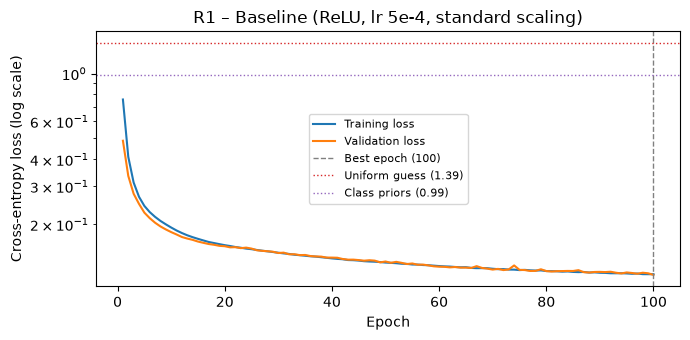

validation: accuracy 0.9587 (trivial 0.6549) | macro-F1 0.9365
              precision    recall  f1-score   support

      Benign      0.969     0.972     0.971      2885
 Brute Force      0.824     0.944     0.880       214
    DoS Hulk      0.989     0.934     0.961       579
    PortScan      0.940     0.928     0.934       727

    accuracy                          0.959      4405
   macro avg      0.931     0.945     0.936      4405
weighted avg      0.960     0.959     0.959      4405



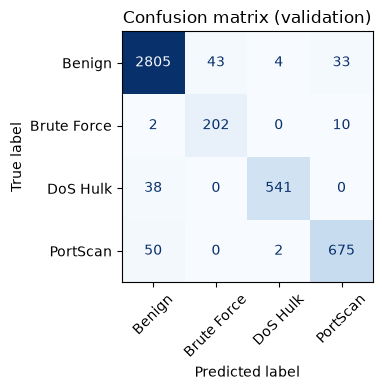

In [13]:
#R1 - TASK 2A BASELINE
model_R1 = run_experiment("R1", X_train_t, X_val_t, title="Baseline (ReLU, lr 5e-4, standard scaling)")

**R1 – where are the errors?** (analysis of the trained R1 model, not a new run)
The hypothesis named port 80 as a possible source of Brute Force false positives: we check the destination port of the misclassified validation flows.

In [14]:
#R1 ERROR ANALYSIS: destination port of the misclassified validation flows
#X_val (DataFrame of Task 1, before scaling) has the same row order as X_val_t, so the raw port can be read directly
err = pd.DataFrame({"true": le.classes_[y_val_encoded],
                    "pred": le.classes_[runs["R1"]["y_pred"]],
                    "port": X_val["Destination Port"].values})
wrong = err[err["true"] != err["pred"]]
print("misclassified validation flows:", len(wrong), "of", len(err))
print(pd.crosstab(wrong["true"], wrong["pred"]), "\n")                 #who is confused with whom



#share of port 80 among the errors that involve Brute Force
for label, mask in [("Benign predicted as Brute Force", (wrong["true"] == "Benign") & (wrong["pred"] == "Brute Force")),
                    ("DoS Hulk predicted as Brute Force", (wrong["true"] == "DoS Hulk") & (wrong["pred"] == "Brute Force")),
                    ("Brute Force predicted as something else", wrong["true"] == "Brute Force")]:
    sel = wrong[mask]
    print(f"{label}: {len(sel)} flows, on port 80: {(sel['port'] == 80).sum()}")

#how often a Benign flow on port 80 is flagged as Brute Force, vs a Benign flow on another port
benign = err[err["true"] == "Benign"]
for name, b in [("port 80", benign[benign["port"] == 80]), ("other ports", benign[benign["port"] != 80])]:
    print(f"Benign on {name}: {len(b)} flows, predicted Brute Force: {(b['pred'] == 'Brute Force').mean():.1%}")

misclassified validation flows: 182 of 4405
pred         Benign  Brute Force  DoS Hulk  PortScan
true                                                
Benign            0           43         4        33
Brute Force       2            0         0        10
DoS Hulk         38            0         0         0
PortScan         50            0         2         0 

Benign predicted as Brute Force: 43 flows, on port 80: 43
DoS Hulk predicted as Brute Force: 0 flows, on port 80: 0
Brute Force predicted as something else: 12 flows, on port 80: 12
Benign on port 80: 311 flows, predicted Brute Force: 13.8%
Benign on other ports: 2574 flows, predicted Brute Force: 0.0%


**R1 – outcome vs hypothesis**

- *Hardest class: Brute Force – partly right.* It has the lowest precision (0.824) and the lowest F1 (0.880), but not the lowest recall: 0.944, while PortScan (0.928) and DoS Hulk (0.934) are lower.
- *Type of error – wrong.* We expected missed detections, predicted as Benign. Instead the main problem of Brute Force is false positives: 43 Benign flows predicted as Brute Force, against only 12 Brute Force flows missed (10 of them predicted as PortScan, 2 as Benign).
- *Port-80 false positives – right.* All 43 false positives are Benign flows on port 80: 13.8% of the 311 Benign port-80 validation flows are flagged as Brute Force, 0.0% of the 2,574 Benign flows on other ports. The model links "port 80" to Brute Force.
- *Easiest classes – wrong.* PortScan and DoS Hulk have the two lowest recalls (0.928 and 0.934): 50 PortScan and 38 DoS Hulk flows are predicted as Benign. Their extreme values did not make them easy with standard scaling alone (tested in R1L).
- *Overall metrics – right.* Accuracy 0.959, well above the trivial 0.655; macro-F1 0.937, lower than accuracy as expected.
- *Curves – partly right.* Fast drop from ln(4) and small train/val gap, as expected. Wrong on early stopping: it never triggers, the best epoch is the last one (100).

**Q: How do you pick the "best" model across epochs? Do the curves converge?**
We keep the weights of the epoch with the lowest validation loss and restore them at the end (early stopping, patience 10, min_delta 1e-4). We use the validation loss rather than the validation macro-F1 because it is smoother: it uses the predicted probabilities, while macro-F1 only changes when a prediction flips, which makes it noisy on the rare class (214 Brute Force flows). The price is that we do not select directly on the metric we care about. The curves do **not** converge within the budget: the validation loss is still falling at epoch 100 (best epoch = 100), so R1 is limited by the 100-epoch cap, not by early stopping. Note: at epoch 1 the training loss (0.758) is above the validation loss (0.488) because it is averaged while the weights change, whereas the validation loss is computed at the end of the epoch.

**Q: Do your hardest-class predictions hold up? Explain the per-class results.**
Only in part. Brute Force is the weakest class, but through false positives rather than missed detections: since every Brute Force flow uses port 80, the model mistakes Benign port-80 traffic for Brute Force. PortScan and DoS Hulk, which we expected to be easy, lose most to Benign: with standard scaling alone the bulk of their features is squeezed near zero (Task 1.4.1), so the network struggles to separate them from normal traffic. This motivates R1L.

### 2A bis: TESTING OF OUR IDEA --> does log1p help the baseline?

#### R1L --> log1p before the standard scaler

**Why this run:** log1p compresses the heavy tails measured in 1.4.1 and here we check on the validation set whether it is actually useful. 
One change with respect to R1: `np.log1p` before the StandardScaler (same network, seed, learning rate, batch size and early stopping). 
It is worth a budget slot because the choice affects every later run: if log1p helps, all of Task 2–5 should start from it.

**Hypothesis (written before running):**
- *Curves.* The validation loss goes down faster and reaches a lower minimum. With plain standard scaling the heavy tails inflate the std, so the bulk of several features is squeezed into a tiny range (Flow Bytes/s: 96.9% of the flows within |z| < 0.1, IQR = 0.006 std): the network sees almost the same value for most flows and must learn very large weights to separate them, which takes many epochs (R1 was still improving at epoch 100). After log1p the same features spread over the whole unit scale (Flow Bytes/s near-zero share 96.9% → 8.7%, max |z| 83 → 2.9). Expected: val loss at epoch 10 and 30 clearly below R1 (0.184 and 0.147), min val loss below R1's 0.117, and early stopping before epoch 100.
- *Classes.* The biggest gain on Brute Force precision (0.824 in R1). Its errors are Benign flows on port 80 (all 43 false positives), so the port cannot help: the separation must come from size/rate features (packet lengths, Flow Bytes/s), exactly the ones whose bulk log1p un-squeezes. Expected Brute Force precision ≥ 0.85 with recall about unchanged (~0.94). DoS Hulk: little change, its extreme values remain extreme after log1p (only less far). PortScan: little change or a small loss (see below).
- *Destination Port.* The share of flows with |z| < 0.1 goes from 2.7% to 16%: log1p squeezes the high ports together (e.g. 1,000 vs 10,000 become 6.9 vs 9.2) and puts the most common ports (53, 80, 443) close to the mean. This makes the ports harder to tell apart for the network; it may slightly hurt PortScan (54% of its flows are port outliers in raw scale), so PortScan recall could drop by about 0.01.
- *Criterion (fixed now).* We adopt log1p for the rest of the lab only if the validation macro-F1 rises by at least +0.01 (R1: 0.9365 → ≥ 0.9465) **and** no class loses more than 0.02 of recall. We assume that a smaller difference could be produced by a different seed (not measured: one seed only), so we keep R1’s preprocessing. Expected outcome: macro-F1 about +0.01 to +0.03 above R1, so log1p adopted.

max |z| train / val: 8.53427791595459 10.80736255645752
epoch   1 | train loss 0.6472 | val loss 0.3370
epoch  10 | train loss 0.0831 | val loss 0.0742
epoch  20 | train loss 0.0545 | val loss 0.0514
epoch  30 | train loss 0.0450 | val loss 0.0422
epoch  40 | train loss 0.0396 | val loss 0.0389
epoch  50 | train loss 0.0362 | val loss 0.0350
epoch  60 | train loss 0.0340 | val loss 0.0321
epoch  70 | train loss 0.0328 | val loss 0.0305
epoch  80 | train loss 0.0314 | val loss 0.0297
epoch  90 | train loss 0.0303 | val loss 0.0288
epoch 100 | train loss 0.0292 | val loss 0.0272
best epoch: 99 (val loss 0.0273) | last epoch: 100 | time: 33.2 s


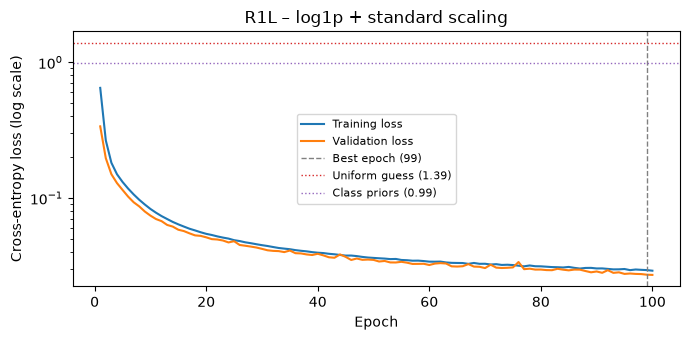

validation: accuracy 0.9936 (trivial 0.6549) | macro-F1 0.9875
              precision    recall  f1-score   support

      Benign      0.998     0.993     0.996      2885
 Brute Force      0.939     1.000     0.968       214
    DoS Hulk      0.985     0.993     0.989       579
    PortScan      1.000     0.994     0.997       727

    accuracy                          0.994      4405
   macro avg      0.980     0.995     0.988      4405
weighted avg      0.994     0.994     0.994      4405



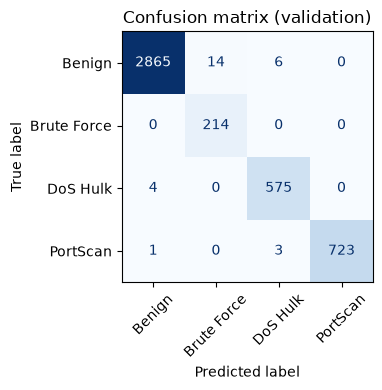

In [15]:
#R1L - SAME AS R1, WITH log1p BEFORE THE SCALER
#log1p is monotonic, has no learned parameters, and the cleaning removed negative values, so it is always defined
X_train_log = np.log1p(X_train)
X_val_log   = np.log1p(X_val)

#separate scaler: the Task 1 scaler (used by R1 and Task 3) stays untouched
scaler_log = StandardScaler()
X_train_log_t = torch.tensor(scaler_log.fit_transform(X_train_log), dtype=torch.float32)   #fit on the training set only
X_val_log_t   = torch.tensor(scaler_log.transform(X_val_log), dtype=torch.float32)         #same mean and std as training
print("max |z| train / val:", X_train_log_t.abs().max().item(), X_val_log_t.abs().max().item())

model_R1L = run_experiment("R1L", X_train_log_t, X_val_log_t, title="log1p + standard scaling")


                          R1       R1L
accuracy              0.9587    0.9936
macro-F1              0.9365    0.9875
recall Benign         0.9723    0.9931
recall Brute Force    0.9439    1.0000
recall DoS Hulk       0.9344    0.9931
recall PortScan       0.9285    0.9945
best epoch          100.0000   99.0000
last epoch          100.0000  100.0000
min val loss          0.1166    0.0272
val loss @10          0.1841    0.0742
val loss @30          0.1473    0.0422
val loss @60          0.1273    0.0321


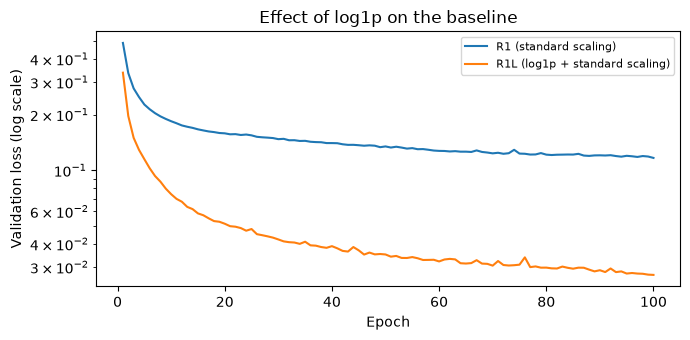

In [16]:
#R1 vs R1L: same network, same seed, same batches; the only difference is log1p before the scaler
def val_at(rid, epoch):
    h = runs[rid]["history"]["val_loss"]
    return h[min(epoch, len(h)) - 1]                           #if training stopped earlier, use the last epoch

rows = {}
for rid in ["R1", "R1L"]:
    r = runs[rid]
    rows[rid] = {"accuracy": r["accuracy"], "macro-F1": r["macro_f1"],
                 **{f"recall {c}": r["recall"][c] for c in le.classes_},
                 "best epoch": r["best_epoch"], "last epoch": r["last_epoch"],
                 "min val loss": min(r["history"]["val_loss"]),
                 "val loss @10": val_at(rid, 10), "val loss @30": val_at(rid, 30), "val loss @60": val_at(rid, 60)}
print(pd.DataFrame(rows).round(4))

#validation loss of the two runs on the same axes (figure for the report)
fig, ax = plt.subplots(figsize=(7, 3.5))
for rid, label in [("R1", "R1 (standard scaling)"), ("R1L", "R1L (log1p + standard scaling)")]:
    ax.plot(np.arange(1, len(runs[rid]["history"]["val_loss"]) + 1), runs[rid]["history"]["val_loss"], label=label)
ax.set_yscale("log"); ax.set_xlabel("Epoch"); ax.set_ylabel("Validation loss (log scale)")
ax.set_title("Effect of log1p on the baseline"); ax.legend(fontsize=8)
plt.tight_layout(); plt.savefig(os.path.join(FIG_DIR, "R1_vs_R1L_val_loss.png"), dpi=300); plt.show()


**R1L – where are the errors?** (analysis of the trained R1L model, not a new run)
Same check as for R1: who is confused with whom, and whether the Benign port-80 false positives are still there.

In [17]:
#R1L ERROR ANALYSIS: same table as R1, to see which confusions disappear with log1p
err_L = pd.DataFrame({"true": le.classes_[y_val_encoded],
                      "pred": le.classes_[runs["R1L"]["y_pred"]],
                      "port": X_val["Destination Port"].values})
wrong_L = err_L[err_L["true"] != err_L["pred"]]
print("misclassified validation flows: R1", len(wrong), "| R1L", len(wrong_L), "of", len(err_L))
print(pd.crosstab(wrong_L["true"], wrong_L["pred"]), "\n")

#precision and F1 per class side by side (recall is already in the table above)
print(pd.DataFrame({rid: {f"precision {c}": runs[rid]["precision"][c] for c in le.classes_} for rid in ["R1", "R1L"]}).round(3), "\n")

benign_L = err_L[err_L["true"] == "Benign"]
for name, b in [("port 80", benign_L[benign_L["port"] == 80]), ("other ports", benign_L[benign_L["port"] != 80])]:
    print(f"R1L - Benign on {name}: {len(b)} flows, predicted Brute Force: {(b['pred'] == 'Brute Force').mean():.1%}")


misclassified validation flows: R1 182 | R1L 28 of 4405
pred      Benign  Brute Force  DoS Hulk
true                                   
Benign         0           14         6
DoS Hulk       4            0         0
PortScan       1            0         3 

                          R1    R1L
precision Benign       0.969  0.998
precision Brute Force  0.824  0.939
precision DoS Hulk     0.989  0.985
precision PortScan     0.940  1.000 

R1L - Benign on port 80: 311 flows, predicted Brute Force: 4.5%
R1L - Benign on other ports: 2574 flows, predicted Brute Force: 0.0%


**R1L – outcome vs hypothesis and decision**

| | R1 | R1L |
|---|---|---|
| accuracy (val) | 0.959 | 0.994 |
| macro-F1 (val) | 0.937 | 0.988 |
| min val loss | 0.117 | 0.027 |
| misclassified val flows | 182 | 28 |

- *Curves – partly right.* The val loss is much lower at every checkpoint (epoch 10: 0.074 vs 0.184; epoch 30: 0.042 vs 0.147) and the minimum is about 4× lower. Wrong on early stopping: R1L, like R1, reaches its best epoch at the end of the run (epoch 99 of 100), so it is also still improving at the 100-epoch cap.
- *Classes – right on Brute Force precision (0.824 → 0.939, Benign port-80 flows flagged as Brute Force 13.8% → 4.5%), wrong on everything else.* Brute Force recall did not stay at ~0.94 but rose to 1.000. We expected DoS Hulk and PortScan to barely move, and PortScan possibly to lose a little because log1p packs the ports together. Instead they gained the most: DoS Hulk recall 0.934 → 0.993 and PortScan recall 0.928 → 0.994, because the 38 DoS Hulk and 50 PortScan flows that R1 called Benign are now almost all correct (4 and 1 left). Being "easy" in raw scale (extreme values) did not protect them: with standard scaling alone the bulk of their distinguishing features was squeezed near zero, and log1p un-squeezed it.
- *Criterion.* Macro-F1 +0.051 (threshold +0.01) and every class recall goes up, so the gain is far beyond what we would attribute to seed noise.

**Decision: log1p is kept for the rest of the lab.** R1L becomes the reference for the following runs (the next runs start from R1L, written ←R1L). The remaining errors are mostly Benign flows predicted as Brute Force (14) or DoS Hulk (6).

### TASK 2B

#### S1 – No feature scaling: raw features (no log1p, no StandardScaler), everything else as R1L

**Why this run:** it shows what scaling was buying us.

*Parent run.* S1 has no scaling at all: it is one change from R1 (StandardScaler removed) but two from R1L (no log1p either), so in the logbook it is written S1 (←R1). R1L, the reference at this point, is the comparison used below.

**Hypothesis (written before running):**
- *Starting point.* The loss starts orders of magnitude above ln(4) ≈ 1.39. The initial weights are small (about ±0.25), but the hidden pre-activations are dominated by the largest features, so the logits are huge (we expect a mean |logit| of at least 1e4) and the cross-entropy of wrongly classified flows is as large as the logit margin. Expected first-epoch train loss between 1e3 and 1e6.
- *Mechanism.* AdamW moves every weight by about lr = 5e-4 per step, whatever the size of its gradient. On a feature of order 1e7 that step changes the logit by thousands (the network cannot fine-tune); on a 0/1 flag the same step is negligible (it learns nothing). No single lr fits both.
- *Curve.* A steep fall of several orders of magnitude in the first epochs (weights shrink, some hidden units die), followed by a jagged curve with no smooth convergence, in both train and validation. No NaN: Adam bounds the step, so the failure shows as huge and erratic loss, not as overflow.
- *Result.* Min val loss far above R1L's 0.027; it may stay near the class-priors line (0.99) if the network only learns the class frequencies. Macro-F1 well below 0.988 (expected 0.5–0.85). Early stopping before epoch 100.

max raw value: 2070000000.0 | max |value| R1L: 8.53427791595459
initial loss, scaled (R1L): 1.354 | mean |logit|: 0.1797
initial loss, raw (S1): 1.373e+06 | mean |logit|: 1.181e+06
epoch   1 | train loss 86142.1984 | val loss 5258.9493
epoch  10 | train loss 4235.8059 | val loss 3403.2194
early stopping at epoch 13: no improvement for 10 epochs
best epoch: 3 (val loss 3058.5143) | last epoch: 13 | time: 4.4 s


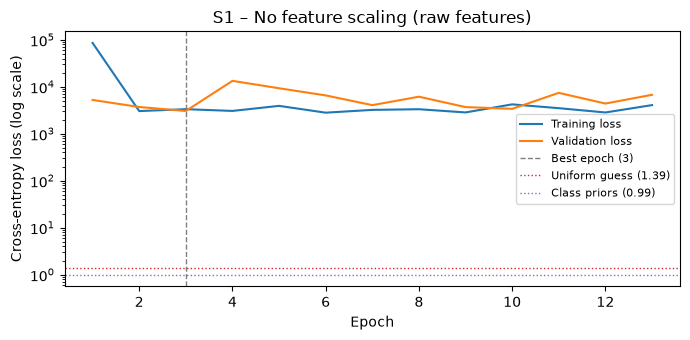

validation: accuracy 0.9096 (trivial 0.6549) | macro-F1 0.6943
              precision    recall  f1-score   support

      Benign      0.912     0.964     0.937      2885
 Brute Force      0.000     0.000     0.000       214
    DoS Hulk      0.835     0.874     0.854       579
    PortScan      0.982     0.990     0.986       727

    accuracy                          0.910      4405
   macro avg      0.682     0.707     0.694      4405
weighted avg      0.869     0.910     0.889      4405



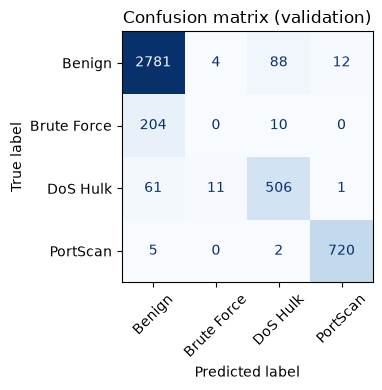

In [18]:
#S1 - NO FEATURE SCALING: raw features (no log1p, no StandardScaler), everything else as R1L
#X_train / X_val are the DataFrames of Task 1 (cleaned and split) before any transformation
X_train_raw_t = torch.tensor(X_train.values, dtype=torch.float32)
X_val_raw_t   = torch.tensor(X_val.values,   dtype=torch.float32)

#size of the inputs: largest raw value vs largest scaled value of the baseline
print("max raw value:", X_train_raw_t.max().item(), "| max |value| R1L:", X_train_log_t.abs().max().item())

#loss and logits of the UNTRAINED network: the first point of the plotted train loss is already an average over
#an epoch of updates, so it hides the real starting loss
def initial_loss(X_t, y_t):
    model = build_model()                                       #untrained network (same seed -> same initial weights)
    with torch.no_grad():                                       #no training: only a forward pass
        logits = model(X_t.to(device))
        loss = nn.CrossEntropyLoss()(logits, y_t.to(device)).item()
    return loss, logits.abs().mean().item()                     #loss and mean |logit|

for name, X_t in [("scaled (R1L)", X_train_log_t), ("raw (S1)", X_train_raw_t)]:
    loss, mean_logit = initial_loss(X_t, y_train_t)
    print(f"initial loss, {name}: {loss:.4g} | mean |logit|: {mean_logit:.4g}")

model_S1 = run_experiment("S1", X_train_raw_t, X_val_raw_t, title="No feature scaling (raw features)")

**S1 – outcome vs hypothesis**

| | R1L | S1 |
|---|---|---|
| initial loss (untrained) | 1.35 | 1.37e6 |
| min val loss | 0.027 | 3059 |
| macro-F1 (val) | 0.988 | 0.694 |
| best epoch / last epoch | 99 / 100 | 3 / 13 |

- *Starting point – right.* The untrained network gives a loss of 1.37e6 and a mean |logit| of 1.18e6 (R1L: 1.35 and 0.18), because the raw features go up to 2.07e9. The first-epoch training loss (8.6e4) is inside the expected 1e3–1e6.
- *Curve – right.* After the first epochs the validation loss stays jagged between 3e3 and 1.3e4, with no convergence and no NaN (Adam bounds the step); early stopping ends the run at epoch 13, with the best epoch at 3.
- *Min val loss – wrong.* We expected it possibly near the class-priors line (0.99); it stays more than three orders of magnitude above it. The network did not collapse to the priors (accuracy 0.910 vs trivial 0.655).
- *Macro-F1 – right.* 0.694, inside the expected 0.5–0.85.
- *Per class.* Brute Force is never detected (recall 0.000) and DoS Hulk drops to recall 0.874, while PortScan is almost unaffected (recall 0.990). A plausible explanation (not tested): PortScan is recognisable from the destination port alone, while Brute Force and DoS Hulk share port 80 with part of Benign and need the size/rate features, which are unusable without scaling.
- *Failure mode: badly conditioned inputs (saturated softmax, unusable loss).* The raw features differ by up to nine orders of magnitude (flags 0/1, Flow Bytes/s up to 2·10⁹). The features with the largest values dominate the hidden pre-activations, so the logits are huge (mean |logit| 1.2·10⁶ before training) and the softmax is saturated: probabilities are 0 or 1, and every misclassified flow costs a loss of the order of its logit margin. AdamW moves each weight by about lr per step: on a feature of order 10⁷ this changes the logits by thousands (no fine-tuning possible), on a 0/1 flag it changes almost nothing (no learning). The result is the curve we see: a fall of more than an order of magnitude in the first epochs, then a jagged plateau around 10³–10⁴, far above the class-priors line, with early stopping picking a lucky epoch.

#### S2 – Far too high learning rate: sweep ×10 until the training breaks

**Why this run:** the learning rate sets the size of every update. We look for the point where the update becomes larger than the region in which the loss is smooth.

**Hypothesis (written before running):**
- *Where it breaks.* Adam moves each weight by about lr per step. With 16 standardised inputs one step changes a hidden pre-activation by up to ~16·lr·|z|. Expected: lr = 1e-2 about as good as R1L (maybe noisier); lr = 1e-1 noisy, worse min val loss but still learning; **lr ≈ 1 broken** (range 0.3–3, about 2000× the baseline); lr = 10 clearly broken.
- *Criterion (fixed now).* A run counts as broken if its min val loss is above 0.31 (roughly 10× R1L) or it has NaN epochs. The first lr of the grid that meets it is the S2 run of the logbook.
- *Curve.* Beyond the breakdown the loss goes up and down in spikes with no smooth descent, or sits flat at or above the class-priors line (0.99) if the ReLU units die and the network only outputs the class frequencies. Probably no NaN, because Adam bounds the step. Early stopping ends the run at about epoch 11, so the curve is short.


=== S2-lr0.01: lr = 0.01 ===
epoch   1 | train loss 0.1564 | val loss 0.0856
epoch  10 | train loss 0.0420 | val loss 0.0373
epoch  20 | train loss 0.0352 | val loss 0.0366
epoch  30 | train loss 0.0352 | val loss 0.0268
epoch  40 | train loss 0.0309 | val loss 0.0270
early stopping at epoch 42: no improvement for 10 epochs
best epoch: 32 (val loss 0.0251) | last epoch: 42 | time: 13.9 s


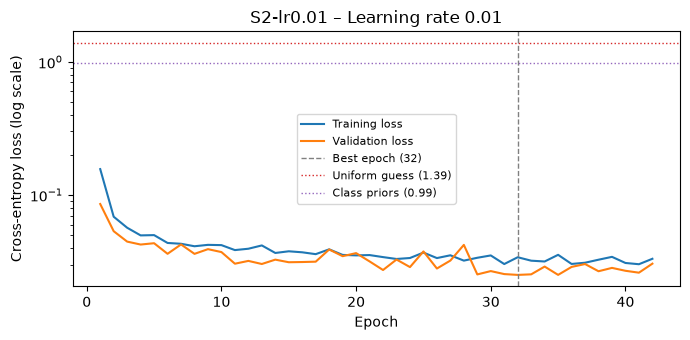

validation: accuracy 0.9934 (trivial 0.6549) | macro-F1 0.9870
              precision    recall  f1-score   support

      Benign      0.997     0.994     0.995      2885
 Brute Force      0.934     1.000     0.966       214
    DoS Hulk      0.990     0.990     0.990       579
    PortScan      1.000     0.993     0.997       727

    accuracy                          0.993      4405
   macro avg      0.980     0.994     0.987      4405
weighted avg      0.994     0.993     0.993      4405



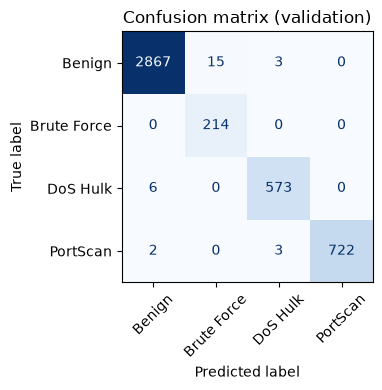


=== S2-lr0.1: lr = 0.1 ===
epoch   1 | train loss 0.1787 | val loss 0.1117
epoch  10 | train loss 0.0856 | val loss 0.1058
early stopping at epoch 17: no improvement for 10 epochs
best epoch: 7 (val loss 0.0621) | last epoch: 17 | time: 5.5 s


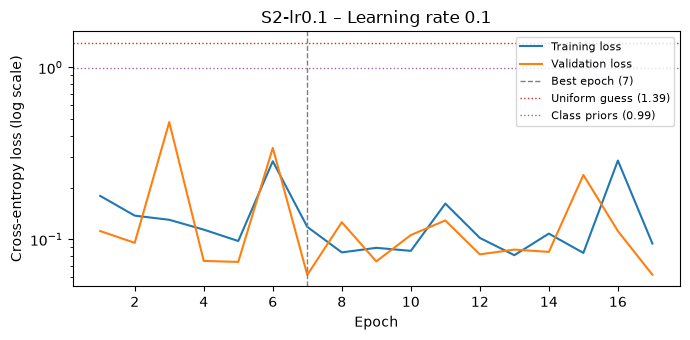

validation: accuracy 0.9875 (trivial 0.6549) | macro-F1 0.9767
              precision    recall  f1-score   support

      Benign      0.995     0.987     0.991      2885
 Brute Force      0.916     0.972     0.943       214
    DoS Hulk      0.963     0.990     0.976       579
    PortScan      1.000     0.993     0.997       727

    accuracy                          0.988      4405
   macro avg      0.969     0.985     0.977      4405
weighted avg      0.988     0.988     0.988      4405



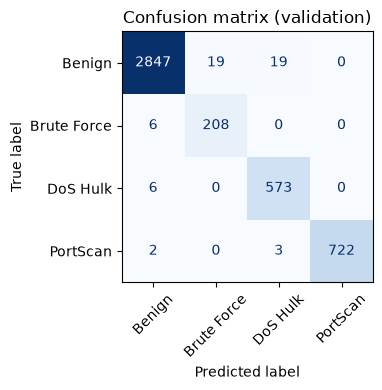


=== S2-lr1: lr = 1 ===
epoch   1 | train loss 4.3650 | val loss 0.1749
epoch  10 | train loss 8.7996 | val loss 16.5687
epoch  20 | train loss 0.2189 | val loss 0.1475
early stopping at epoch 21: no improvement for 10 epochs
best epoch: 11 (val loss 0.1393) | last epoch: 21 | time: 6.6 s


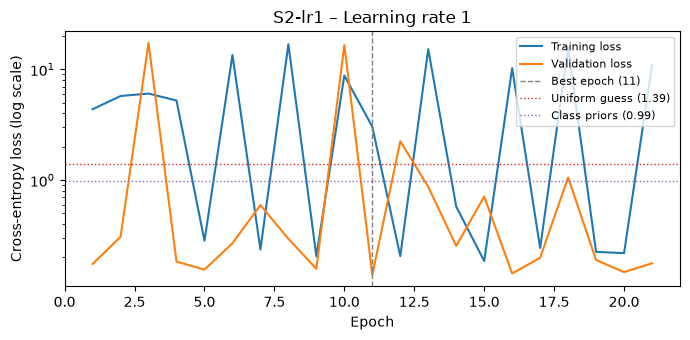

validation: accuracy 0.9507 (trivial 0.6549) | macro-F1 0.9036
              precision    recall  f1-score   support

      Benign      0.967     0.964     0.966      2885
 Brute Force      0.649     0.864     0.741       214
    DoS Hulk      0.996     0.864     0.925       579
    PortScan      0.972     0.993     0.982       727

    accuracy                          0.951      4405
   macro avg      0.896     0.921     0.904      4405
weighted avg      0.956     0.951     0.952      4405



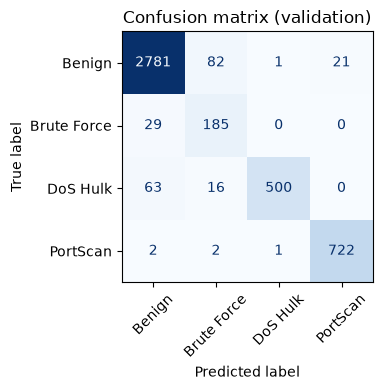


=== S2-lr10: lr = 10 ===
epoch   1 | train loss 388.1683 | val loss 125.5084
epoch  10 | train loss 248.8814 | val loss 150.6639
early stopping at epoch 19: no improvement for 10 epochs
best epoch: 9 (val loss 0.2775) | last epoch: 19 | time: 7.0 s


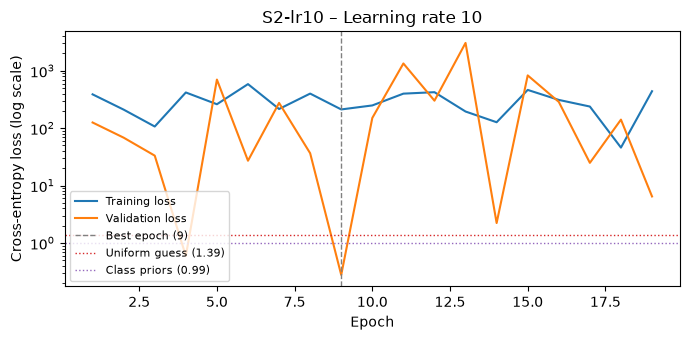

validation: accuracy 0.9369 (trivial 0.6549) | macro-F1 0.9111
              precision    recall  f1-score   support

      Benign      0.950     0.957     0.954      2885
 Brute Force      0.915     0.855     0.884       214
    DoS Hulk      0.817     0.881     0.848       579
    PortScan      0.996     0.924     0.959       727

    accuracy                          0.937      4405
   macro avg      0.920     0.904     0.911      4405
weighted avg      0.939     0.937     0.937      4405



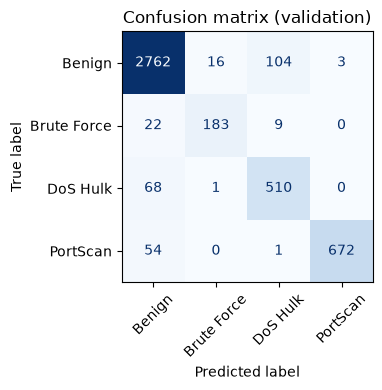


S2 run: lr = 1 (criterion met by no lr)
               run best epoch last epoch min val loss NaN epochs  \
0.0005         R1L         99        100       0.0272          0   
0.0100   S2-lr0.01         32         42       0.0251          0   
0.1000    S2-lr0.1          7         17       0.0621          0   
1.0000      S2-lr1         11         21       0.1393          0   
10.0000    S2-lr10          9         19       0.2775          0   

        val roughness macro-F1  
0.0005         0.0361   0.9875  
0.0100         0.1289    0.987  
0.1000          0.723   0.9767  
1.0000          1.657   0.9036  
10.0000        3.2596   0.9111  


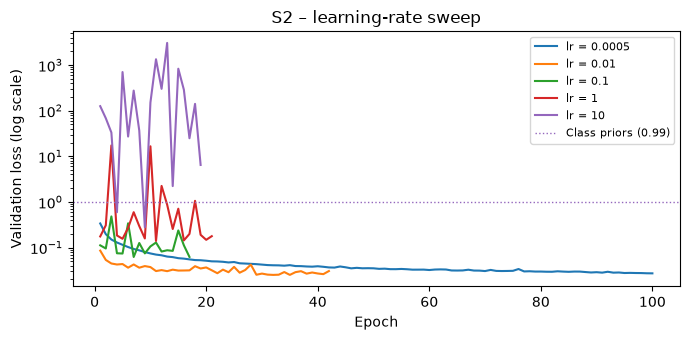

In [19]:
#S2 - TOO HIGH LEARNING RATE: sweep, we multiply the lr by 10 until the training breaks
#every lr is a logged run (it trains a model); the S2 run of the logbook is chosen below by the criterion fixed before the run
LR_GRID   = [1e-2, 1e-1, 1, 10]
SWEEP_IDS = {1e-2: "S2-lr0.01", 1e-1: "S2-lr0.1", 1: "S2-lr1", 10: "S2-lr10"}

for lr_value in LR_GRID:
    print(f"\n=== {SWEEP_IDS[lr_value]}: lr = {lr_value} ===")
    run_experiment(SWEEP_IDS[lr_value], X_train_log_t, X_val_log_t, lr=lr_value, title=f"Learning rate {lr_value}")

#S2 = first lr of the grid that meets the "broken" criterion fixed before the run (min val loss > 0.31 or NaN epochs)
broken = [lr for lr in LR_GRID if runs[SWEEP_IDS[lr]]["curve"]["min val loss"] > 0.31
          or runs[SWEEP_IDS[lr]]["curve"]["NaN epochs"] > 0]
LR_S2 = broken[0] if broken else 1      #if no lr meets it: lr = 1, a choice declared in the outcome
runs["S2"] = runs[SWEEP_IDS[LR_S2]]
print("\nS2 run: lr =", LR_S2, "(criterion met)" if broken else "(criterion met by no lr)")

#table: R1L (lr 5e-4, already trained) + the four runs of the sweep
sweep_rows = {}
for lr_value, rid in [(LR, "R1L")] + [(lr, SWEEP_IDS[lr]) for lr in LR_GRID]:
    r = runs[rid]
    sweep_rows[lr_value] = {"run": rid, "best epoch": r["best_epoch"], "last epoch": r["last_epoch"],
                            "min val loss": round(r["curve"]["min val loss"], 4),
                            "NaN epochs": r["curve"]["NaN epochs"],
                            "val roughness": round(r["curve"]["val roughness"], 4),
                            "macro-F1": round(r["macro_f1"], 4)}
print(pd.DataFrame(sweep_rows).T)

#validation loss of all the learning rates on the same axes (figure for the report)
fig, ax = plt.subplots(figsize=(7, 3.5))
for lr_value, rid in [(LR, "R1L")] + [(lr, SWEEP_IDS[lr]) for lr in LR_GRID]:
    val_loss = runs[rid]["history"]["val_loss"]
    ax.plot(np.arange(1, len(val_loss) + 1), val_loss, label=f"lr = {lr_value}")
ax.axhline(LOSS_PRIORS, color="tab:purple", ls=":", lw=1, label=f"Class priors ({LOSS_PRIORS:.2f})")
ax.set_yscale("log"); ax.set_xlabel("Epoch"); ax.set_ylabel("Validation loss (log scale)")
ax.set_title("S2 – learning-rate sweep"); ax.legend(fontsize=8)
plt.tight_layout(); plt.savefig(os.path.join(FIG_DIR, "S2_lr_sweep_val_loss.png"), dpi=300); plt.show()

**S2 – outcome vs hypothesis**

| lr | min val loss | macro-F1 (val) | val roughness | best / last epoch |
|---|---|---|---|---|
| 5e-4 (R1L) | 0.027 | 0.988 | 0.036 | 99 / 100 |
| 1e-2 | 0.025 | 0.987 | 0.129 | 32 / 42 |
| 1e-1 | 0.062 | 0.977 | 0.723 | 7 / 17 |
| **1** (S2 run) | 0.139 | 0.904 | 1.657 | 11 / 21 |
| 10 | 0.278 | 0.911 | 3.260 | 9 / 19 |

*Val roughness is the mean |change| of ln(val loss) per epoch, so exp(roughness) is the typical jump from one epoch to the next: about ×1.04 for R1L, ×5 for lr = 1, ×26 for lr = 10.*

- *Where it breaks – right on the shape of the curve, wrong on the criterion.* We expected the breakdown at lr ≈ 1 and the curves confirm it: from lr = 1 the first-epoch train loss is above ln(4) (4.37; lr = 10: 388) and the validation loss jumps from 0.18 (epoch 1) to 17 (epoch 3), falls back to 0.18 and jumps to 17 again at epoch 10 (lr = 10: between 0.28 and more than 3,000). But the criterion fixed before the run (min val loss > 0.31) was met by no lr; lr = 10 comes closest (0.278). The reason is that min val loss is the best epoch of a jagged curve, and early stopping restores exactly that lucky epoch. The degradation is gradual in min val loss and in roughness (0.04 → 0.13 → 0.72 → 1.66 → 3.26), while the metrics of the restored model hide part of it: the macro-F1 is not even monotonic (lr = 1: 0.904, lr = 10: 0.911). Since no lr met the criterion, the code designates lr = 1 as the S2 run (rule declared in the code before this run): it is the first lr whose curve shows the breakdown (first-epoch train loss above ln(4), validation spikes up to 17, roughness ×5 per epoch).
- *Lower learning rates – right.* lr = 1e-2 is about as good as R1L (macro-F1 0.987 vs 0.988, min val loss 0.025 vs 0.027) but noisier (roughness 0.13 vs 0.04); lr = 1e-1 is noisier and worse (0.062) but still learning.
- *Curve – right.* Spikes with no smooth descent and no NaN (Adam bounds the step). We also allowed for a flat plateau on the class priors (dead units): it did not happen.
- *Classification degrades less than the loss.* lr = 1 still reaches macro-F1 0.904 and lr = 10 0.911: accuracy and F1 only see the argmax of the restored best epoch, which stays reasonable while the loss explodes. With lr = 1 Brute Force loses recall (1.000 → 0.864) and precision (0.939 → 0.649), DoS Hulk recall falls to 0.864 and Benign recall from 0.993 to 0.964; with lr = 10 DoS Hulk recall falls to 0.881 and PortScan recall to 0.924.
- *Failure mode: overshoot (oscillation with loss spikes).* With lr = 1 one AdamW step moves each weight by about 1, more than the width of the valley around the minimum: the weights are thrown into regions of huge logits, the loss explodes, then the network comes back and the cycle repeats (the sawtooth of the S2 run).
- *Caveat.* The validation metrics of S2 are those of the best epoch (epoch 11), selected on a noisy curve, so they are optimistic.
- *In hindsight, the lr = 1e-2 run was not needed.* The lab text asks to raise the lr until training breaks down, and at 1e-2 nothing breaks: it tells us nothing about the breaking point. Its one lesson (Adam tolerates a much larger lr than 5e-4) is shown again, more cleanly and on the port-free data, by O5 in Task 5C. Starting the sweep at 1e-1 would have saved one run.
- *Lesson.* On jagged curves min val loss is not a reliable breakdown indicator, because it takes the best point of the run; the roughness and the loss of the first epochs are more informative.

#### S3 – Learning rate 100× smaller (5e-6)

**Why this run:** a learning rate that is too small does not break the training, it makes it too slow for the epoch budget.

**Hypothesis (written before running):**
- *Curve.* Smooth and monotonic, no spikes, train ≈ val (gap close to 0). It starts near ln(4) and is **still decreasing at epoch 100**: best epoch = last epoch = 100, early stopping never triggers.
- *How far it gets.* Adam moves each weight by about lr per step, so in 100 epochs (322 steps each) a weight can travel about 100 × 322 × 5e-6 ≈ 0.16. This is the same as R1L in its first epoch (322 × 5e-4 ≈ 0.16). We expect S3 at epoch 100 to look like R1L at epoch 1–2: val loss around 0.3–0.5 (R1L epoch 1: 0.34), macro-F1 clearly below 0.988.
- *Classes.* The rare class is learned last, so Brute Force should have the lowest recall.
- *Diagnosis.* It is not a broken run but an unfinished one: with about 100× more epochs it would reach R1L.

epoch   1 | train loss 1.3367 | val loss 1.3195
epoch  10 | train loss 1.0810 | val loss 1.0639
epoch  20 | train loss 0.8765 | val loss 0.8596
epoch  30 | train loss 0.7291 | val loss 0.7123
epoch  40 | train loss 0.6180 | val loss 0.6012
epoch  50 | train loss 0.5319 | val loss 0.5153
epoch  60 | train loss 0.4659 | val loss 0.4496
epoch  70 | train loss 0.4134 | val loss 0.3974
epoch  80 | train loss 0.3712 | val loss 0.3556
epoch  90 | train loss 0.3368 | val loss 0.3216
epoch 100 | train loss 0.3082 | val loss 0.2934
best epoch: 100 (val loss 0.2934) | last epoch: 100 | time: 32.9 s


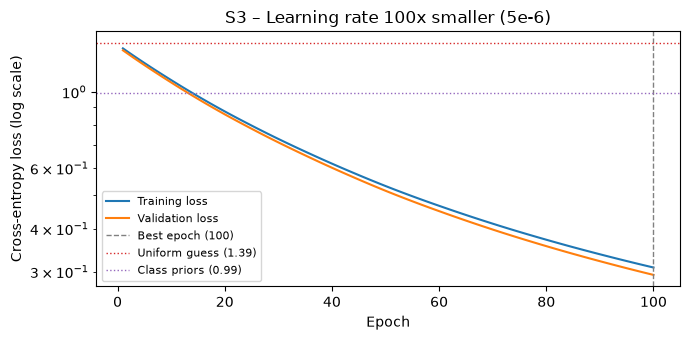

validation: accuracy 0.9442 (trivial 0.6549) | macro-F1 0.9128
              precision    recall  f1-score   support

      Benign      0.951     0.966     0.959      2885
 Brute Force      0.844     0.860     0.852       214
    DoS Hulk      0.973     0.807     0.882       579
    PortScan      0.929     0.990     0.959       727

    accuracy                          0.944      4405
   macro avg      0.924     0.906     0.913      4405
weighted avg      0.945     0.944     0.943      4405



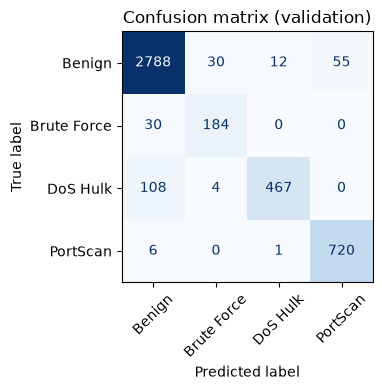

In [20]:
#S3 - TOO LOW LEARNING RATE: 100x smaller than R1L (5e-6), same epoch budget
model_S3 = run_experiment("S3", X_train_log_t, X_val_log_t, lr=LR / 100, title="Learning rate 100x smaller (5e-6)")

**S3 – outcome vs hypothesis**

| | R1L | S3 (lr 5e-6) |
|---|---|---|
| val loss at epoch 1 / 10 / 100 | 0.337 / 0.074 / 0.027 | 1.320 / 1.064 / 0.293 |
| macro-F1 (val) | 0.988 | 0.913 |
| best epoch / last epoch | 99 / 100 | 100 / 100 |
| recall Brute Force / DoS Hulk / PortScan | 1.000 / 0.993 / 0.994 | 0.860 / 0.807 / 0.990 |

- *Curve – right.* Smooth and monotonic, train and validation overlap (gap −0.015 at the best epoch), start near ln(4) (1.34), best epoch = last epoch = 100 and early stopping never triggers: at epoch 100 the loss is still falling.
- *How far it gets – right.* With Adam the weights travel about lr per step, so 100 epochs at 5e-6 cover about the same distance as one epoch of R1L at 5e-4. The final val loss (0.293) is indeed at the level of R1L after its first epoch (0.337).
- *Classes – wrong.* We expected Brute Force, the rarest class, to be learned last. The lowest recall is DoS Hulk (0.807, about 112 flows missed), then Brute Force (0.860). DoS Hulk is also among the weakest classes of R1 (38 flows predicted as Benign; R1L: 4). PortScan is the first class to be learned (recall 0.990), at the price of a lower precision (0.929).
- *Failure mode: underfitting by too slow optimisation (not converged within the epoch budget).* The training is not broken, only unfinished: train ≈ val and the curve is still falling, so the model is limited by the number of updates, not by memorisation or noise. The remedy is one line (more epochs or a larger lr, e.g. the lr = 1e-2 run of the S2 sweep reaches val loss 0.025 in 32 epochs).

                                  R1L          S1       S2        S3
macro-F1                       0.9875      0.6943   0.9036    0.9128
accuracy                       0.9936      0.9096   0.9507    0.9442
best epoch                    99.0000      3.0000  11.0000  100.0000
last epoch                   100.0000     13.0000  21.0000  100.0000
start train loss               0.6472  86142.1984   4.3650    1.3367
start val loss                 0.3370   5258.9493   0.1749    1.3195
min val loss                   0.0272   3058.5143   0.1393    0.2934
NaN epochs                     0.0000      0.0000   0.0000    0.0000
val roughness                  0.0361      0.4963   1.6570    0.0152
train roughness                0.0330      0.4652   2.8148    0.0148
gap at best (val-train)       -0.0022   -285.5191  -2.8986   -0.0149
val slope last 10 ep (%/ep)   -0.5653     12.1302   2.7399   -0.8773


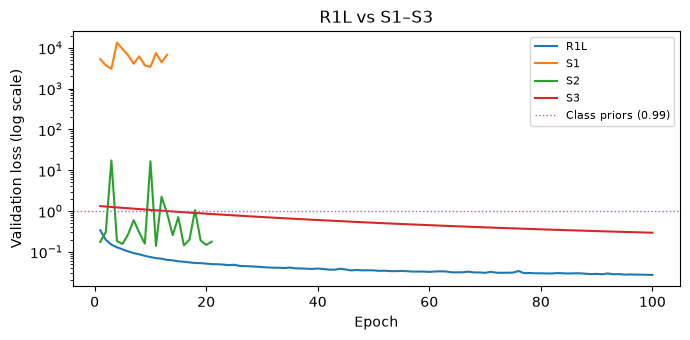

In [21]:
#R1L vs S1, S2, S3: same network, same seed, same batches; each run changes only one thing
summary_rows = {}
for rid in ["R1L", "S1", "S2", "S3"]:
    r = runs[rid]
    summary_rows[rid] = {"macro-F1": r["macro_f1"], "accuracy": r["accuracy"],
                         "best epoch": r["best_epoch"], "last epoch": r["last_epoch"], **r["curve"]}
print(pd.DataFrame(summary_rows).round(4))

#validation loss of the four runs on the same axes (figure for the report)
fig, ax = plt.subplots(figsize=(7, 3.5))
for rid in summary_rows:
    val_loss = runs[rid]["history"]["val_loss"]
    ax.plot(np.arange(1, len(val_loss) + 1), val_loss, label=rid)
ax.axhline(LOSS_PRIORS, color="tab:purple", ls=":", lw=1, label=f"Class priors ({LOSS_PRIORS:.2f})")
ax.set_yscale("log"); ax.set_xlabel("Epoch"); ax.set_ylabel("Validation loss (log scale)")
ax.set_title("R1L vs S1–S3"); ax.legend(fontsize=8)
plt.tight_layout(); plt.savefig(os.path.join(FIG_DIR, "S1_S3_val_loss.png"), dpi=300); plt.show()

**S1–S3 – ranking and symptoms**

| | R1L | S1 (raw) | S2 (lr = 1) | S3 (lr = 5e-6) |
|---|---|---|---|---|
| macro-F1 (val) | 0.988 | 0.694 | 0.904 | 0.913 |
| min val loss | 0.027 | 3059 | 0.139 | 0.293 |
| start train loss | 0.65 | 8.6e4 | 4.37 | 1.34 |
| val roughness | 0.036 | 0.496 | 1.657 | 0.015 |
| val − train at best epoch | −0.002 | −286 | −2.90 | −0.015 |
| val slope, last 10 epochs (%/epoch) | −0.57 | +12.1 | +2.7 | −0.88 |
| usual remedy | – | scale the inputs | lower the lr | raise the lr |

**Q: Rank S1–S3 by how badly they hurt.**
**S1 (worst) > S2 > S3.**
- *S1* is the worst on every measure: the loss is five orders of magnitude above R1L (3059 vs 0.027), the probabilities are meaningless, and the macro-F1 is by far the lowest (0.694) because Brute Force is never detected. We did not test S1 at other learning rates, but the mechanism (every weight moves by about lr, while the raw features differ by nine orders of magnitude) suggests no single lr fits all of them.
- *S2* has a lower min val loss than S3 (0.139 vs 0.293) but also a lower macro-F1 (0.904 vs 0.913), and even these numbers are optimistic: the best epoch (epoch 11) is the luckiest point of a curve that jumps by a factor of about 5 per epoch (spikes from 0.14 to 17) and has no stable stopping point. It is fixed by lowering the lr.
- *S3* is the mildest in nature: the curve is smooth, honest and still falling (−0.88 %/epoch, steeper than R1L's −0.57), the model is just unfinished. We rank S2 above S3 for reliability and recoverability; here the final score agrees (S2 0.904 vs S3 0.913). Raising the lr is the practical fix; more epochs would take of the order of 1e4 epochs by linear scaling.

**Q: Which fundamental first on a new problem?** The **scaling**.
- It can be checked before training (input ranges, loss of the untrained network: 1.37e6 for raw vs 1.35 for scaled).
- With scaled inputs the usable learning-rate window is wide: from 5e-4 to 1e-1 the macro-F1 stays ≥ 0.977 (a factor of 200), so a quick sweep finds a good lr; with raw inputs the problem is there at step zero.
- It is also the error that hurts most here: S1 is the only run that loses a whole class (Brute Force recall 0.000).

**Q (reading symptoms): what in the shape of the curve points to the cause?**
1. *Level.* A loss that starts orders of magnitude above ln(4) and **never comes back down** towards ln(4) and the priors (S1: about 3·10³–1.3·10⁴ for the whole run) points to unscaled inputs. A high start that falls within a few epochs (the lr = 10 run of the sweep: from 388 to a best of 0.28 at epoch 9, with spikes above 1,000 in between) points to the lr instead.
2. *Shape.* Spikes of several orders of magnitude, with the loss returning to good values between them (S2: from 0.18 at epoch 1 to 17 at epoch 3, back to 0.18 and to 17 again at epoch 10; the lr = 10 run goes up and down between 0.28 and more than 3,000), point to an lr that is too high. A smooth, monotonic curve with train ≈ val, starting at ln(4) (1.34) and still falling at the last epoch (S3) points to an lr that is too low or to too few epochs.
3. *Gap.* A strongly negative val − train gap (S1: −286, S2: −2.9) shows that the weights move too much within an epoch: the training loss is averaged while the weights change, the validation loss is computed at the end of the epoch, so large jumps during the epoch inflate the training loss only. A gap close to zero (R1L −0.002, S3 −0.015) does not.
4. *Limits.* Smoothness is not health (S3 is smoother than R1L and has a worse model). A curve that is only slow is ambiguous between a too-small lr and a slowly learning model: the discriminating sign is a slope that is still clearly negative when the budget ends.

## 2C – Locking in the baseline

#### R2 – R1L with up to 200 epochs (same network, seed, lr 5e-4, batch 64, patience 10; only the epoch cap changes)

**Why this run:** R1L ends at the 100-epoch cap with its best epoch at 99 and the validation loss still falling (−0.57 %/epoch over the last 10 epochs): its training is limited by the epoch budget, not by early stopping. A "well-tuned" baseline must have converged. We change the epoch cap rather than the lr: the S2 sweep shows that lr 1e-2 reaches a slightly lower minimum (0.025 vs 0.027) but on a curve about 3.6× rougher (roughness 0.129 vs 0.036), so its best epoch is partly luck. A longer run at 5e-4 asks the same question (is there a lower minimum?) without the noise.

**Hypothesis (written before running):**
- *Same start.* Same seed and same batches: the first 100 epochs of R2 coincide with R1L (best val loss 0.0273 at epoch 99 so far; min val loss 0.0272).
- *Curves.* After epoch 100 the validation loss keeps falling, more slowly: min val loss between 0.019 and 0.0245 (10–30% below R1L), best epoch between 120 and 200. Early stopping may trigger before 200: near the end the gain per epoch gets close to MIN_DELTA (1e-4). The train/val gap opens slightly but stays below 0.01: 1,348 parameters cannot memorise 20,559 flows.
- *Metrics.* Small macro-F1 gain (+0.000 to +0.005), within the noise of one seed (28 misclassified validation flows in R1L; one flow ≈ 0.02% accuracy). The error that should shrink the most is Benign → Brute Force (14 flows in R1L).
- *Criterion (fixed now).* R2 replaces R1L as the baseline if the min val loss falls by at least 10% (≤ 0.0245) and no class loses more than 0.01 of recall (two Brute Force flows). Otherwise R1L stays the baseline: simpler and cheaper, with the final slope documented as evidence of "converged enough". Expected outcome: R2 adopted.

epoch   1 | train loss 0.6472 | val loss 0.3370
epoch  10 | train loss 0.0831 | val loss 0.0742
epoch  20 | train loss 0.0545 | val loss 0.0514
epoch  30 | train loss 0.0450 | val loss 0.0422
epoch  40 | train loss 0.0396 | val loss 0.0389
epoch  50 | train loss 0.0362 | val loss 0.0350
epoch  60 | train loss 0.0340 | val loss 0.0321
epoch  70 | train loss 0.0328 | val loss 0.0305
epoch  80 | train loss 0.0314 | val loss 0.0297
epoch  90 | train loss 0.0303 | val loss 0.0288
epoch 100 | train loss 0.0292 | val loss 0.0272
epoch 110 | train loss 0.0284 | val loss 0.0269
epoch 120 | train loss 0.0279 | val loss 0.0258
epoch 130 | train loss 0.0274 | val loss 0.0245
epoch 140 | train loss 0.0268 | val loss 0.0242
epoch 150 | train loss 0.0263 | val loss 0.0239
epoch 160 | train loss 0.0261 | val loss 0.0238
early stopping at epoch 168: no improvement for 10 epochs
best epoch: 158 (val loss 0.0232) | last epoch: 168 | time: 55.2 s


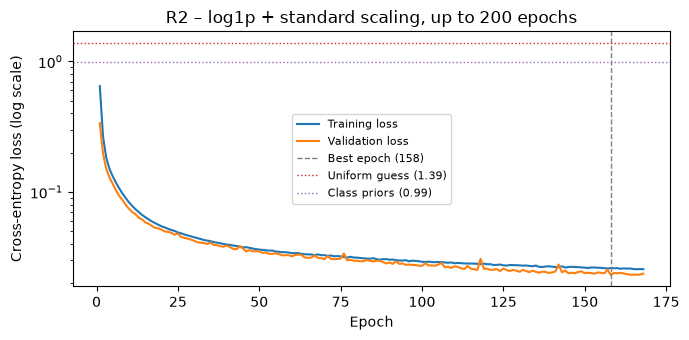

validation: accuracy 0.9948 (trivial 0.6549) | macro-F1 0.9894
              precision    recall  f1-score   support

      Benign      0.999     0.994     0.997      2885
 Brute Force      0.947     1.000     0.973       214
    DoS Hulk      0.988     0.993     0.991       579
    PortScan      1.000     0.996     0.998       727

    accuracy                          0.995      4405
   macro avg      0.983     0.996     0.989      4405
weighted avg      0.995     0.995     0.995      4405



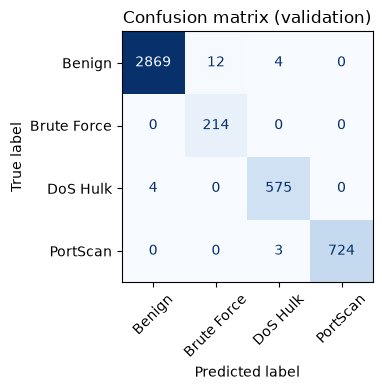

                              R1L        R2
macro-F1                   0.9875    0.9894
recall Benign              0.9931    0.9945
recall Brute Force         1.0000    1.0000
recall DoS Hulk            0.9931    0.9931
recall PortScan            0.9945    0.9959
best epoch                99.0000  158.0000
last epoch               100.0000  168.0000
min val loss               0.0272    0.0232
val loss @100              0.0272    0.0272
gap at best (val-train)   -0.0022   -0.0030
min val loss -14.8% | max recall loss 0.000 -> baseline: R2


In [22]:
#R2 - R1L WITH UP TO 200 EPOCHS (same as R1L, only the epoch cap changes)
model_R2 = run_experiment("R2", X_train_log_t, X_val_log_t, title="log1p + standard scaling, up to 200 epochs", num_epochs=200)

#R1L vs R2: same network, seed and batches; the only difference is the epoch cap (val_at is defined in the R1 vs R1L comparison cell)
rows = {}
for rid in ["R1L", "R2"]:
    r = runs[rid]
    rows[rid] = {"macro-F1": r["macro_f1"],
                 **{f"recall {c}": r["recall"][c] for c in le.classes_},
                 "best epoch": r["best_epoch"], "last epoch": r["last_epoch"],
                 "min val loss": min(r["history"]["val_loss"]),
                 "val loss @100": val_at(rid, 100),
                 "gap at best (val-train)": r["curve"]["gap at best (val-train)"]}
print(pd.DataFrame(rows).round(4))

#decision (criterion fixed before the run): R2 replaces R1L if the min val loss falls by at least 10%
#and no class loses more than 0.01 of recall
gain = 1 - runs["R2"]["curve"]["min val loss"] / runs["R1L"]["curve"]["min val loss"]
max_recall_loss = max(runs["R1L"]["recall"][c] - runs["R2"]["recall"][c] for c in le.classes_)
BASELINE_ID = "R2" if (gain >= 0.10 and max_recall_loss <= 0.01) else "R1L"
print(f"min val loss -{gain:.1%} | max recall loss {max_recall_loss:.3f} -> baseline: {BASELINE_ID}")


**R2 – outcome vs hypothesis and decision**

| | R1L (cap 100) | R2 (cap 200) |
|---|---|---|
| best epoch / last epoch | 99 / 100 | 158 / 168 |
| min val loss | 0.0272 | 0.0232 |
| macro-F1 (val) | 0.9875 | 0.9894 |
| misclassified val flows | 28 | 23 |

- *Reproducibility – right.* Same seed, same initial weights and same batches: the first 100 epochs of R2 coincide with R1L to four decimals (training and validation loss). The two runs differ only after epoch 100.
- *Curves – right.* After epoch 100 the validation loss keeps falling slowly (0.0272 → 0.0232, −14.8%, inside the expected 0.019–0.0245); the best epoch is 158 (expected 120–200) and early stopping ends the run at epoch 168, before the cap. The train/val gap stays tiny (−0.003 at the best epoch).
- *Metrics – right.* Macro-F1 +0.0019 (expected +0.000 to +0.005); no class loses recall (Benign 0.993 → 0.994, PortScan 0.994 → 0.996, the others unchanged). The errors go from 28 to 23: the Benign errors from 20 to 16, with the Brute Force false positives from 14 to 12 (DoS Hulk false positives from 6 to 4), and the PortScan errors from 4 to 3, so the expected shrink of Benign → Brute Force is there but very small.
- *Decision (criterion fixed before the run).* The min val loss falls by 14.8% (threshold 10%) and no class loses recall: **R2 replaces R1L as the baseline** (the code sets `BASELINE_ID` from the same criterion). R1L at 100 epochs had not converged; R2 has (early stopping at 168 with a 200 cap).

#### R3 – R1L with a linear hidden layer (no activation); everything else as R1L

**Why this run:** it shows what the non-linearity buys. It starts from R1L (one change: the activation). R2 differs from R1L only by the epoch cap, and a linear model is expected to stop well before epoch 100, so the comparison also holds against R2. Without activation the hidden layer collapses: logits = W2(W1·x + b1) + b2 = (W2·W1)·x + const, a single linear map from 16 features to 4 scores (softmax regression). The 1,348 parameters are not extra capacity: the model has only 16×4 + 4 = 68 effective parameters.

**Hypothesis (written before running):**
- *Curves.* Smooth, train ≈ val (a model that cannot fit more than a hyperplane does not overfit), reaching a plateau well above the ReLU curve: min val loss between 0.10 and 0.30 (R1L: 0.027). Early stopping before epoch 100 is likely.
- *Metrics.* Macro-F1 clearly below R1L: between 0.85 and 0.93 (R1L: 0.988), a drop of at least 0.05.
- *Per class: the biggest change on Brute Force and DoS Hulk.* All their flows are on port 80, while Benign has port 80 (10.7% of its training flows) but also 53 and 443. A linear score is monotonic in the port and 80 lies between 53 and 443 (log1p: 4.0, 4.4, 6.1), so no hyperplane can single out "port ≈ 80" on the port alone: it has to come from other features. We expect more Benign port-80 flows predicted as Brute Force or DoS Hulk, with Brute Force precision below 0.80 (R1L: 0.939). For PortScan we do not have a clear expectation.
- *Criterion (fixed now).* ReLU stays the baseline unless the linear model loses less than 0.005 of validation macro-F1; the choice is made on validation only. We expect a loss of at least 0.05.

epoch   1 | train loss 0.6656 | val loss 0.3472
epoch  10 | train loss 0.1905 | val loss 0.1679
epoch  20 | train loss 0.1626 | val loss 0.1455
epoch  30 | train loss 0.1514 | val loss 0.1352
epoch  40 | train loss 0.1458 | val loss 0.1350
epoch  50 | train loss 0.1420 | val loss 0.1327
early stopping at epoch 52: no improvement for 10 epochs
best epoch: 42 (val loss 0.1306) | last epoch: 52 | time: 18.3 s


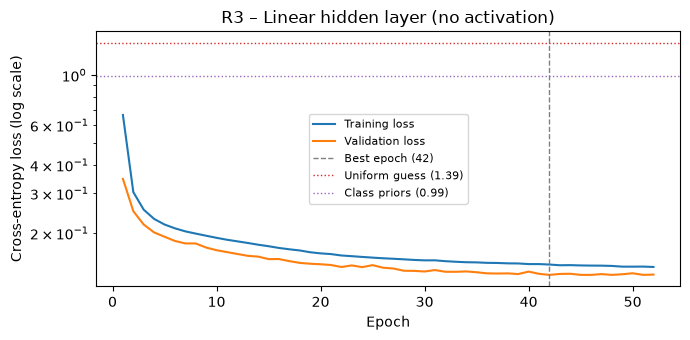

validation: accuracy 0.9662 (trivial 0.6549) | macro-F1 0.9308
              precision    recall  f1-score   support

      Benign      0.979     0.979     0.979      2885
 Brute Force      0.803     0.860     0.831       214
    DoS Hulk      0.936     0.908     0.922       579
    PortScan      0.992     0.992     0.992       727

    accuracy                          0.966      4405
   macro avg      0.927     0.935     0.931      4405
weighted avg      0.967     0.966     0.966      4405



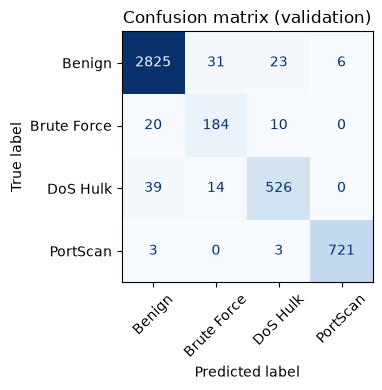

                            R1L       R3
accuracy                 0.9936   0.9662
macro-F1                 0.9875   0.9308
recall Benign            0.9931   0.9792
recall Brute Force       1.0000   0.8598
recall DoS Hulk          0.9931   0.9085
recall PortScan          0.9945   0.9917
precision Benign         0.9983   0.9785
precision Brute Force    0.9386   0.8035
precision DoS Hulk       0.9846   0.9359
precision PortScan       1.0000   0.9917
min val loss             0.0272   0.1306
best epoch              99.0000  42.0000
last epoch             100.0000  52.0000


In [23]:
#R3 - SAME AS R1L, WITH A LINEAR HIDDEN LAYER
#nn.Identity() returns its input unchanged: the two linear layers collapse into a single linear map
model_R3 = run_experiment("R3", X_train_log_t, X_val_log_t, activation=nn.Identity(), title="Linear hidden layer (no activation)")

#R1L (ReLU) vs R3 (linear): same data, seed, batches and lr; the only difference is the activation
rows = {}
for rid in ["R1L", "R3"]:
    r = runs[rid]
    rows[rid] = {"accuracy": r["accuracy"], "macro-F1": r["macro_f1"],
                 **{f"recall {c}": r["recall"][c] for c in le.classes_},
                 **{f"precision {c}": r["precision"][c] for c in le.classes_},
                 "min val loss": min(r["history"]["val_loss"]), "best epoch": r["best_epoch"], "last epoch": r["last_epoch"]}
print(pd.DataFrame(rows).round(4))

In [24]:
#R3 ERROR ANALYSIS (analysis of the trained R3 model, not a new run): who is confused with whom, and on which port
err_3 = pd.DataFrame({"true": le.classes_[y_val_encoded],
                      "pred": le.classes_[runs["R3"]["y_pred"]],
                      "port": X_val["Destination Port"].values})
wrong_3 = err_3[err_3["true"] != err_3["pred"]]
print("misclassified validation flows: R1L", len(wrong_L), "| R3", len(wrong_3), "of", len(err_3))
print(pd.crosstab(wrong_3["true"], wrong_3["pred"]), "\n")

#errors among the three classes that share port 80: how many are on port 80?
port80_classes = ["Benign", "Brute Force", "DoS Hulk"]
mix = wrong_3[wrong_3["true"].isin(port80_classes) & wrong_3["pred"].isin(port80_classes)]
print(f"errors among Benign / Brute Force / DoS Hulk: {len(mix)}, on port 80: {(mix['port'] == 80).sum()}")

misclassified validation flows: R1L 28 | R3 149 of 4405
pred         Benign  Brute Force  DoS Hulk  PortScan
true                                                
Benign            0           31        23         6
Brute Force      20            0        10         0
DoS Hulk         39           14         0         0
PortScan          3            0         3         0 

errors among Benign / Brute Force / DoS Hulk: 137, on port 80: 123


**R3 – outcome vs hypothesis and decision**

| | R1L (ReLU) | R3 (linear) |
|---|---|---|
| min val loss | 0.027 | 0.131 |
| macro-F1 (val) | 0.988 | 0.931 |
| recall Brute Force / DoS Hulk / PortScan | 1.000 / 0.993 / 0.994 | 0.860 / 0.908 / 0.992 |
| precision Brute Force / DoS Hulk / PortScan | 0.939 / 0.985 / 1.000 | 0.803 / 0.936 / 0.992 |
| best epoch / last epoch | 99 / 100 | 42 / 52 |

- *Curves – right.* Smooth, train and validation close, plateau at val loss 0.131 (expected 0.10–0.30), early stopping at epoch 52. Since R3 stops at epoch 52, the 100- or 200-epoch cap plays no role: the comparison holds against R2 too (macro-F1 0.989).
- *Metrics – mostly right.* Macro-F1 0.931, 0.057 below R1L (expected a drop of at least 0.05), just above the expected range 0.85–0.93.
- *Per class – right on where, partly wrong on how.* The largest changes are on the two classes that live entirely on port 80: Brute Force (recall 1.000 → 0.860, precision 0.939 → 0.803) and DoS Hulk (recall 0.993 → 0.908, precision 0.985 → 0.936); PortScan barely moves (6 errors). More Benign flows are flagged as attacks (31 as Brute Force, 23 as DoS Hulk; R1L: 14 and 6), as expected, but Brute Force precision stays just above the 0.80 we predicted (0.803). The hypothesis missed the recall losses: 20 Brute Force and 39 DoS Hulk flows are predicted as Benign (R1L: 0 and 4) and the two attacks are mixed with each other (10 and 14 flows). The classes that mix are exactly those sharing port 80, and the port check confirms it: 123 of the 137 errors among Benign, Brute Force and DoS Hulk are on port 80. This fits the explanation that no hyperplane isolates "port ≈ 80" from the other features.
- *What each fundamental buys.* ReLU without log1p (R1) reached macro-F1 0.937 and linear with log1p (R3) 0.931, against 0.988 with both: removing either costs about 0.05–0.06 (two single changes from different starting points, not a full factorial design).
- *Decision (criterion fixed before the run).* The linear model loses 0.057 of macro-F1, far above the 0.005 threshold: **ReLU stays.** The baseline remains the ReLU model chosen above (R2).

**Q: Does the activation change the per-class behaviour?**
Yes, and not uniformly. The loss is concentrated on Brute Force and DoS Hulk (recall −0.14 and −0.08, precision −0.14 and −0.05), the classes whose separation from Benign on port 80 needs a non-monotonic rule; PortScan (recall −0.003) and Benign (recall −0.014) are almost unaffected.

**Q: Would it be fair to compare ReLU and linear on the test set?**
No: the test set is off-limits for choosing between them. If the test result decides which model we keep, the test set stops being an independent sample: the score reported for the winner is the best of several tries on the same data, so it is optimistically biased, and nothing is left to estimate the performance on truly new flows. The choice belongs to the validation set, which is there for this purpose, and the test set is used once, on the model already chosen. Here the test could not change the decision anyway: the validation gap (0.057 of macro-F1; 149 errors against 28) is far larger than the noise of one seed.

#### Baseline on the test set – does it generalise?

**Why this step:** the test set has not been used for any choice so far (preprocessing, learning rate, epochs and activation were all decided on validation). It is evaluated once, on the chosen baseline (R2, selected by the criterion of 2C and stored in `BASELINE_ID`), to estimate performance on new flows. Evaluating a trained model is not a new run.

**Hypothesis (written before running):**
- *Overall.* Test macro-F1 within ±0.01 of validation (0.9894), more likely slightly lower (−0.002 to −0.008): the best epoch was selected on the validation set, which gives a small optimistic bias, and the model has only 1,348 parameters for 20,559 training flows, so a large gap is unlikely. Accuracy about 0.99 (validation 0.9948). Test and validation are stratified, so the class proportions are the same.
- *Per class.* Brute Force is the noisiest class: with 214 flows one flow is 0.5% of recall and the precision rests on about 12 false positives. We expect recall between 0.97 and 1.00 and precision between 0.88 and 0.96 (validation: 1.000 and 0.947). DoS Hulk and PortScan within ±0.01, Benign within ±0.005.
- *Errors.* Same pattern as validation: the main error is Benign flows predicted as Brute Force or DoS Hulk.
- *Criterion (fixed now).* The baseline generalises if the macro-F1 gap is at most 0.01 and no class has a recall gap above 0.03.

max |z| train / val / test: 8.5 / 10.8 / 5.6
validation: accuracy 0.9948 (trivial 0.6549) | macro-F1 0.9894
              precision    recall  f1-score   support

      Benign      0.999     0.994     0.997      2885
 Brute Force      0.947     1.000     0.973       214
    DoS Hulk      0.988     0.993     0.991       579
    PortScan      1.000     0.996     0.998       727

    accuracy                          0.995      4405
   macro avg      0.983     0.996     0.989      4405
weighted avg      0.995     0.995     0.995      4405



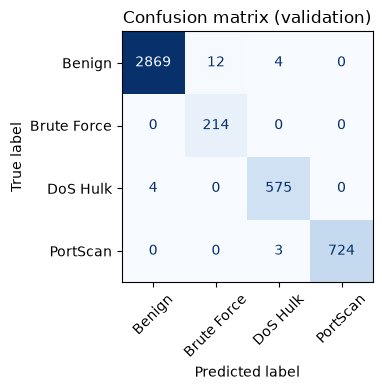

test: accuracy 0.9927 (trivial 0.6548) | macro-F1 0.9847
              precision    recall  f1-score   support

      Benign      0.999     0.990     0.995      2885
 Brute Force      0.918     0.995     0.955       214
    DoS Hulk      0.983     0.998     0.991       579
    PortScan      1.000     0.997     0.999       728

    accuracy                          0.993      4406
   macro avg      0.975     0.995     0.985      4406
weighted avg      0.993     0.993     0.993      4406



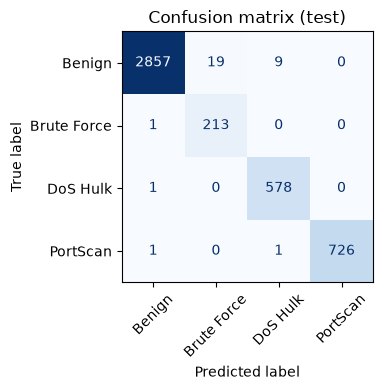

             recall val  recall test  precision val  precision test  \
Benign            0.994        0.990          0.999           0.999   
Brute Force       1.000        0.995          0.947           0.918   
DoS Hulk          0.993        0.998          0.988           0.983   
PortScan          0.996        0.997          1.000           1.000   

             recall gap  precision gap  
Benign           -0.004          0.000  
Brute Force      -0.005         -0.029  
DoS Hulk          0.005         -0.005  
PortScan          0.001          0.000  
macro-F1 val 0.9894 | test 0.9847 | gap -0.0047


In [25]:
#TEST SET: used here for the first and only time, on the chosen baseline (BASELINE_ID, decided in the R2 cell)
#same transformation as the validation set: log1p, then the scaler fitted on the TRAINING set only (scaler_log)
X_test_log_t = torch.tensor(scaler_log.transform(np.log1p(X_test)), dtype=torch.float32)
print(f"max |z| train / val / test: {X_train_log_t.abs().max().item():.1f} / "
      f"{X_val_log_t.abs().max().item():.1f} / {X_test_log_t.abs().max().item():.1f}")

#classification reports and confusion matrices of the baseline on validation and test (they do NOT train)
baseline_model = runs[BASELINE_ID]["model"]                     #baseline chosen in 2C (R1L or R2): weights of its best epoch
val_report  = evaluate(baseline_model, X_val_log_t,  y_val_t,  "validation", filename="baseline_cm_val.png")
test_report = evaluate(baseline_model, X_test_log_t, y_test_t, "test",       filename="baseline_cm_test.png")

#validation vs test per class (negative gap = test worse than validation)
gap = pd.DataFrame({"recall val": val_report["recall"], "recall test": test_report["recall"],
                    "precision val": val_report["precision"], "precision test": test_report["precision"]})
gap["recall gap"]    = gap["recall test"] - gap["recall val"]
gap["precision gap"] = gap["precision test"] - gap["precision val"]
print(gap.round(3))
print(f"macro-F1 val {val_report['macro_f1']:.4f} | test {test_report['macro_f1']:.4f} | gap {test_report['macro_f1'] - val_report['macro_f1']:+.4f}")

**Baseline (R2) – validation vs test**

| | validation | test |
|---|---|---|
| accuracy | 0.9948 | 0.9927 |
| macro-F1 | 0.9894 | 0.9847 |
| misclassified flows | 23 | 32 |
| recall Benign / Brute Force / DoS Hulk / PortScan | 0.994 / 1.000 / 0.993 / 0.996 | 0.990 / 0.995 / 0.998 / 0.997 |
| precision Benign / Brute Force / DoS Hulk / PortScan | 0.999 / 0.947 / 0.988 / 1.000 | 0.999 / 0.918 / 0.983 / 1.000 |

- *Overall – right.* Macro-F1 gap −0.0047, inside the ±0.01 we set and inside the expected −0.002 to −0.008; accuracy 0.9927 (expected about 0.99).
- *Per class – right.* Brute Force recall 0.995 (one flow missed) and precision 0.918, inside the expected 0.97–1.00 and 0.88–0.96. All the other recall gaps are at most 0.005 and the other precision gaps at most 0.005.
- *Errors – right.* Same pattern as validation: the main error is Benign flows predicted as Brute Force (19; validation: 12) or DoS Hulk (9; validation: 4). The largest gap of the table, Brute Force precision −0.029, is these 7 extra false positives on a class of 214 flows. The other errors are single flows (one Brute Force, one DoS Hulk and one PortScan predicted as Benign, one PortScan as DoS Hulk).
- *Criterion – met.* Macro-F1 gap 0.0047 (threshold 0.01), largest recall gap 0.005 (threshold 0.03).
- *Input range.* Max |z| on test is 5.6, inside the training range (8.5): after log1p no test input falls outside what the network saw (with standard scaling alone Task 1 had 85 / 504 / 41.5 on train / val / test).

**Q: Compare validation vs test. Does the baseline generalise?**
Yes. The macro-F1 gap is −0.0047 and the accuracy gap −0.0021, every per-class recall gap is at most 0.005, and the errors are 23 vs 32 flows, a difference of a few flows that is of the order of the sampling noise. This is what we expect from a model with 1,348 parameters trained on 20,559 flows (train/val loss gap −0.003 at the best epoch) and whose only selection on validation was the best epoch and the epoch cap, on top of choices (log1p, activation) with effects about ten times larger than any selection bias. The weakest point is the Brute Force precision (0.918): the false positives are Benign flows, the same weakness found in Task 2A, and Task 3 examines where it comes from. Limits: one seed and one split. The test set is now spent: any further choice must be made on validation.

## Task 3 – When a feature biases the model

### 3.1 Is "Brute Force always on port 80" a property of the attack?

**It is an artefact of the dataset, not a property of brute-force attacks.**
- *Why.* Brute force is a technique (trying many credentials against an authentication service), not a protocol: the same attack runs against SSH (22), FTP (21), RDP (3389), databases or web logins on 80, 443, 8080, 8443... Nothing in the attack makes port 80 special. In our data the class looks like a single scenario of a single lab capture, so the port is constant: in the training set Brute Force uses 1 distinct port (100% on port 80), while Benign uses 2,595 different ports (10.7% on port 80) and PortScan 967. DoS Hulk is also 100% on port 80.
- *What the model is likely to learn.* A shortcut: "not on port 80 → not Brute Force". The port is one clean feature that separates Brute Force from the 89.3% of Benign flows that are not on port 80 and from all PortScan flows, so gradient descent has every reason to use it, and the validation score cannot tell us whether the model learned the attack or the port. Consequences: (i) Benign web traffic on port 80 is flagged as Brute Force, (ii) a real brute-force attack on another port is missed, (iii) the scores of Task 2 overestimate the detection we would get on real traffic.
- *Evidence already in the notebook.* In the error analysis the model flags Benign flows as Brute Force only on port 80: 13.8% (R1) and 4.5% (R1L) of the 311 Benign validation flows on port 80, against 0.0% of the 2,574 Benign flows on other ports; all 43 false positives of R1 are on port 80. The counterfactual of 3.2 tests the opposite direction (attack off port 80).

### 3.2 Counterfactual: Brute Force flows moved from port 80 to 8080

**Why this experiment:** it separates "the model recognises brute-force behaviour" from "the model recognises port 80". In the test set only, the destination port of the Brute Force flows goes from 80 to 8080. The other 15 features and all the other flows stay the same, and the baseline chosen in 2C (R2: log1p + scaler fitted on the training set) is used with no retraining, so any change in the predictions is caused by the port alone. This is an evaluation of an already-trained model, not a new run.

**Hypothesis (written before running):**
- *Brute Force recall collapses.* From 0.995 on the test set to below 0.30 (best guess: below 0.10). The model never predicted Brute Force off port 80 (0.0% of the 2,574 Benign validation flows on other ports, in R1 and R1L), and no Brute Force flow off port 80 was ever seen in training: the moved flows fall in a region of the input space where the network has no Brute Force example.
- *Where the flows go: mostly to Benign* (at least 80% of the 214). Benign is the natural destination: it is 65% of the training data and the class with the most ports (2,595), so a flow with web-like features on an unusual port looks like Benign to the network.
- *Other classes.* Recall of Benign, DoS Hulk and PortScan unchanged (their flows are not touched). Benign precision falls from 0.999 to about 0.93 because it absorbs the Brute Force flows; Brute Force precision stays near 0.9 or becomes meaningless if almost no flow is predicted. Macro-F1 falls from 0.985 to about 0.73–0.85.
- *What would prove us wrong.* A Brute Force recall above 0.9 would mean that the network recognises the attack from the other 15 features, and that the port is not what it relies on.

Brute Force flows in test: 214 | on port 80: 214
training flows on port 8080: {'Benign': 4, 'PortScan': 3}
port 80: z-score -0.65
port 8080: z-score 1.24
baseline: R2
test (Brute Force on port 8080): accuracy 0.9444 (trivial 0.6548) | macro-F1 0.7371
              precision    recall  f1-score   support

      Benign      0.930     0.990     0.959      2885
 Brute Force      0.000     0.000     0.000       214
    DoS Hulk      0.983     0.998     0.991       579
    PortScan      1.000     0.997     0.999       728

    accuracy                          0.944      4406
   macro avg      0.728     0.746     0.737      4406
weighted avg      0.903     0.944     0.923      4406



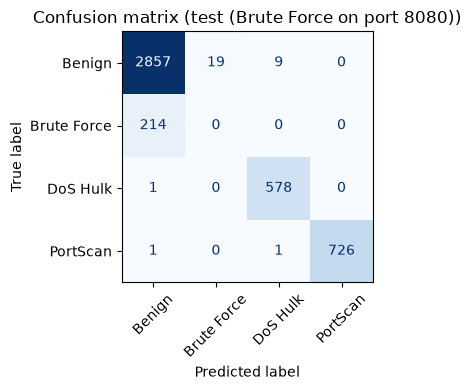

Benign    214
Name: count, dtype: int64


In [26]:
#3.2 COUNTERFACTUAL: move the Brute Force flows of the TEST set from port 80 to 8080 (no retraining)
X_test_cf = X_test.copy()                                              #copy: the real test set stays untouched
is_brute_force = (y_test == "Brute Force")                             #True for the Brute Force flows (true labels)
print("Brute Force flows in test:", is_brute_force.sum(), "| on port 80:", (X_test_cf.loc[is_brute_force, "Destination Port"] == 80).sum())
X_test_cf.loc[is_brute_force, "Destination Port"] = 8080               #only the port changes

#same preprocessing as the baseline: log1p, then the scaler fitted on the TRAINING set (scaler_log)
X_test_cf_t = torch.tensor(scaler_log.transform(np.log1p(X_test_cf)), dtype=torch.float32)

#is 8080 a value the network has seen? training flows on port 8080, per class
print("training flows on port 8080:", pd.Series(y_train[(X_train["Destination Port"] == 8080).values]).value_counts().to_dict())

#size of the change in the units the network sees: z-score of port 80 and of port 8080
port_col = X_train.columns.get_loc("Destination Port")
for port in [80, 8080]:
    z = (np.log1p(port) - scaler_log.mean_[port_col]) / scaler_log.scale_[port_col]
    print(f"port {port}: z-score {z:.2f}")

#inference only: the baseline chosen in 2C (BASELINE_ID) is not trained again
print("baseline:", BASELINE_ID)
cf_report = evaluate(runs[BASELINE_ID]["model"], X_test_cf_t, y_test_t, "test (Brute Force on port 8080)", filename="task3_cm_counterfactual.png")

#where did the Brute Force flows go?
print(pd.Series(le.classes_[cf_report["y_pred"][is_brute_force]]).value_counts())

**3.2 – outcome vs hypothesis**

| | original test (R2) | Brute Force on port 8080 |
|---|---|---|
| Brute Force recall / precision | 0.995 / 0.918 | 0.000 / 0.000 |
| Benign recall / precision | 0.990 / 0.999 | 0.990 / 0.930 |
| macro-F1 / accuracy | 0.985 / 0.993 | 0.737 / 0.944 |
| where the 214 Brute Force flows go | Brute Force: 213, Benign: 1 | Benign: 214 |

*Note: the hypothesis was written when the baseline was still R1L; the counterfactual was first run on R1L, with the same outcome. The results reported here are on the final baseline R2.*

- *Prediction – held.* Recall collapsed (hypothesis: below 0.30, best guess below 0.10; result 0.000) and all 214 flows went to Benign (hypothesis: at least 80%). Benign precision 0.930 (hypothesis about 0.93), macro-F1 0.737 (hypothesis 0.73–0.85: the lower edge, which is what a total collapse gives), recall of the other classes unchanged. One miss: we expected the Brute Force precision to stay near 0.9 or to be meaningless; it is 0.000 because the 19 flows still predicted as Brute Force are all Benign (the same 19 false positives of the original test set).
- *What it reveals.* The network detected "port 80 with these features", not brute-force behaviour: not one of the 214 flows survives a change of the port alone, although the other 15 features are untouched. The change is small in the units the network sees (z-score −0.65 → +1.24, about 1.9 standard deviations) and 8080 is an ordinary value inside the training range (7 training flows are on port 8080: 4 Benign, 3 PortScan, none Brute Force): this is not extrapolation to an unseen input, the predicted class changes because the port decides. The false positives show the same dependence in the other direction (Benign flows on port 80 are still flagged). The recall of 0.995 of Task 2C therefore measured the port, not the attack: an attacker moving the same brute force to port 8080 would go undetected, and the scores of Task 2 overestimate the real-world detection.
- *Limit.* We changed one feature of one trained model. This does not show that the other 15 features carry no information on Brute Force: the port-free model of Task 4 will tell.

### 3.3 Port-free dataset (used from Task 4 on)

We remove Destination Port from the original data and repeat cleaning (same four steps as 1.2), split (70/15/15, stratified, same seed) and scaling (log1p + StandardScaler fitted on the training set, as for the baseline). The variables of this dataset have the suffix `_pf`.

**Hypothesis (written before running):**
- *Which class shrinks: PortScan.* It reaches 967 different ports, and we expect many of its flows to be identical in the other 15 features and to differ only in the port: they become exact duplicates once the port is removed. Brute Force and DoS Hulk use a single port, so removing a constant column creates no new duplicates: they keep exactly 1,427 and 3,861 flows. Benign loses at most a few percent (rows identical except for the port should be rare).
- *How much.* PortScan from 4,849 to about 300–1,500 flows (−70% to −95%).
- *Rarest class and balance.* PortScan becomes the rarest class (about 1–6% of the data) unless it keeps more than about 1,430 flows, in which case Brute Force stays the rarest (about 5–6%). Benign rises to about 73–77%. The ratio between Benign and the rarest class goes from about 13.5:1 to roughly 13–60:1: the data is much less balanced.

In [27]:
#3.3 PORT-FREE DATASET: remove Destination Port from the ORIGINAL data and repeat cleaning, split and scaling
#same steps and same choices as Task 1 and the baseline; only the 16th feature is gone

#CLEANING (same steps as 1.2, on the raw data without the port)
df_pf = df.drop(columns="Destination Port")                                #raw data (before any cleaning) without the port
features_names_pf = df_pf.columns.drop("Label")                            #15 features
data_pf = df_pf.replace([np.inf, -np.inf], np.nan).dropna()                #(a) inf -> NaN, then drop the rows with NaN
data_pf = data_pf[(data_pf[features_names_pf] >= 0).all(axis=1)]           #(b) negative values
data_pf = data_pf.drop_duplicates()                                        #(c) exact duplicates (15 features + Label)
conflict_pf = data_pf.duplicated(subset=features_names_pf, keep=False)     #(d) same 15 features, different label
print("Conflicting rows without the port:\n", data_pf.loc[conflict_pf, "Label"].value_counts(), "\n")
df_clean_pf = data_pf[~conflict_pf]

#class counts: raw, cleaned WITH the port (Task 1), cleaned WITHOUT the port
class_counts = pd.DataFrame({"raw": raw_counts,
                             "clean with port": clean_counts,
                             "clean without port": df_clean_pf["Label"].value_counts()})
class_counts.loc["TOTAL"] = class_counts.sum()
class_counts["lost by removing the port"] = class_counts["clean with port"] - class_counts["clean without port"]
class_counts["% lost"] = (class_counts["lost by removing the port"] / class_counts["clean with port"] * 100).round(1)
print(class_counts, "\n")

#class balance without the port, and distinct ports per class (data cleaned WITH the port): why a class collapses
print((df_clean_pf["Label"].value_counts(normalize=True) * 100).round(2), "\n")
print("distinct ports per class:\n", df_clean.groupby("Label")["Destination Port"].nunique(), "\n")
print("PortScan: flows", (df_clean["Label"] == "PortScan").sum(), "| distinct 15-feature vectors",
      df_clean.loc[df_clean["Label"] == "PortScan", features_names_pf].drop_duplicates().shape[0], "\n")

#SPLIT (same as 1.3: 70/15/15, stratified, same seed)
X_pf = df_clean_pf.drop(columns="Label")
y_pf = df_clean_pf["Label"].values
X_train_pf, X_temp_pf, y_train_pf, y_temp_pf = train_test_split(X_pf, y_pf, test_size=0.3, stratify=y_pf, random_state=SEED)
X_val_pf, X_test_pf, y_val_pf, y_test_pf = train_test_split(X_temp_pf, y_temp_pf, test_size=0.5, stratify=y_temp_pf, random_state=SEED)
print(pd.DataFrame({"train": pd.Series(y_train_pf).value_counts(), "val": pd.Series(y_val_pf).value_counts(),
                    "test": pd.Series(y_test_pf).value_counts()}), "\n")

#SCALING (same as the baseline: log1p, then StandardScaler fitted on the training set only) and tensors
scaler_pf = StandardScaler()
X_train_pf_t = torch.tensor(scaler_pf.fit_transform(np.log1p(X_train_pf)), dtype=torch.float32)
X_val_pf_t   = torch.tensor(scaler_pf.transform(np.log1p(X_val_pf)), dtype=torch.float32)
X_test_pf_t  = torch.tensor(scaler_pf.transform(np.log1p(X_test_pf)), dtype=torch.float32)
y_train_pf_t = torch.tensor(le.transform(y_train_pf), dtype=torch.long)     #same encoder: same 4 classes, same order
y_val_pf_t   = torch.tensor(le.transform(y_val_pf), dtype=torch.long)
y_test_pf_t  = torch.tensor(le.transform(y_test_pf), dtype=torch.long)
print(X_train_pf_t.shape, X_val_pf_t.shape, X_test_pf_t.shape)
print(f"max |z| train / val / test: {X_train_pf_t.abs().max().item():.1f} / {X_val_pf_t.abs().max().item():.1f} / {X_test_pf_t.abs().max().item():.1f}")

Conflicting rows without the port:
 Label
Benign         103
Brute Force     60
DoS Hulk        42
PortScan         1
Name: count, dtype: int64 

               raw  clean with port  clean without port  \
Label                                                     
Benign       20000            19233               16785   
Brute Force   1507             1427                1367   
DoS Hulk      5000             3861                3826   
PortScan      5000             4849                 284   
TOTAL        31507            29370               22262   

             lost by removing the port  % lost  
Label                                           
Benign                            2448    12.7  
Brute Force                         60     4.2  
DoS Hulk                            35     0.9  
PortScan                          4565    94.1  
TOTAL                             7108    24.2   

Label
Benign         75.40
DoS Hulk       17.19
Brute Force     6.14
PortScan        1.28
Name:

In [28]:
#3.3 CHECKS on the data WITH the port (Task 1 split): what did the port hide?

#(1) how many test flows have their 15-feature vector (port excluded) also in the TRAINING set?
f15 = [c for c in features_names if c != "Destination Port"]
train_vectors = set(map(tuple, X_train[f15].values))
for cls in le.classes_:
    m = (y_test == cls)
    seen = np.mean([tuple(r) in train_vectors for r in X_test.loc[m, f15].values])
    print(f"{cls}: {seen:.1%} of the {m.sum()} test flows have a 15-feature twin in the training set")

#(2) the Benign flows that collapse without the port: on which ports were they?
benign_flows = df_clean[df_clean["Label"] == "Benign"]
repeated = benign_flows.duplicated(subset=f15, keep=False)
print(f"\nBenign flows sharing their 15-feature vector with another Benign flow: {repeated.sum()} "
      f"| on ephemeral ports (>= 1024): {(benign_flows.loc[repeated, 'Destination Port'] >= 1024).mean():.1%}")

Benign: 13.9% of the 2885 test flows have a 15-feature twin in the training set
Brute Force: 4.7% of the 214 test flows have a 15-feature twin in the training set
DoS Hulk: 0.3% of the 579 test flows have a 15-feature twin in the training set
PortScan: 98.9% of the 728 test flows have a 15-feature twin in the training set

Benign flows sharing their 15-feature vector with another Benign flow: 2807 | on ephemeral ports (>= 1024): 92.1%


### 3.3 Port-free dataset – outcome

| class | clean with port | clean without port | lost | % lost |
|---|---|---|---|---|
| Benign | 19,233 | 16,785 | 2,448 | 12.7 |
| Brute Force | 1,427 | 1,367 | 60 | 4.2 |
| DoS Hulk | 3,861 | 3,826 | 35 | 0.9 |
| PortScan | 4,849 | 284 | 4,565 | 94.1 |
| **TOTAL** | 29,370 | 22,262 | 7,108 | 24.2 |

Class balance without the port: Benign 75.40%, DoS Hulk 17.19%, Brute Force 6.14%, PortScan 1.28%.

Split of the port-free dataset (70/15/15, stratified, same seed), 15 features, log1p + StandardScaler fitted on the training set:

| class | train | val | test |
|---|---|---|---|
| Benign | 11,749 | 2,518 | 2,518 |
| DoS Hulk | 2,678 | 574 | 574 |
| Brute Force | 957 | 205 | 205 |
| PortScan | 199 | 42 | 43 |
| **TOTAL** | 15,583 | 3,339 | 3,340 |

**Outcome vs hypothesis**
- *PortScan – right.* It is the class that collapses (−94.1%, expected −70% to −95%; 284 flows, just below the 300 of the expected range). It becomes the rarest class (1.28%, expected 1–6%) and Benign rises to 75.40% (expected 73–77%); the ratio Benign : rarest class is 59 : 1 (expected 13–60 : 1).
- *Brute Force and DoS Hulk – wrong.* We expected them to keep every flow; they lose 60 (4.2%) and 35 (0.9%). Removing the port does not create new duplicates for them, but it creates contradictions: 103 feature vectors now appear both as Benign and as an attack (60 Brute Force, 42 DoS Hulk, 1 PortScan; 7 of the DoS Hulk ones had already been removed in Task 1). As in Task 1, all the copies of a contradictory vector are removed (206 flows). For these 60 Brute Force flows the port was the only difference from a Benign flow.
- *Benign – wrong.* We expected a loss of a few percent; Benign loses 12.7% (2,448 flows). The check above explains it: 92.1% of the Benign flows that share their 15-feature vector with another Benign flow are on ephemeral ports (≥ 1024), i.e. identical short flows that differed only in a randomly assigned port.

**Q: Count the classes after cleaning and compare to before. Which class shrinks dramatically, and by how much?**
PortScan, from 4,849 to 284 flows (−4,565, −94.1%). The total goes from 29,370 to 22,262 flows (−24.2%). Benign loses 12.7%, Brute Force 4.2%, DoS Hulk 0.9%.

**Q: Why does that class collapse while the others barely move? What did the model "know" about it before?**
- Removing a column can only create new duplicates between rows that differed in that column alone. Brute Force and DoS Hulk use one single port, so no new duplicates appear (their small losses are the contradictions above). PortScan visits 995 different ports (whole cleaned dataset): its 4,849 flows are only 285 distinct vectors in the other 15 features (about 17 flows per vector), repeated under different ports, and they become exact duplicates once the port is gone. Benign has 3,597 distinct ports and loses less (12.7%), mostly flows on ephemeral ports.
- Before, the port was the only feature that told the copies of a PortScan pattern apart, and the de-duplication of Task 1 could not remove them because they differed in the port. The model therefore saw a few hundred patterns many times, spread across train, validation and test. The check above confirms it: 98.9% of the PortScan test flows of Task 1 have a twin in the training set that differs only in the port (Benign 13.9%, Brute Force 4.7%, DoS Hulk 0.3%). The PortScan scores of Task 2 (recall 0.997 on the test set) therefore measured the recognition of already-seen patterns, not generalisation.

**Q: After dropping the port, which class is the rarest? How balanced is the data?**
PortScan, with 284 flows (1.28%; 199 / 42 / 43 in train / validation / test). Before, the rarest class was Brute Force (4.86%). The ratio between Benign and the rarest class goes from about 13.5 : 1 (19,233 vs 1,427) to 59 : 1 (16,785 vs 284): the data is much less balanced. A model that always predicts Benign now reaches an accuracy of about 0.75 (0.655 before), so accuracy says even less and the per-class metrics matter more. With 42 validation flows, one PortScan error moves the recall by 2.4 points.

**Q: Knowing that de-duplication decimates one class once the port is gone, do we still de-duplicate?**
**Yes: we de-duplicate before the split, and we accept that PortScan becomes a small class.**
- *Why we de-duplicate.* The duplicates are exact copies, not independent observations: the 4,849 PortScan flows hold only 285 distinct patterns. If the copies stay, a random split puts the same vector in train, validation and test (98.9% of the PortScan test flows had a twin in training), so the test set rewards memorisation and not detection and every PortScan metric is inflated. This is the reason for which we de-duplicated before the split in Task 1, and it matters more here, because the port was the only feature that told the copies apart. Keeping them would also make the class look 17 times larger than the information it contains.
- *What we lose, and why we accept it.* Frequency is part of what a port scan is in real traffic (thousands of near-identical probes), and de-duplicating moves the share of the class away from what a deployed detector would see (1.28% of the flows instead of 16.5%). We accept the cost because the copies carry no new information about what the class looks like, and the alternative that keeps them without leakage, a group-aware split (all the copies of a vector in the same partition), is more complex and still gives the network no additional distinct pattern.
- *Consequences we take on.* PortScan has 199 / 42 / 43 flows in train / validation / test: from Task 4 on, every PortScan result is reported with its counts and differences of a few flows are not interpreted. Accuracy is less informative, so we use the macro-F1 and the per-class reports.
- *What would change our choice.* If in Task 4 the port-free model cannot learn PortScan at all (recall close to 0 with 199 training flows), the size of the class, and not the model, would be the problem, and the report should say so instead of treating the result as a property of the model.

## Task 4 – Port-free data and class weights

All runs of Task 4 use the port-free dataset of 3.3 (15 features, log1p + StandardScaler fitted on its training set) and the settings of the baseline R2 (64 ReLU, AdamW lr 5e-4, batch 64, up to 200 epochs, patience 10). Comparisons are made on the validation set; the port-free test set is not used here. The numbers of Task 2 are not directly comparable with these ones: the data are different (PortScan duplicates and contradictory vectors removed) and so is the split.

#### P1 – Baseline on the port-free data

**Why this run:** it shows how much of the performance of Task 2 depended on the port, and how the model copes with the new class balance (PortScan: 1.28% of the flows, 199 training flows).

**Hypothesis (written before running):**
- *The class that suffers most is PortScan.* It is 199 of 15,583 training flows (1.3% of the loss) against 11,749 Benign (75%): the cross-entropy rewards ignoring it, and each of the 42 validation flows is worth only 0.03% of accuracy. The port may also have been what separated its probes from the small Benign flows (we have not checked this). We expect PortScan to be learned worse than before: recall between 0.6 and 0.9 (with the port, baseline R2 on validation: 0.996), the lowest of the four classes, and precision staying high (above 0.8).
- *Brute Force second.* Without the port the network cannot use the shortcut found in 3.2, and has to separate Brute Force from Benign web flows with the other 15 features (60 Brute Force flows were already removed in 3.3 because they were identical to Benign flows): we expect a small loss (recall at least 0.9, precision between 0.8 and 0.92). DoS Hulk and Benign almost unchanged.
- *Global metrics.* Accuracy stays high (0.975–0.99) because the rare classes are few flows; macro-F1 falls more (0.90–0.95).
- *What would revise it.* If Brute Force has a lower F1 than PortScan, the port was doing more work for Brute Force and the other features were enough to detect PortScan.

In [29]:
#4.0 SETUP FOR THE PORT-FREE DATASET: from here on every run uses it
from sklearn.metrics import recall_score

INPUT_SIZE = X_train_pf_t.shape[1]                                          #15 features (before: 16)
y_train_pf_encoded = y_train_pf_t.numpy()                                   #training labels as numbers 0..3
y_val_pf_encoded   = y_val_pf_t.numpy()
priors = np.bincount(y_train_pf_encoded) / len(y_train_pf_encoded)          #class frequencies of the new training set
LOSS_PRIORS = -(priors * np.log(priors)).sum()                              #loss of the model that always outputs these frequencies
TRIVIAL_ACC = (y_val_pf_encoded == np.bincount(y_train_pf_encoded).argmax()).mean()   #accuracy of "always Benign" on the new validation set
EPOCHS_BASELINE = 200                                                       #epoch cap of the baseline R2
print(f"INPUT_SIZE {INPUT_SIZE} | LOSS_PRIORS {LOSS_PRIORS:.3f} | TRIVIAL_ACC {TRIVIAL_ACC:.4f}")

BENIGN, PORTSCAN = le.transform(["Benign", "PortScan"])
def detection_summary(rid):
    """Detector view of a run on the port-free validation set: missed attacks, false alarms, PortScan counts."""
    y_true, y_pred = y_val_pf_encoded, runs[rid]["y_pred"]
    attack = (y_true != BENIGN)
    return {"macro-recall": recall_score(y_true, y_pred, average="macro"),
            "attacks predicted Benign (missed)": int((attack & (y_pred == BENIGN)).sum()),
            "Benign predicted as attack (false alarms)": int((~attack & (y_pred != BENIGN)).sum()),
            "false-alarm rate on Benign": (~attack & (y_pred != BENIGN)).sum() / (~attack).sum(),
            "PortScan detected": int(((y_true == PORTSCAN) & (y_pred == PORTSCAN)).sum()),
            "PortScan false alarms": int(((y_true != PORTSCAN) & (y_pred == PORTSCAN)).sum())}

INPUT_SIZE 15 | LOSS_PRIORS 0.743 | TRIVIAL_ACC 0.7541


epoch   1 | train loss 0.7211 | val loss 0.3972
epoch  10 | train loss 0.1198 | val loss 0.1035
epoch  20 | train loss 0.0849 | val loss 0.0724
epoch  30 | train loss 0.0734 | val loss 0.0624
epoch  40 | train loss 0.0670 | val loss 0.0563
epoch  50 | train loss 0.0619 | val loss 0.0543
epoch  60 | train loss 0.0587 | val loss 0.0495
epoch  70 | train loss 0.0563 | val loss 0.0482
epoch  80 | train loss 0.0539 | val loss 0.0478
epoch  90 | train loss 0.0523 | val loss 0.0467
epoch 100 | train loss 0.0511 | val loss 0.0469
early stopping at epoch 102: no improvement for 10 epochs
best epoch: 92 (val loss 0.0448) | last epoch: 102 | time: 26.6 s


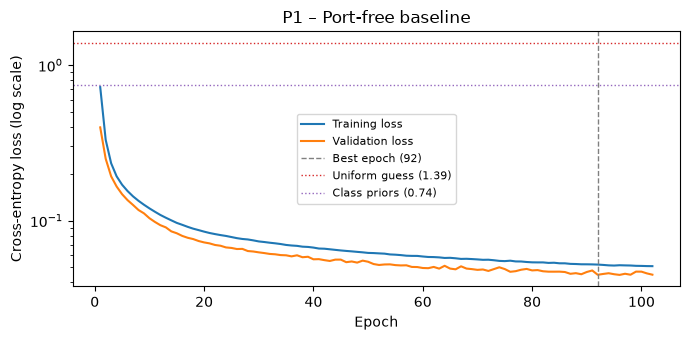

validation: accuracy 0.9841 (trivial 0.7541) | macro-F1 0.9726
              precision    recall  f1-score   support

      Benign      0.988     0.992     0.990      2518
 Brute Force      0.953     0.995     0.974       205
    DoS Hulk      0.978     0.949     0.964       574
    PortScan      1.000     0.929     0.963        42

    accuracy                          0.984      3339
   macro avg      0.980     0.966     0.973      3339
weighted avg      0.984     0.984     0.984      3339



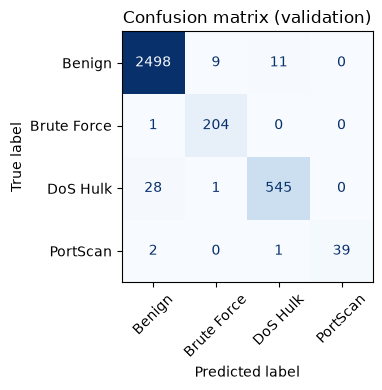

pred         Benign  Brute Force  DoS Hulk  PortScan
true                                                
Benign         2498            9        11         0
Brute Force       1          204         0         0
DoS Hulk         28            1       545         0
PortScan          2            0         1        39 

macro-recall                                  0.9663
attacks predicted Benign (missed)            31.0000
Benign predicted as attack (false alarms)    20.0000
false-alarm rate on Benign                    0.0079
PortScan detected                            39.0000
PortScan false alarms                         0.0000
dtype: float64


In [30]:
#P1 - BASELINE ON THE PORT-FREE DATA (same settings as the baseline R2)
model_P1 = run_experiment("P1", X_train_pf_t, X_val_pf_t, y_tr=y_train_pf_t, y_v=y_val_pf_t,
                          num_epochs=EPOCHS_BASELINE, title="Port-free baseline")

#who is confused with whom, and the detector view
err_P1 = pd.DataFrame({"true": le.classes_[y_val_pf_encoded], "pred": le.classes_[runs["P1"]["y_pred"]]})
print(pd.crosstab(err_P1["true"], err_P1["pred"]), "\n")
print(pd.Series(detection_summary("P1")).round(4))

**P1 – outcome vs hypothesis**

| | P1 (validation) |
|---|---|
| accuracy / macro-F1 | 0.984 / 0.973 |
| recall Benign / Brute Force / DoS Hulk / PortScan | 0.992 / 0.995 / 0.949 / 0.929 |
| precision Benign / Brute Force / DoS Hulk / PortScan | 0.988 / 0.953 / 0.978 / 1.000 |
| F1 Benign / Brute Force / DoS Hulk / PortScan | 0.990 / 0.974 / 0.964 / 0.963 |
| attack flows predicted Benign (missed) | 31 (DoS Hulk 28, Brute Force 1, PortScan 2) |
| Benign flows predicted as an attack (false alarms) | 20 (0.8%: 9 as Brute Force, 11 as DoS Hulk) |
| best epoch / last epoch | 92 / 102 |

- *PortScan suffers most – right on the ranking, wrong on the size.* PortScan has the lowest recall of the four classes, as expected, but it is detected in 39 of 42 validation flows (recall 0.929, above the expected 0.6–0.9) with no false alarm (precision 1.000, expected above 0.8). Its F1 (0.963) is tied with DoS Hulk (0.964) as the lowest, for different reasons: PortScan loses 3 flows out of 42, DoS Hulk 29 out of 574.
- *Brute Force – mostly right.* Recall 0.995 (expected at least 0.9); precision 0.953, slightly above the expected 0.8–0.92. Its false positives are Benign flows (9).
- *Revision rule – not triggered.* Brute Force has a higher F1 than PortScan (0.974 vs 0.963), so the result does not support the idea that the port was doing more work for Brute Force than for PortScan. The margin is small (one PortScan flow is 2.4 points of recall), so we do not read more into the ranking.
- *DoS Hulk and Benign "almost unchanged" – wrong for DoS Hulk.* DoS Hulk recall is 0.949 (28 flows predicted Benign) against 0.993 with the port (baseline R2, validation of Task 2; different data and split, so only indicative). Benign is unchanged (recall 0.992; R2: 0.994).
- *Global – half right.* Accuracy 0.984 (expected 0.975–0.99); macro-F1 0.973, above the expected 0.90–0.95: losing the port costs less than we thought.
- *Pattern.* Without the port, the missed attacks (31) are almost all DoS Hulk flows predicted as Benign (28): the port was helping to separate DoS Hulk from Benign web traffic on port 80.
- *Curves.* With the 200-epoch cap of the baseline, early stopping ends the run at epoch 102 (best epoch 92): P1 has converged. The validation loss stays slightly below the training loss (gap −0.007 at the best epoch), as in Task 2.

**Q: Can you still detect the rarest class at all?**
Yes. PortScan (42 validation flows) is detected in 39 cases (recall 0.929, 95% interval roughly 0.81–0.98) with no false alarm (precision 1.000, F1 0.963); of the 3 missed flows, 2 are predicted as Benign and 1 as DoS Hulk. The fear that the class would disappear behind 11,749 Benign training flows did not materialise: the other 15 features are enough to recognise the 285 distinct PortScan patterns. Two limits: 42 flows is a small sample, and the result is not directly comparable with the recall of 0.996 of Task 2 (different data and split). That figure was inflated by copies of the same patterns (98.9% of the PortScan test flows of Task 1 had a twin in training, 3.3); here the copies are gone and the class is still detected.

#### P2 – Port-free baseline with a class-weighted loss

**Why this run:** the unweighted loss lets the majority class dominate. With "balanced" weights (w_c = N / (K·n_c), from the training labels) each class contributes the same total weight to the loss: Benign about 0.33, Brute Force 4.1, DoS Hulk 1.5, PortScan 19.6 (59 times Benign).

**Hypothesis (written before running):**
- *Accuracy goes down slightly and macro-F1 goes up.* A PortScan error now costs as much as 59 Benign errors, so the decision boundary moves towards the rare classes: recall of PortScan and Brute Force goes up (PortScan to at least 0.95) while their precision goes down, because more Benign flows are flagged. Benign is 75% of the flows, so every extra Benign error counts in accuracy: accuracy −0.001 to −0.01, macro-F1 +0.005 to +0.04.
- *Wrong if* macro-F1 goes down (then P1 did not under-detect the rare classes and the weights only added false alarms) or accuracy goes up.
- *Reading the curves.* Weighted and unweighted loss values are not comparable. With balanced weights the best constant output is uniform (loss ln 4 = 1.39), so the "class priors" line does not apply to this run and is not drawn.

**Q: From which partition do you compute the class weights, and why would using any other partition be wrong?**
From the **training set only**. The weights are part of the training procedure, like the scaler: they are fitted on the data the model learns from. Computing them on the validation or test labels (or on all the data) would let information about those partitions enter training, which is leakage: the evaluation would no longer be on data the model and its training choices have never seen. Here the effect on the numbers would be small, because the split is stratified and the class proportions are almost identical in the three partitions, but the rule is the same as for the scaler: only the training set may shape the model.

{'Benign': np.float64(0.33), 'Brute Force': np.float64(4.07), 'DoS Hulk': np.float64(1.45), 'PortScan': np.float64(19.58)}
epoch   1 | train loss 0.8236 | val loss 0.5141
epoch  10 | train loss 0.1981 | val loss 0.1466
epoch  20 | train loss 0.1465 | val loss 0.1061
epoch  30 | train loss 0.1155 | val loss 0.0845
epoch  40 | train loss 0.0967 | val loss 0.0736
epoch  50 | train loss 0.0834 | val loss 0.0679
epoch  60 | train loss 0.0758 | val loss 0.0620
epoch  70 | train loss 0.0670 | val loss 0.0602
epoch  80 | train loss 0.0641 | val loss 0.0563
epoch  90 | train loss 0.0618 | val loss 0.0600
epoch 100 | train loss 0.0595 | val loss 0.0534
epoch 110 | train loss 0.0582 | val loss 0.0510
epoch 120 | train loss 0.0533 | val loss 0.0493
epoch 130 | train loss 0.0519 | val loss 0.0488
epoch 140 | train loss 0.0515 | val loss 0.0488
epoch 150 | train loss 0.0501 | val loss 0.0483
epoch 160 | train loss 0.0493 | val loss 0.0466
epoch 170 | train loss 0.0466 | val loss 0.0467
epoch 180 | t

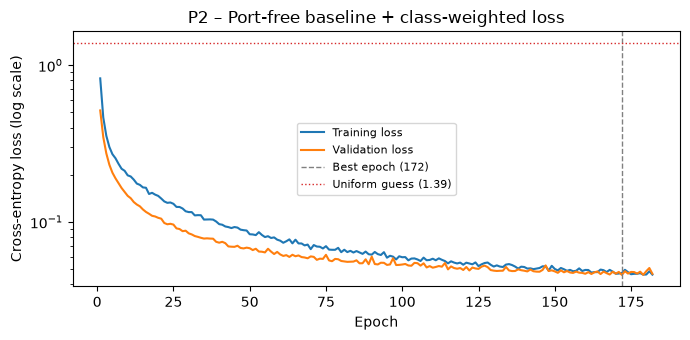

validation: accuracy 0.9751 (trivial 0.7541) | macro-F1 0.9369
              precision    recall  f1-score   support

      Benign      0.998     0.970     0.984      2518
 Brute Force      0.907     0.995     0.949       205
    DoS Hulk      0.930     0.988     0.958       574
    PortScan      0.750     1.000     0.857        42

    accuracy                          0.975      3339
   macro avg      0.896     0.988     0.937      3339
weighted avg      0.977     0.975     0.976      3339



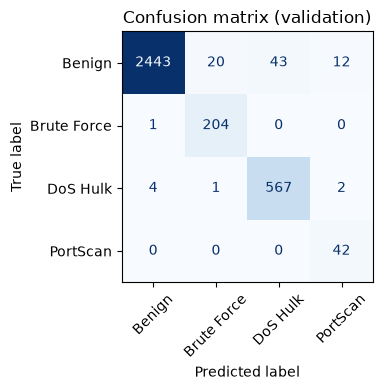

pred         Benign  Brute Force  DoS Hulk  PortScan
true                                                
Benign         2443           20        43        12
Brute Force       1          204         0         0
DoS Hulk          4            1       567         2
PortScan          0            0         0        42 

                                                 P1        P2
accuracy                                     0.9841    0.9751
macro-F1                                     0.9726    0.9369
recall Benign                                0.9921    0.9702
recall Brute Force                           0.9951    0.9951
recall DoS Hulk                              0.9495    0.9878
recall PortScan                              0.9286    1.0000
precision Benign                             0.9877    0.9980
precision Brute Force                        0.9533    0.9067
precision DoS Hulk                           0.9785    0.9295
precision PortScan                           1.0000    0.750

In [31]:
#P2 - SAME AS P1, WITH A CLASS-WEIGHTED LOSS
from sklearn.utils.class_weight import compute_class_weight

#weights from the TRAINING labels only: w_c = N / (K * n_c), one value per class (order = le.classes_)
class_weights_np = compute_class_weight("balanced", classes=np.arange(NUM_CLASSES), y=y_train_pf_encoded)
class_weights_t = torch.tensor(class_weights_np, dtype=torch.float32).to(device)
print(dict(zip(le.classes_, class_weights_np.round(2))))

model_P2 = run_experiment("P2", X_train_pf_t, X_val_pf_t, y_tr=y_train_pf_t, y_v=y_val_pf_t,
                          num_epochs=EPOCHS_BASELINE, class_weights=class_weights_t,
                          title="Port-free baseline + class-weighted loss")

#P1 vs P2: same data, seed, batches and lr; the only difference is the class-weighted loss
err_P2 = pd.DataFrame({"true": le.classes_[y_val_pf_encoded], "pred": le.classes_[runs["P2"]["y_pred"]]})
print(pd.crosstab(err_P2["true"], err_P2["pred"]), "\n")
rows = {}
for rid in ["P1", "P2"]:
    r = runs[rid]
    rows[rid] = {"accuracy": r["accuracy"], "macro-F1": r["macro_f1"],
                 **{f"recall {c}": r["recall"][c] for c in le.classes_},
                 **{f"precision {c}": r["precision"][c] for c in le.classes_},
                 **detection_summary(rid),
                 "best epoch": r["best_epoch"], "last epoch": r["last_epoch"],
                 "gap at best (val-train)": r["curve"]["gap at best (val-train)"]}
print(pd.DataFrame(rows).round(4))

#### P2 – outcome vs hypothesis

Class weights (from the training labels): Benign 0.33, DoS Hulk 1.45, Brute Force 4.07, PortScan 19.58.

| | P1 | P2 |
|---|---|---|
| accuracy | 0.984 | 0.975 |
| macro-F1 | 0.973 | 0.937 |
| macro-recall (balanced accuracy) | 0.966 | 0.988 |
| recall Benign / Brute Force / DoS Hulk / PortScan | 0.992 / 0.995 / 0.949 / 0.929 | 0.970 / 0.995 / 0.988 / 1.000 |
| precision Benign / Brute Force / DoS Hulk / PortScan | 0.988 / 0.953 / 0.978 / 1.000 | 0.998 / 0.907 / 0.930 / 0.750 |
| attack flows predicted Benign (missed) | 31 | 5 |
| Benign flows predicted as an attack (false alarms) | 20 (0.8%) | 75 (3.0%) |
| PortScan detected / false alarms on PortScan | 39 of 42 / 0 | 42 of 42 / 14 |
| best epoch / last epoch | 92 / 102 | 172 / 182 |

- *Accuracy – right.* It falls from 0.984 to 0.975 (hypothesis: −0.001 to −0.01; observed −0.009).
- *Macro-F1 – wrong.* We predicted an increase (+0.005 to +0.04); it falls by 0.036. The condition we had written as "wrong if" happened: P1 was not under-detecting the rare classes (recall 0.93–1.00, precision 0.95–1.00), so the weights had little recall to gain and much precision to lose.
- *Recall and precision – right on the direction.* Recall of DoS Hulk and PortScan rises (DoS Hulk 0.949 → 0.988, PortScan 0.929 → 1.000; Brute Force is already at 0.995) and precision falls for all three attack classes (PortScan 1.000 → 0.750, DoS Hulk 0.978 → 0.930, Brute Force 0.953 → 0.907): three more PortScan flows are detected (39 → 42 of 42) at the price of 14 false alarms on PortScan (12 Benign, 2 DoS Hulk).
- *Where it comes from.* The weights are an exchange rate: a PortScan error costs as much as 59 Benign errors, so the loss accepts many Benign errors for each rare-class error it avoids: 26 fewer missed attacks (31 → 5, almost all DoS Hulk) against 55 more false alarms (20 → 75; Benign recall 0.992 → 0.970).
- *Curves.* Weighted and unweighted loss values are not comparable, so we do not compare the two curves level by level. P2 trains longer (best epoch 172 vs 92) and its validation loss stays close to the training loss (gap −0.001 at the best epoch).
- *Limits.* PortScan has 42 validation flows, so its single numbers are noisy; the aggregate effect (+55 false alarms, −26 missed attacks) is not.

**Q: Did accuracy and macro-F1 move in the same direction?**
Yes, both fell (accuracy 0.984 → 0.975, macro-F1 0.973 → 0.937), against our prediction for macro-F1. A third metric moved the other way: the macro-recall (balanced accuracy) rose from 0.966 to 0.988. The three metrics answer different questions: accuracy counts flows and is dominated by Benign; macro-recall asks which fraction of each class is caught and ignores false alarms; macro-F1 asks that and also how many of the alarms of each class are real.

**Q: For an intrusion detector that must catch rare attacks, which metric should be optimised?**
**Macro-F1 to choose the model, with the recall of each attack class and the false-alarm rate on Benign reported next to it as constraints.**
- *Not accuracy.* Always predicting Benign gives 0.754, and missing all 42 PortScan flows costs only 1.3 points: a detector can look excellent while blind to the rarest attack.
- *Not recall alone.* It is what balanced weights optimise, and P2 shows the price: 26 fewer missed attacks, but a false-alarm rate on Benign of 3.0% instead of 0.8%. Precision gets worse in deployment, not better: here attacks are 25% of the flows, in real traffic far fewer, and the precision of a class falls with its prevalence, so the 0.750 of PortScan is optimistic. A flood of false alarms makes analysts ignore the detector.
- *Why macro-F1.* It penalises both failures (a missed attack and a false alarm) and, with the macro average, a 42-flow class weighs as much as the 2,518 Benign flows: it cannot hide behind the majority.
- *Its limit.* F1 treats a missed attack and a false alarm as equally important. P2 beats P1 only if a missed attack costs more than about 2.1 false alarms (55 / 26). If the real cost ratio is that large, the right objective is "maximise the recall of the attacks under a false-alarm budget", reached by choosing the decision threshold on the validation set, not with balanced weights that assume equal class priors.

## Task 5 – Varying the hyper-parameters

**Q: Can a more complex model beat the simple port-free baseline of Task 4 on validation?**

**Reference model: P1** (port-free data, one hidden layer of 64 ReLU units, unweighted cross-entropy, AdamW lr 5e-4, batch 64, ≤200 epochs, patience 10). In Task 4 we chose macro-F1 as the selection metric, and on macro-F1 P1 beats the class-weighted P2 (0.973 vs 0.937), so P1 is "the simple port-free baseline from Task 4". Every Task 5 run changes **one thing** with respect to the run it starts from (written in brackets): P1 for 5A, 5B, O1 and O5; inside the 5C grid O2 and O3 start from O1, and O4 from O3. Data, seed, initial-weight rule, epoch cap and early stopping stay the same. The decision criterion below always compares a run with P1, the reference.

**Budget.** 12 logged runs so far (R1, R1L, S1, four lr values in the S2 sweep, S3, R2, R3, P1, P2). Task 5 gets **10 runs**: 3 for depth (5A), 2 for batch size (5B, the third batch size is P1 itself), 5 for optimizer vs learning rate (5C, AdamW at 5e-4 is P1 itself). After Task 5 the total is 22, which leaves about 6 runs for Task 6 (a little above the ~25 of the lab text, mainly because the S2 sweep cost 4 runs).

**Decision criterion (fixed now, before any Task 5 run).** A candidate replaces P1 only if, on validation:
1. its macro-F1 is at least **+0.01** above P1, **and**
2. no attack class loses more than **0.025 of recall** (about one PortScan flow out of 42).

*Why +0.01.* With 42 PortScan flows in validation, one PortScan flow moves the macro-F1 by about 0.003, so +0.01 means about three flows of the rarest class: a smaller gain could come from one or two borderline flows, and we do not pay extra complexity for it. We did not measure the variance between runs or seeds, so the threshold is a choice made in advance, not a measured noise level. *(Revised after the runs: an earlier version of this note justified the threshold with an execution on another PC that is not documented in this notebook, so we removed that argument. The threshold itself is unchanged.)*

**Where P1 fails (what a better model would have to fix).** On validation P1 misses 31 attacks (28 of them DoS Hulk predicted as Benign) and raises 20 false alarms (9 Benign flows predicted as Brute Force, 11 as DoS Hulk). In 3.3 we removed 103 feature vectors that, without the port, appear both as Benign and as an attack: the remaining DoS Hulk misses may be close to Benign flows in the 15 features too, and no amount of capacity can separate flows that look the same.

In [32]:
#5.0 SETUP: reference model, summary table and decision rule (shared by 5A-5D)
BASELINE_PF = "P1"                                              #simple port-free baseline of Task 4 (best macro-F1 of Task 4)
ATTACKS = ["Brute Force", "DoS Hulk", "PortScan"]

#sanity check: DeepNN with one hidden layer of 64 has the same initial weights as the baseline network
same_init = all(torch.equal(p, q) for p, q in zip(build_deep_model([64]).parameters(), build_model().parameters()))
print("DeepNN([64]) == baseline at initialisation:", same_init)

def task5_row(rid):
    """One row of the Task 5 tables: validation metrics, detector view, curve and cost of a run."""
    r, d = runs[rid], detection_summary(rid)
    return {"macro-F1": r["macro_f1"], "accuracy": r["accuracy"],
            **{f"recall {c}": r["recall"][c] for c in le.classes_},
            "missed attacks": d["attacks predicted Benign (missed)"],
            "false alarms": d["Benign predicted as attack (false alarms)"],
            "min val loss": r["curve"]["min val loss"],
            "gap at best (val-train)": r["curve"]["gap at best (val-train)"],
            "val roughness": r["curve"]["val roughness"],
            "best epoch": r["best_epoch"], "last epoch": r["last_epoch"],
            "time (s)": r["time_s"], "s / epoch": r["time_s"] / r["last_epoch"],
            "parameters": r["n_params"]}

def task5_table(rids):
    return pd.DataFrame({rid: task5_row(rid) for rid in rids}).round(4)

def beats_baseline(rid, min_gain=0.01, max_recall_loss=0.025):
    """Decision criterion fixed before the Task 5 runs."""
    gain = runs[rid]["macro_f1"] - runs[BASELINE_PF]["macro_f1"]
    worst_loss = max(runs[BASELINE_PF]["recall"][c] - runs[rid]["recall"][c] for c in ATTACKS)
    return (gain >= min_gain and worst_loss <= max_recall_loss), gain, worst_loss

def plot_val_curves(rids, title, filename):
    """Validation loss of several runs on the same axes (all unweighted, so the values are comparable)."""
    fig, ax = plt.subplots(figsize=(7, 3.5))
    for rid in rids:
        v = runs[rid]["history"]["val_loss"]
        ax.plot(np.arange(1, len(v) + 1), v, label=rid)
    ax.set_yscale("log"); ax.set_xlabel("Epoch"); ax.set_ylabel("Validation loss (log scale)")
    ax.set_title(title); ax.legend(fontsize=8)
    plt.tight_layout(); plt.savefig(os.path.join(FIG_DIR, filename), dpi=300); plt.show()

print(task5_table([BASELINE_PF]).T)

DeepNN([64]) == baseline at initialisation: True
    macro-F1  accuracy  recall Benign  recall Brute Force  recall DoS Hulk  \
P1    0.9726    0.9841         0.9921              0.9951           0.9495   

    recall PortScan  missed attacks  false alarms  min val loss  \
P1           0.9286            31.0          20.0        0.0447   

    gap at best (val-train)  val roughness  best epoch  last epoch  time (s)  \
P1                  -0.0073         0.0307        92.0       102.0   26.5979   

    s / epoch  parameters  
P1     0.2608      1284.0  


### 5A – Depth

**Design (no grid).** Three candidates, each answering a different question:

| run | hidden layers | parameters | question |
|---|---|---|---|
| P1 | [64] | 1,284 | reference |
| D1 | [64, 64] | 5,444 | does one more layer of the same width help? |
| D2 | [64, 64, 64] | 9,604 | if D1 helps, does the trend continue? if D1 does not, is more depth still useless? |
| D3 | [32, 32] | 1,700 | depth at about the same parameter count as P1: if D1 gains, is it depth or just more parameters? |

Widths stay at 64 (or 32 for D3) so that the only thing that grows is depth; a funnel such as [128, 64, 32] would change width and depth together.

**Hypothesis (written before running, all three runs):**
- *Metrics.* Depth does not help on this problem: the macro-F1 of D1, D2 and D3 is within ±0.01 of P1, so **none meets the +0.01 criterion**. P1 already reaches 0.98 with 1,284 parameters on 15 features, and its remaining errors are concentrated on DoS Hulk flows that resemble Benign flows (see the setup above): extra layers add capacity, not information.
- *Where the change shows.* If anything moves, it is DoS Hulk recall (±0.02), the class where P1 has almost all its errors; Brute Force and PortScan within one or two flows.
- *Curves.* Deeper networks fit the training set faster: lower training loss, best epoch earlier than P1 (expected 40–100 for D1 and D2), and the validation-minus-training gap gets less negative (it may turn slightly positive for D2). No clear overfitting within 200 epochs (5,000–10,000 parameters for 15,583 flows), so early stopping still fires before the cap. D3 behaves like P1.
- *Cost.* Time per epoch grows only a little (×1.2–1.6 for D2): with batch 64 the Python loop and the optimizer step dominate, not the matrix products.

#### D1 – two hidden layers [64, 64] (←P1)

epoch   1 | train loss 0.5338 | val loss 0.2152
epoch  10 | train loss 0.0769 | val loss 0.0627
epoch  20 | train loss 0.0589 | val loss 0.0516
epoch  30 | train loss 0.0514 | val loss 0.0457
epoch  40 | train loss 0.0476 | val loss 0.0415
epoch  50 | train loss 0.0446 | val loss 0.0408
epoch  60 | train loss 0.0423 | val loss 0.0411
epoch  70 | train loss 0.0413 | val loss 0.0402
early stopping at epoch 71: no improvement for 10 epochs
best epoch: 61 (val loss 0.0389) | last epoch: 71 | time: 20.4 s


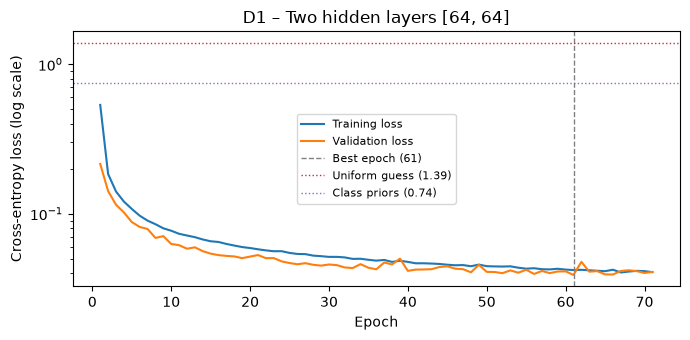

validation: accuracy 0.9880 (trivial 0.7541) | macro-F1 0.9820
              precision    recall  f1-score   support

      Benign      0.994     0.991     0.992      2518
 Brute Force      0.953     0.995     0.974       205
    DoS Hulk      0.974     0.974     0.974       574
    PortScan      1.000     0.976     0.988        42

    accuracy                          0.988      3339
   macro avg      0.980     0.984     0.982      3339
weighted avg      0.988     0.988     0.988      3339



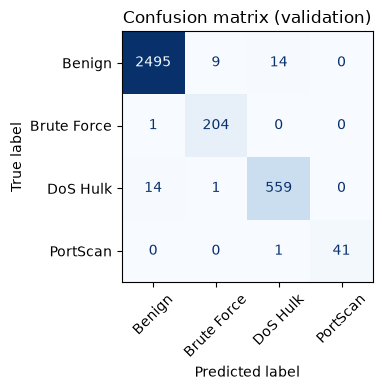

In [33]:
#D1 - SAME AS P1, WITH TWO HIDDEN LAYERS OF 64
model_D1 = run_experiment("D1", X_train_pf_t, X_val_pf_t, y_tr=y_train_pf_t, y_v=y_val_pf_t,
                          num_epochs=EPOCHS_BASELINE, hidden_sizes=[64, 64], title="Two hidden layers [64, 64]")

#### D2 – three hidden layers [64, 64, 64] (←P1)

epoch   1 | train loss 0.4642 | val loss 0.1746
epoch  10 | train loss 0.0641 | val loss 0.0525
epoch  20 | train loss 0.0489 | val loss 0.0456
epoch  30 | train loss 0.0436 | val loss 0.0463
epoch  40 | train loss 0.0405 | val loss 0.0389
epoch  50 | train loss 0.0392 | val loss 0.0422
early stopping at epoch 50: no improvement for 10 epochs
best epoch: 40 (val loss 0.0389) | last epoch: 50 | time: 21.2 s


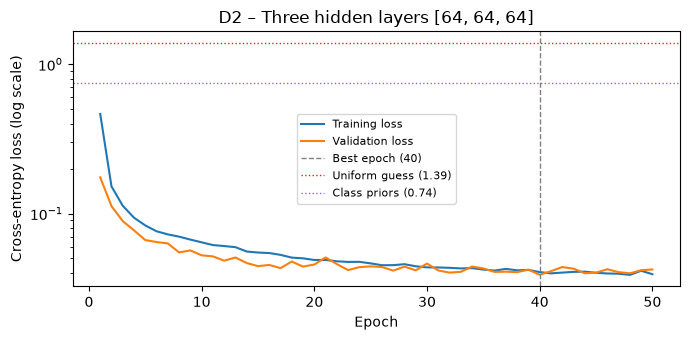

validation: accuracy 0.9880 (trivial 0.7541) | macro-F1 0.9821
              precision    recall  f1-score   support

      Benign      0.991     0.994     0.992      2518
 Brute Force      0.953     0.995     0.974       205
    DoS Hulk      0.989     0.960     0.974       574
    PortScan      1.000     0.976     0.988        42

    accuracy                          0.988      3339
   macro avg      0.983     0.981     0.982      3339
weighted avg      0.988     0.988     0.988      3339



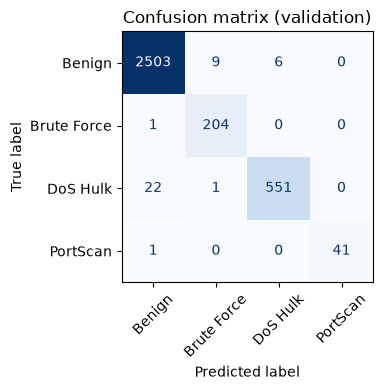

In [34]:
#D2 - SAME AS P1, WITH THREE HIDDEN LAYERS OF 64
model_D2 = run_experiment("D2", X_train_pf_t, X_val_pf_t, y_tr=y_train_pf_t, y_v=y_val_pf_t,
                          num_epochs=EPOCHS_BASELINE, hidden_sizes=[64, 64, 64], title="Three hidden layers [64, 64, 64]")

#### D3 – two hidden layers [32, 32], about the same parameter count as P1 (←P1)

epoch   1 | train loss 0.7042 | val loss 0.3401
epoch  10 | train loss 0.0957 | val loss 0.0805
epoch  20 | train loss 0.0729 | val loss 0.0617
epoch  30 | train loss 0.0651 | val loss 0.0557
epoch  40 | train loss 0.0603 | val loss 0.0522
epoch  50 | train loss 0.0561 | val loss 0.0503
epoch  60 | train loss 0.0534 | val loss 0.0483
epoch  70 | train loss 0.0517 | val loss 0.0474
epoch  80 | train loss 0.0491 | val loss 0.0463
epoch  90 | train loss 0.0475 | val loss 0.0475
epoch 100 | train loss 0.0462 | val loss 0.0471
early stopping at epoch 102: no improvement for 10 epochs
best epoch: 92 (val loss 0.0445) | last epoch: 102 | time: 40.9 s


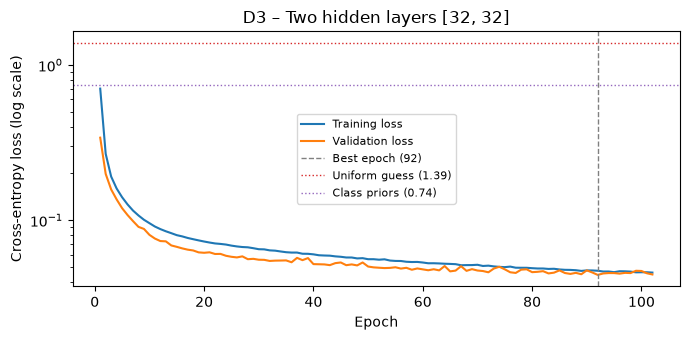

validation: accuracy 0.9871 (trivial 0.7541) | macro-F1 0.9750
              precision    recall  f1-score   support

      Benign      0.991     0.993     0.992      2518
 Brute Force      0.949     0.995     0.971       205
    DoS Hulk      0.984     0.963     0.974       574
    PortScan      1.000     0.929     0.963        42

    accuracy                          0.987      3339
   macro avg      0.981     0.970     0.975      3339
weighted avg      0.987     0.987     0.987      3339



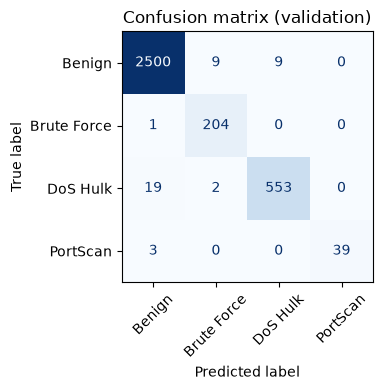

In [35]:
#D3 - SAME AS P1, WITH TWO HIDDEN LAYERS OF 32 (1,700 parameters vs 1,284)
model_D3 = run_experiment("D3", X_train_pf_t, X_val_pf_t, y_tr=y_train_pf_t, y_v=y_val_pf_t,
                          num_epochs=EPOCHS_BASELINE, hidden_sizes=[32, 32], title="Two hidden layers [32, 32]")

                                P1         D1         D2         D3
macro-F1                    0.9726     0.9820     0.9821     0.9750
accuracy                    0.9841     0.9880     0.9880     0.9871
recall Benign               0.9921     0.9909     0.9940     0.9929
recall Brute Force          0.9951     0.9951     0.9951     0.9951
recall DoS Hulk             0.9495     0.9739     0.9599     0.9634
recall PortScan             0.9286     0.9762     0.9762     0.9286
missed attacks             31.0000    15.0000    24.0000    23.0000
false alarms               20.0000    23.0000    15.0000    18.0000
min val loss                0.0447     0.0389     0.0389     0.0445
gap at best (val-train)    -0.0073    -0.0030    -0.0017    -0.0028
val roughness               0.0307     0.0529     0.0673     0.0358
best epoch                 92.0000    61.0000    40.0000    92.0000
last epoch                102.0000    71.0000    50.0000   102.0000
time (s)                   26.5979    20.4326   

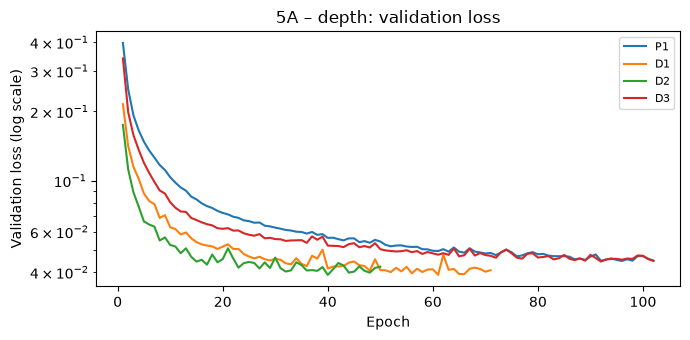

In [36]:
#5A SUMMARY: P1 vs D1, D2, D3 (validation) and decision criterion
print(task5_table(["P1", "D1", "D2", "D3"]), "\n")
for rid in ["D1", "D2", "D3"]:
    ok, gain, worst = beats_baseline(rid)
    print(f"{rid}: macro-F1 {gain:+.4f} vs P1 | largest attack-recall loss {worst:+.3f} -> beats P1: {ok}")
plot_val_curves(["P1", "D1", "D2", "D3"], "5A – depth: validation loss", "task5A_depth_val_loss.png")

**5A – outcome vs hypothesis**

| | P1 [64] | D1 [64, 64] | D2 [64, 64, 64] | D3 [32, 32] |
|---|---|---|---|---|
| parameters | 1,284 | 5,444 | 9,604 | 1,700 |
| macro-F1 (val) | 0.9726 | 0.9820 | 0.9821 | 0.9750 |
| recall DoS Hulk / PortScan | 0.950 / 0.929 | 0.974 / 0.976 | 0.960 / 0.976 | 0.963 / 0.929 |
| missed attacks / false alarms | 31 / 20 | 15 / 23 | 24 / 15 | 23 / 18 |
| min val loss | 0.0447 | 0.0389 | 0.0389 | 0.0445 |
| best / last epoch | 92 / 102 | 61 / 71 | 40 / 50 | 92 / 102 |
| s per epoch / total time | 0.26 / 27 s | 0.29 / 20 s | 0.42 / 21 s | 0.40 / 41 s |

- *Metrics – right, but only just.* D1 and D2 gain +0.0094 and +0.0095 of macro-F1, D3 +0.0024: all within the ±0.01 we predicted and **none meets the +0.01 criterion**. D1 and D2 sit right at the edge: their gain is about three PortScan flows' worth.
- *Where the change shows – right on DoS Hulk, wrong on the size.* The gain comes from DoS Hulk (recall 0.950 → 0.974 in D1, +0.024, a little beyond the ±0.02 we expected; missed attacks 31 → 15) and from PortScan (0.929 → 0.976, i.e. 39 → 41 of 42 flows). Brute Force does not move. D2 trades part of the DoS Hulk gain for fewer false alarms (15 instead of 20): the extra layer moves the errors around rather than removing them.
- *Depth vs parameters.* D3 has almost the parameter count of P1 and behaves like P1 (same best epoch, same min val loss, +0.002 of macro-F1). D1 and D2 have 4–7× the parameters of P1 and give the same result as each other: going from two to three layers adds nothing.
- *Curves – right.* Deeper networks fit faster (best epoch 61 and 40 vs 92), the train/val gap gets less negative (−0.007 → −0.003 and −0.002) without turning positive, and early stopping fires well before the cap: no overfitting.
- *Cost – right per epoch, not predicted in total.* Time per epoch ×1.10 (D1) and ×1.63 (D2), at the top of the ×1.2–1.6 we expected for D2. Since they stop earlier, their total training time is lower than P1's (20 s and 21 s vs 27 s). D3, which is as small as P1, took 0.40 s per epoch (×1.54): wall-clock times on the same PC vary from run to run, so time differences below about 50% should not be over-read.

**Q: Does depth help on this problem? If a single-hidden-layer baseline stays competitive, what does that suggest?**
Not in a way we can claim. The best deep model gains 0.0095 of macro-F1 with 4× the parameters, which is below our threshold; a third layer adds nothing over the second, and depth at constant parameter count (D3) changes nothing. The one-hidden-layer network stays competitive because the task is small and low-dimensional: 15 tabular features, four classes, and boundaries that a single layer of 64 ReLU units already draws well (macro-F1 ≈ 0.97–0.98). The remaining errors are mostly DoS Hulk flows that are close to Benign flows in these 15 features, and more layers cannot add information that the features do not carry. Depth mainly bought faster convergence (fewer epochs), not a better detector.

*In hindsight, D2 was the most redundant run of the lab.* It gives the same result as D1 (macro-F1 0.9821 vs 0.9820, same min val loss 0.0389), so it changed no decision; its question ("what if we go deeper still?") is answered again by T0 in Task 6, a five-layer network; and the lab text asks for 2–3 candidates, so D1 (more depth) and D3 (depth at a constant parameter count) were enough.

### 5B – Batch size

**Design.** Batch sizes 1, 64 (= P1) and 1024: a factor of 64 below and 16 above the baseline. Everything else as P1, **including the learning rate (5e-4) and the 200-epoch cap**, to respect the one-change rule. This has a consequence we state up front: with Adam each update moves the weights by about lr, so the batch size also changes the number of updates per epoch (15,583 with batch 1, 244 with batch 64, 16 with batch 1024). Part of what we measure is therefore "how many updates the run gets", not only the noise of the gradient.

**Hypothesis (written before running):**
- *B2 – batch 1024: underfitting, faster.* 200 epochs × 16 updates = 3,200 updates, about what P1 does in its first 13 epochs. (a) Generalisation: the curve is smooth and still falling at epoch 200 (best epoch = last epoch, early stopping never fires), train ≈ val, min val loss well above P1 (about 0.08–0.12, the level of P1 around epoch 10–15) and macro-F1 below P1 by 0.02–0.08; the classes learned last suffer most (DoS Hulk, PortScan). (b) Time: 10–20× less time per epoch than P1 (fewer Python iterations), and less total time even though it uses all 200 epochs (expected 3–6× faster).
- *B1 – batch 1: noisy, slower.* One epoch is 15,583 updates, as many as 64 epochs of P1. (a) Generalisation: the best epoch comes very early (≤ 15) and early stopping fires before epoch 30; the validation curve is jagged (higher roughness than P1) because every step follows the gradient of one single flow. Macro-F1 between P1 −0.02 and P1 +0.005: we do not expect the "small batches generalise better" effect to show on a network of 1,284 parameters that does not overfit in the first place. (b) Time: 40–80× more time per epoch than P1 (one Python iteration per flow), and more total time despite the fewer epochs (expected 5–15× P1).
- *Overall.* Neither B1 nor B2 meets the +0.01 criterion; batch 64 is close to the best compromise between updates per second and gradient noise.

#### B1 – batch size 1 (←P1)

epoch   1 | train loss 0.1988 | val loss 0.1110
epoch  10 | train loss 0.0698 | val loss 0.0595
epoch  20 | train loss 0.0647 | val loss 0.0609
epoch  30 | train loss 0.0632 | val loss 0.0508
epoch  40 | train loss 0.0623 | val loss 0.0519
early stopping at epoch 47: no improvement for 10 epochs
best epoch: 37 (val loss 0.0506) | last epoch: 47 | time: 360.4 s


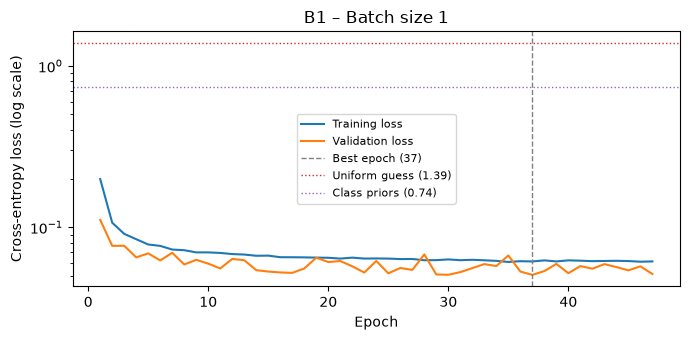

validation: accuracy 0.9838 (trivial 0.7541) | macro-F1 0.9706
              precision    recall  f1-score   support

      Benign      0.986     0.993     0.990      2518
 Brute Force      0.932     0.995     0.962       205
    DoS Hulk      0.994     0.943     0.968       574
    PortScan      1.000     0.929     0.963        42

    accuracy                          0.984      3339
   macro avg      0.978     0.965     0.971      3339
weighted avg      0.984     0.984     0.984      3339



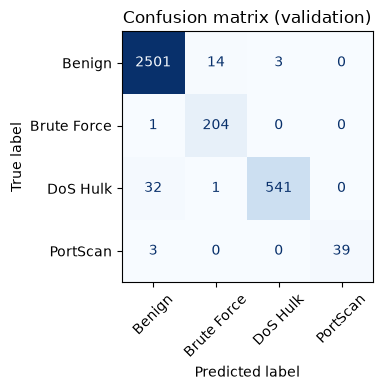

In [37]:
#B1 - SAME AS P1, WITH BATCH SIZE 1 (one flow per update)
model_B1 = run_experiment("B1", X_train_pf_t, X_val_pf_t, y_tr=y_train_pf_t, y_v=y_val_pf_t,
                          num_epochs=EPOCHS_BASELINE, batch_size=1, title="Batch size 1")

#### B2 – batch size 1024 (←P1)

epoch   1 | train loss 1.3778 | val loss 1.2725
epoch  10 | train loss 0.5060 | val loss 0.4707
epoch  20 | train loss 0.3135 | val loss 0.2900
epoch  30 | train loss 0.2308 | val loss 0.2129
epoch  40 | train loss 0.1905 | val loss 0.1752
epoch  50 | train loss 0.1669 | val loss 0.1530
epoch  60 | train loss 0.1508 | val loss 0.1377
epoch  70 | train loss 0.1386 | val loss 0.1259
epoch  80 | train loss 0.1284 | val loss 0.1157
epoch  90 | train loss 0.1194 | val loss 0.1067
epoch 100 | train loss 0.1118 | val loss 0.0992
epoch 110 | train loss 0.1053 | val loss 0.0927
epoch 120 | train loss 0.0997 | val loss 0.0872
epoch 130 | train loss 0.0948 | val loss 0.0826
epoch 140 | train loss 0.0909 | val loss 0.0790
epoch 150 | train loss 0.0874 | val loss 0.0756
epoch 160 | train loss 0.0846 | val loss 0.0730
epoch 170 | train loss 0.0819 | val loss 0.0708
epoch 180 | train loss 0.0796 | val loss 0.0688
epoch 190 | train loss 0.0778 | val loss 0.0670
epoch 200 | train loss 0.0760 | val loss

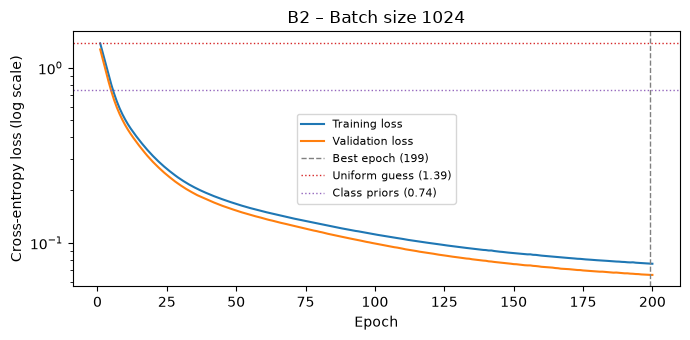

validation: accuracy 0.9781 (trivial 0.7541) | macro-F1 0.9567
              precision    recall  f1-score   support

      Benign      0.982     0.990     0.986      2518
 Brute Force      0.938     0.951     0.944       205
    DoS Hulk      0.978     0.939     0.958       574
    PortScan      0.974     0.905     0.938        42

    accuracy                          0.978      3339
   macro avg      0.968     0.946     0.957      3339
weighted avg      0.978     0.978     0.978      3339



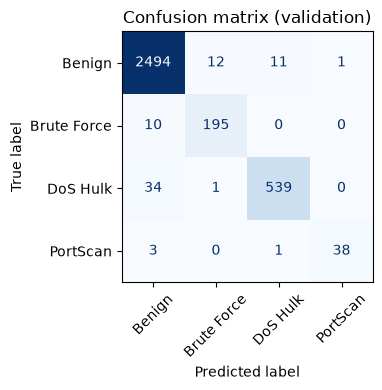

In [38]:
#B2 - SAME AS P1, WITH BATCH SIZE 1024
model_B2 = run_experiment("B2", X_train_pf_t, X_val_pf_t, y_tr=y_train_pf_t, y_v=y_val_pf_t,
                          num_epochs=EPOCHS_BASELINE, batch_size=1024, title="Batch size 1024")

                                  B1          P1         B2
macro-F1                      0.9706      0.9726     0.9567
accuracy                      0.9838      0.9841     0.9781
recall Benign                 0.9932      0.9921     0.9905
recall Brute Force            0.9951      0.9951     0.9512
recall DoS Hulk               0.9425      0.9495     0.9390
recall PortScan               0.9286      0.9286     0.9048
missed attacks               36.0000     31.0000    47.0000
false alarms                 17.0000     20.0000    24.0000
min val loss                  0.0506      0.0447     0.0656
gap at best (val-train)      -0.0107     -0.0073    -0.0105
val roughness                 0.0926      0.0307     0.0149
best epoch                   37.0000     92.0000   199.0000
last epoch                   47.0000    102.0000   200.0000
time (s)                    360.3710     26.5979    27.1050
s / epoch                     7.6675      0.2608     0.1355
parameters                 1284.0000   1

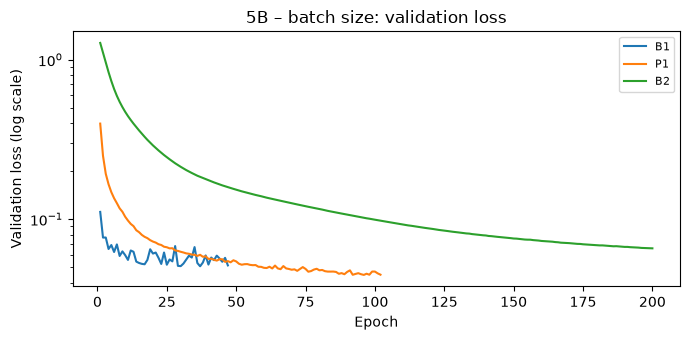

In [39]:
#5B SUMMARY: batch 1 / 64 / 1024 (validation), training time and updates
tab = task5_table(["B1", "P1", "B2"])
tab.loc["updates per epoch"] = [int(np.ceil(len(y_train_pf_t) / b)) for b in [1, 64, 1024]]
tab.loc["total updates"] = tab.loc["updates per epoch"] * tab.loc["last epoch"]
print(tab, "\n")
for rid in ["B1", "B2"]:
    ok, gain, worst = beats_baseline(rid)
    print(f"{rid}: macro-F1 {gain:+.4f} vs P1 | largest attack-recall loss {worst:+.3f} -> beats P1: {ok}")
plot_val_curves(["B1", "P1", "B2"], "5B – batch size: validation loss", "task5B_batch_val_loss.png")

**5B – outcome vs hypothesis**

| | B1 (batch 1) | P1 (batch 64) | B2 (batch 1024) |
|---|---|---|---|
| updates per epoch / total updates | 15,583 / 732,401 | 244 / 24,888 | 16 / 3,200 |
| macro-F1 (val) | 0.9706 | 0.9726 | 0.9567 |
| recall Brute Force / DoS Hulk / PortScan | 0.995 / 0.943 / 0.929 | 0.995 / 0.950 / 0.929 | 0.951 / 0.939 / 0.905 |
| min val loss | 0.0506 | 0.0447 | 0.0656 |
| val roughness | 0.093 | 0.031 | 0.015 |
| best / last epoch | 37 / 47 | 92 / 102 | 199 / 200 |
| s per epoch / total time | 7.67 / 360 s | 0.26 / 27 s | 0.14 / 27 s |

**Q: Report validation results and training time, and explain both.**

*(a) Generalisation.*
- *B2 (1024) – right on the diagnosis, wrong on the size.* It is underfitting, not generalising worse: the curve is smooth and still falling at epoch 200 (best epoch 199), the train/val gap is as small as in P1, and macro-F1 is 0.016 lower (expected 0.02–0.08 lower). The min val loss (0.066) is better than we predicted (0.08–0.12): 3,200 updates with batches of 1,024 flows go further than 3,200 noisy updates of P1, because each step follows a cleaner gradient. The class that lost most was Brute Force (recall 0.995 → 0.951), not DoS Hulk and PortScan as we expected. The cause is the number of updates: with a fixed lr and epoch cap, a big batch simply trains less.
- *B1 (1) – right on the result, wrong on the timing of the curve.* Macro-F1 0.9706, within our range (P1 −0.002); the curve is about 3× rougher than P1 (0.093 vs 0.031) because each step follows one single flow. We expected the best epoch before 15; it came at epoch 37 (stop at 47): the noise of per-flow updates keeps the validation loss bouncing around 0.05–0.06 for many epochs before early stopping gives up. No "small batches generalise better" effect: on a network that does not overfit there is nothing for that noise to regularise.

*(b) Wall-clock time.*
- *B1 – right in total, wrong per epoch.* 7.7 s per epoch, 29× P1 (expected 40–80×), and 360 s in total, 14× P1 (expected 5–15×): one Python iteration and one optimizer step per flow (plus 3,339 validation iterations per epoch, one per validation flow), so the cost grows with the number of updates, not with the amount of data.
- *B2 – wrong.* We expected 10–20× less time per epoch and a total 3–6× shorter. Time per epoch is only 2× lower (0.14 vs 0.26 s), although B2 does 15× fewer training iterations (16 vs 244) and also 15× fewer validation iterations (4 vs 53: in `make_loaders` the validation loader uses the same batch size). Our most likely explanation, not measured: with a `TensorDataset` the `DataLoader` fetches the flows of a batch one at a time and then stacks them, so a part of the cost of an epoch grows with the number of flows (15,583 + 3,339) and does not shrink with the batch size. And since B2 never triggers early stopping, it runs all 200 epochs: total time 27 s, the same as P1 (27 s).

*Takeaway.* Batch 64 is the best compromise of the three: B1 costs 14× the time for no gain, and B2 is not faster in total and stops learning too early for the same lr and epoch cap. Neither meets the criterion.

### 5C – Optimizer vs learning rate

**Design.** A 3 × 2 grid: optimizer {SGD, SGD + momentum 0.9, AdamW} × learning rate {5e-4, 5e-2}. AdamW at 5e-4 is P1, so the grid costs **5 new runs** (O1–O5). To keep one change per run, the grid is walked one step at a time: O1 ←P1 (AdamW → SGD), O2 ←O1 (lr 5e-4 → 5e-2), O3 ←O1 (+ momentum 0.9), O4 ←O3 (lr 5e-4 → 5e-2), O5 ←P1 (lr 5e-4 → 5e-2). The two learning rates are 100× apart: 5e-4 is the usual range for Adam, 5e-2 the usual range for SGD. Everything else as P1 (batch 64, ≤200 epochs, patience 10). Note: AdamW applies a weight decay of 0.01 by default and SGD none; at these learning rates its effect per step (lr × 0.01) is negligible, so we keep the defaults.

| | lr 5e-4 | lr 5e-2 |
|---|---|---|
| SGD | O1 | O2 |
| SGD + momentum 0.9 | O3 | O4 |
| AdamW | P1 | O5 |

**How we read it (fixed now).** If the claim of the lab text is true, the spread of macro-F1 **across learning rates** (same optimizer) is much larger than the spread **across optimizers**, each taken at its better learning rate. We compare these two spreads.

**Hypothesis (written before running):**
- *SGD at 5e-4 (O1): far too slow.* SGD moves each weight by lr × gradient, and the gradients here are small (most flows are already well classified after a few epochs), so its steps are orders of magnitude smaller than Adam's (≈ lr per weight). Smooth curve still falling at epoch 200, min val loss above 0.2, macro-F1 0.6–0.9; PortScan (1.3% of the flows) may never be predicted (recall near 0).
- *SGD + momentum at 5e-4 (O3): slow, but better than O1.* Momentum 0.9 multiplies the effective step by about 1/(1−0.9) = 10. Still not converged at 200 epochs; macro-F1 0.85–0.95.
- *SGD at 5e-2 (O2) and SGD + momentum at 5e-2 (O4): close to P1.* At its own learning rate SGD reaches P1 within 0.02 of macro-F1. O4 has an effective step of about 0.5, so its curve is the roughest of the SGD runs and stops earliest.
- *AdamW at 5e-2 (O5): too high for Adam.* 100× P1; the S2 sweep (data with the port) gave lr 1e-2 as good as the baseline and 1e-1 clearly noisier (macro-F1 −0.015). We expect a jagged curve, early stopping before epoch 60, macro-F1 between P1 −0.03 and P1.
- *Verdict we expect.* **The learning rate dominates.** At the same lr the optimizers differ by 0.05 or more of macro-F1 (O1 vs P1); each at its better lr they end within about 0.02. The good lr is not the same for every optimizer (5e-4 for AdamW, 5e-2 for SGD): "the right optimizer" mostly means "an optimizer with its right lr". None of O1–O5 meets the +0.01 criterion.

#### O1 – SGD, lr 5e-4 (←P1: AdamW → SGD)

epoch   1 | train loss 1.3478 | val loss 1.2389
epoch  10 | train loss 0.6512 | val loss 0.6271
epoch  20 | train loss 0.5099 | val loss 0.4894
epoch  30 | train loss 0.4386 | val loss 0.4186
epoch  40 | train loss 0.3913 | val loss 0.3717
epoch  50 | train loss 0.3556 | val loss 0.3364
epoch  60 | train loss 0.3279 | val loss 0.3091
epoch  70 | train loss 0.3057 | val loss 0.2874
epoch  80 | train loss 0.2870 | val loss 0.2691
epoch  90 | train loss 0.2715 | val loss 0.2541
epoch 100 | train loss 0.2594 | val loss 0.2424
epoch 110 | train loss 0.2490 | val loss 0.2324
epoch 120 | train loss 0.2400 | val loss 0.2237
epoch 130 | train loss 0.2322 | val loss 0.2163
epoch 140 | train loss 0.2254 | val loss 0.2098
epoch 150 | train loss 0.2196 | val loss 0.2042
epoch 160 | train loss 0.2144 | val loss 0.1992
epoch 170 | train loss 0.2096 | val loss 0.1947
epoch 180 | train loss 0.2053 | val loss 0.1906
epoch 190 | train loss 0.2014 | val loss 0.1869
epoch 200 | train loss 0.1978 | val loss

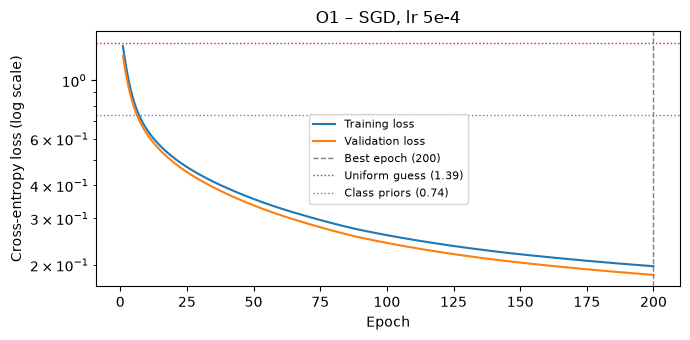

validation: accuracy 0.9524 (trivial 0.7541) | macro-F1 0.6975
              precision    recall  f1-score   support

      Benign      0.954     0.986     0.970      2518
 Brute Force      0.884     0.893     0.888       205
    DoS Hulk      0.970     0.897     0.932       574
    PortScan      0.000     0.000     0.000        42

    accuracy                          0.952      3339
   macro avg      0.702     0.694     0.698      3339
weighted avg      0.941     0.952     0.946      3339



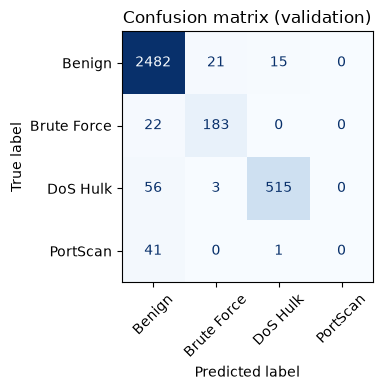

In [40]:
#O1 - SAME AS P1, WITH SGD INSTEAD OF ADAMW (LR 5E-4)
model_O1 = run_experiment("O1", X_train_pf_t, X_val_pf_t, y_tr=y_train_pf_t, y_v=y_val_pf_t,
                          num_epochs=EPOCHS_BASELINE, lr=5e-4, optimizer_name="sgd", title="SGD, lr 5e-4")

#### O2 – SGD, lr 5e-2 (←O1: lr 5e-4 → 5e-2)

epoch   1 | train loss 0.4222 | val loss 0.2434
epoch  10 | train loss 0.1189 | val loss 0.1033
epoch  20 | train loss 0.0915 | val loss 0.0784
epoch  30 | train loss 0.0804 | val loss 0.0672
epoch  40 | train loss 0.0746 | val loss 0.0618
epoch  50 | train loss 0.0700 | val loss 0.0593
epoch  60 | train loss 0.0669 | val loss 0.0555
epoch  70 | train loss 0.0642 | val loss 0.0530
epoch  80 | train loss 0.0616 | val loss 0.0522
epoch  90 | train loss 0.0591 | val loss 0.0502
epoch 100 | train loss 0.0579 | val loss 0.0487
epoch 110 | train loss 0.0565 | val loss 0.0475
epoch 120 | train loss 0.0553 | val loss 0.0462
epoch 130 | train loss 0.0535 | val loss 0.0462
early stopping at epoch 139: no improvement for 10 epochs
best epoch: 129 (val loss 0.0453) | last epoch: 139 | time: 28.2 s


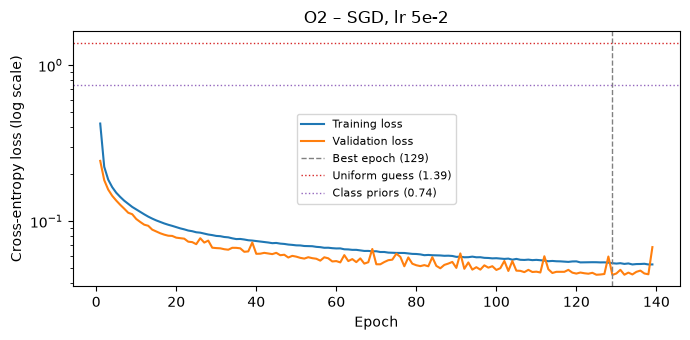

validation: accuracy 0.9856 (trivial 0.7541) | macro-F1 0.9735
              precision    recall  f1-score   support

      Benign      0.988     0.994     0.991      2518
 Brute Force      0.949     0.995     0.971       205
    DoS Hulk      0.989     0.949     0.969       574
    PortScan      1.000     0.929     0.963        42

    accuracy                          0.986      3339
   macro avg      0.981     0.967     0.974      3339
weighted avg      0.986     0.986     0.986      3339



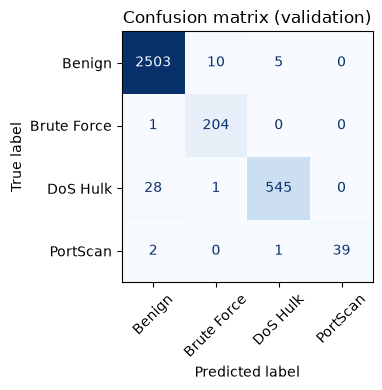

In [41]:
#O2 - SAME AS O1 (SGD), WITH LR 5E-2
model_O2 = run_experiment("O2", X_train_pf_t, X_val_pf_t, y_tr=y_train_pf_t, y_v=y_val_pf_t,
                          num_epochs=EPOCHS_BASELINE, lr=5e-2, optimizer_name="sgd", title="SGD, lr 5e-2")

#### O3 – SGD + momentum 0.9, lr 5e-4 (←O1: + momentum 0.9)

epoch   1 | train loss 0.9050 | val loss 0.6292
epoch  10 | train loss 0.2653 | val loss 0.2428
epoch  20 | train loss 0.1997 | val loss 0.1836
epoch  30 | train loss 0.1729 | val loss 0.1588
epoch  40 | train loss 0.1570 | val loss 0.1438
epoch  50 | train loss 0.1460 | val loss 0.1331
epoch  60 | train loss 0.1375 | val loss 0.1247
epoch  70 | train loss 0.1307 | val loss 0.1181
epoch  80 | train loss 0.1249 | val loss 0.1121
epoch  90 | train loss 0.1196 | val loss 0.1068
epoch 100 | train loss 0.1150 | val loss 0.1021
epoch 110 | train loss 0.1108 | val loss 0.0980
epoch 120 | train loss 0.1072 | val loss 0.0942
epoch 130 | train loss 0.1039 | val loss 0.0909
epoch 140 | train loss 0.1010 | val loss 0.0881
epoch 150 | train loss 0.0984 | val loss 0.0855
epoch 160 | train loss 0.0961 | val loss 0.0833
epoch 170 | train loss 0.0940 | val loss 0.0813
epoch 180 | train loss 0.0922 | val loss 0.0795
epoch 190 | train loss 0.0905 | val loss 0.0779
epoch 200 | train loss 0.0889 | val loss

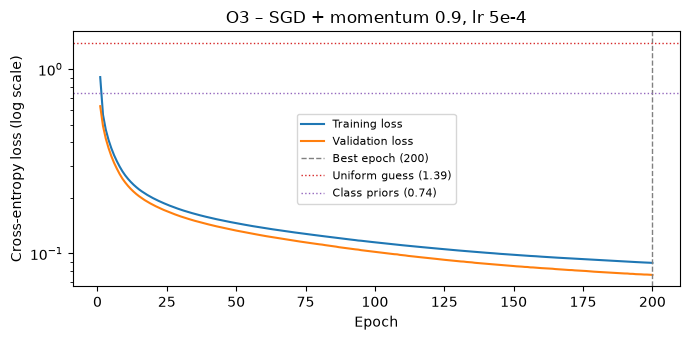

validation: accuracy 0.9757 (trivial 0.7541) | macro-F1 0.9521
              precision    recall  f1-score   support

      Benign      0.981     0.988     0.985      2518
 Brute Force      0.919     0.941     0.930       205
    DoS Hulk      0.975     0.937     0.956       574
    PortScan      0.974     0.905     0.938        42

    accuracy                          0.976      3339
   macro avg      0.962     0.943     0.952      3339
weighted avg      0.976     0.976     0.976      3339



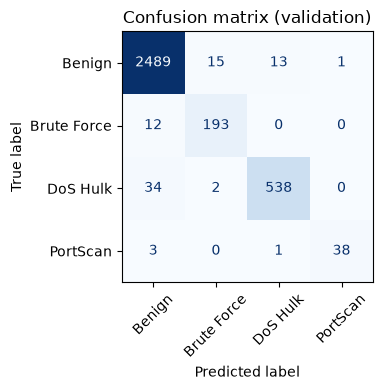

In [42]:
#O3 - SAME AS O1 (SGD, LR 5E-4), WITH MOMENTUM 0.9
model_O3 = run_experiment("O3", X_train_pf_t, X_val_pf_t, y_tr=y_train_pf_t, y_v=y_val_pf_t,
                          num_epochs=EPOCHS_BASELINE, lr=5e-4, optimizer_name="sgd", momentum=0.9, title="SGD + momentum 0.9, lr 5e-4")

#### O4 – SGD + momentum 0.9, lr 5e-2 (←O3: lr 5e-4 → 5e-2)

epoch   1 | train loss 0.2168 | val loss 0.1169
epoch  10 | train loss 0.0681 | val loss 0.0570
epoch  20 | train loss 0.0584 | val loss 0.0537
epoch  30 | train loss 0.0528 | val loss 0.0526
epoch  40 | train loss 0.0497 | val loss 0.0435
epoch  50 | train loss 0.0491 | val loss 0.0444
epoch  60 | train loss 0.0468 | val loss 0.0415
epoch  70 | train loss 0.0449 | val loss 0.0386
early stopping at epoch 76: no improvement for 10 epochs
best epoch: 66 (val loss 0.0370) | last epoch: 76 | time: 15.5 s


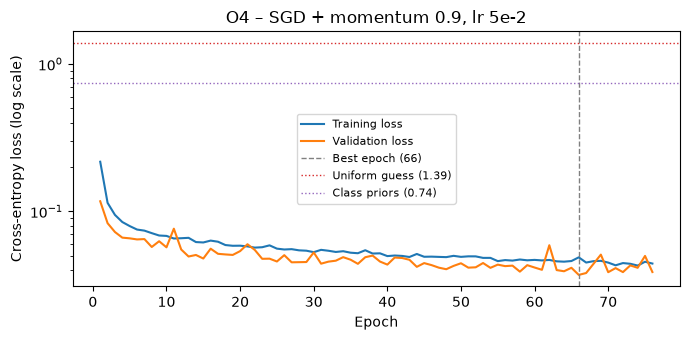

validation: accuracy 0.9895 (trivial 0.7541) | macro-F1 0.9835
              precision    recall  f1-score   support

      Benign      0.994     0.993     0.993      2518
 Brute Force      0.953     0.995     0.974       205
    DoS Hulk      0.984     0.974     0.979       574
    PortScan      1.000     0.976     0.988        42

    accuracy                          0.990      3339
   macro avg      0.983     0.985     0.983      3339
weighted avg      0.990     0.990     0.990      3339



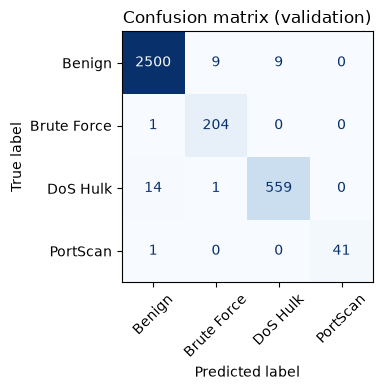

In [43]:
#O4 - SAME AS O3 (SGD + MOMENTUM 0.9), WITH LR 5E-2
model_O4 = run_experiment("O4", X_train_pf_t, X_val_pf_t, y_tr=y_train_pf_t, y_v=y_val_pf_t,
                          num_epochs=EPOCHS_BASELINE, lr=5e-2, optimizer_name="sgd", momentum=0.9, title="SGD + momentum 0.9, lr 5e-2")

#### O5 – AdamW, lr 5e-2 (←P1: lr 5e-4 → 5e-2)

epoch   1 | train loss 0.1809 | val loss 0.1530
epoch  10 | train loss 0.1001 | val loss 0.1010
early stopping at epoch 15: no improvement for 10 epochs
best epoch: 5 (val loss 0.0678) | last epoch: 15 | time: 3.7 s


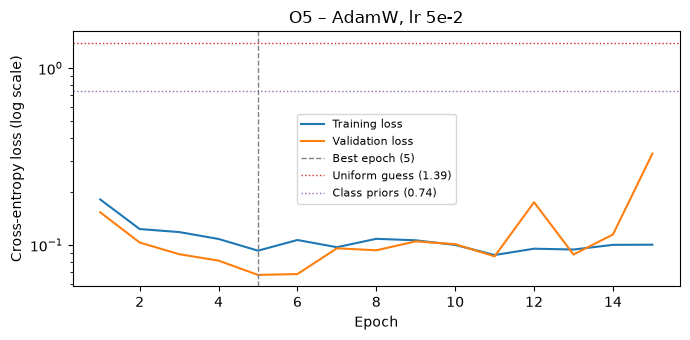

validation: accuracy 0.9823 (trivial 0.7541) | macro-F1 0.9665
              precision    recall  f1-score   support

      Benign      0.987     0.991     0.989      2518
 Brute Force      0.936     0.995     0.965       205
    DoS Hulk      0.980     0.946     0.963       574
    PortScan      1.000     0.905     0.950        42

    accuracy                          0.982      3339
   macro avg      0.976     0.959     0.967      3339
weighted avg      0.983     0.982     0.982      3339



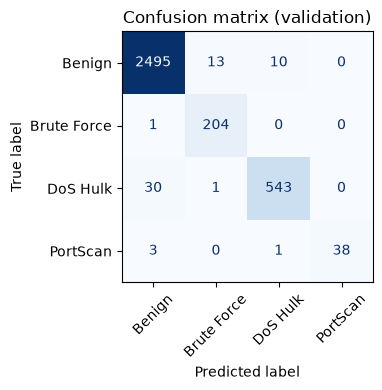

In [44]:
#O5 - SAME AS P1, WITH ADAMW, LR 5E-2
model_O5 = run_experiment("O5", X_train_pf_t, X_val_pf_t, y_tr=y_train_pf_t, y_v=y_val_pf_t,
                          num_epochs=EPOCHS_BASELINE, lr=5e-2, optimizer_name="adamw", title="AdamW, lr 5e-2")

validation macro-F1 (rows: optimizer, columns: learning rate)
                   5e-4    5e-2
SGD             0.6975  0.9735
SGD + momentum  0.9521  0.9835
AdamW           0.9726  0.9665 

spread across learning rates, per optimizer:
 SGD               0.2760
SGD + momentum    0.0313
AdamW             0.0061
dtype: float64
spread across optimizers at the same lr:
 5e-4    0.275
5e-2    0.017
dtype: float64
spread across optimizers, each at its better lr: 0.0109

                                O1         O2         O3         O4  \
macro-F1                    0.6975     0.9735     0.9521     0.9835   
accuracy                    0.9524     0.9856     0.9757     0.9895   
recall Benign               0.9857     0.9940     0.9885     0.9929   
recall Brute Force          0.8927     0.9951     0.9415     0.9951   
recall DoS Hulk             0.8972     0.9495     0.9373     0.9739   
recall PortScan             0.0000     0.9286     0.9048     0.9762   
missed attacks            119.0000  

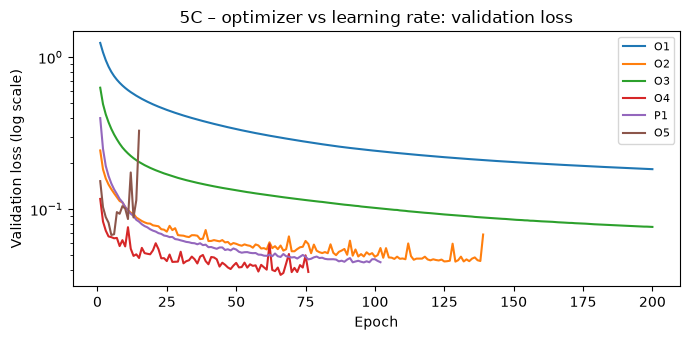

In [45]:
#5C SUMMARY: optimizer x learning rate (validation macro-F1)
grid = {("SGD", "5e-4"): "O1", ("SGD", "5e-2"): "O2",
        ("SGD + momentum", "5e-4"): "O3", ("SGD + momentum", "5e-2"): "O4",
        ("AdamW", "5e-4"): "P1", ("AdamW", "5e-2"): "O5"}
f1_grid = pd.Series({k: runs[v]["macro_f1"] for k, v in grid.items()}).unstack()
f1_grid = f1_grid.loc[["SGD", "SGD + momentum", "AdamW"], ["5e-4", "5e-2"]]
print("validation macro-F1 (rows: optimizer, columns: learning rate)\n", f1_grid.round(4), "\n")

#the two spreads defined before the runs
spread_lr  = (f1_grid.max(axis=1) - f1_grid.min(axis=1))          #per optimizer: best lr - worst lr
spread_opt = f1_grid.max(axis=1).max() - f1_grid.max(axis=1).min() #across optimizers, each at its better lr
spread_same_lr = (f1_grid.max(axis=0) - f1_grid.min(axis=0))       #per lr: best optimizer - worst optimizer
print("spread across learning rates, per optimizer:\n", spread_lr.round(4))
print("spread across optimizers at the same lr:\n", spread_same_lr.round(4))
print(f"spread across optimizers, each at its better lr: {spread_opt:.4f}\n")

print(task5_table(["O1", "O2", "O3", "O4", "P1", "O5"]), "\n")
for rid in ["O1", "O2", "O3", "O4", "O5"]:
    ok, gain, worst = beats_baseline(rid)
    print(f"{rid}: macro-F1 {gain:+.4f} vs P1 | largest attack-recall loss {worst:+.3f} -> beats P1: {ok}")
plot_val_curves(["O1", "O2", "O3", "O4", "P1", "O5"], "5C – optimizer vs learning rate: validation loss", "task5C_optimizer_val_loss.png")

**5C – outcome vs hypothesis**

Validation macro-F1:

| | lr 5e-4 | lr 5e-2 | spread across lr |
|---|---|---|---|
| SGD | 0.6975 (O1) | 0.9735 (O2) | 0.276 |
| SGD + momentum 0.9 | 0.9521 (O3) | **0.9835** (O4) | 0.031 |
| AdamW | 0.9726 (P1) | 0.9665 (O5) | 0.006 |
| spread across optimizers | 0.275 | 0.017 | |

Spread across optimizers, each at its better lr: **0.011**.

- *O1 (SGD, 5e-4) – mostly right.* Smooth curve still falling at epoch 200, macro-F1 0.698 (expected 0.6–0.9) and PortScan never predicted (recall 0.000), as expected. Wrong on the loss: the min val loss is 0.183, below the "above 0.2" we predicted, so SGD at this lr is slow but a little less slow than we thought: plain SGD at an Adam-sized lr takes steps far too small to learn the 1.3% class in 200 epochs.
- *O3 (SGD + momentum, 5e-4) – mostly right.* Still not converged at epoch 200, as expected, and clearly better than O1 (val loss at epoch 200: 0.077 vs 0.183). Wrong on the macro-F1: 0.952, just above the expected 0.85–0.95, so momentum alone recovers more than we predicted.
- *O2 (SGD, 5e-2) – right.* At its own learning rate plain SGD matches P1 (macro-F1 0.9735, +0.001).
- *O4 (SGD + momentum, 5e-2) – right on the curve, wrong on the result.* As expected it is the roughest SGD curve (roughness 0.090) and the SGD run that stops earliest (epoch 76). We did not expect it to be the best run of the whole task: macro-F1 0.9835 (+0.0109), with DoS Hulk recall 0.950 → 0.974 and 16 missed attacks instead of 31. It is the only run that meets the +0.01 criterion, by 0.0009.
- *O5 (AdamW, 5e-2) – right.* Jagged curve (roughness 0.30, 10× P1), best epoch 5, early stopping at epoch 15, macro-F1 −0.006 (expected −0.03 to 0).

**Q: What did you find – does the optimizer or the learning rate dominate on this data?**
**The learning rate**, with one qualification. At the same learning rate the optimizers differ by up to 0.275 of macro-F1 (O1 vs P1 at 5e-4); once each optimizer gets the better of its two learning rates, they end within 0.011 of each other. For SGD, changing the lr by 100× moves macro-F1 by 0.276; changing the optimizer at a good lr moves it by about 0.01. The qualification is AdamW: across the same 100× range its macro-F1 moves by only 0.006. That is what Adam actually buys: not a better final model, but a wide range of learning rates that work, because it rescales every step by the gradient's own size. SGD has no such protection, so with SGD the choice of lr is everything. In practice "the right optimizer" mostly means "an optimizer with a learning rate that suits it" (5e-4 is good for AdamW and useless for SGD).
*Limit.* Each optimizer was tried at two learning rates only, so "its better lr" means "the better of the two", not its optimum: AdamW, for example, could do better at 5e-3, between the two values we tested.

**Decision (criterion fixed before the Task 5 runs).** O4 is the only run that meets both conditions (macro-F1 +0.0109 ≥ +0.01, no attack class loses recall), so by our rule **O4 replaces P1 as the reference model**. We state it with its weakness: the margin over the threshold is 0.0009, a third of one PortScan flow. For Task 6 we keep reporting P1 next to O4, because the lab text asks to compare the big network with the simple port-free baseline of Task 4.

### 5D – Verdict on the test set

**Why this step:** the port-free test set has not been used for any choice yet. We take the best Task 5 model on validation (highest macro-F1 among D1–D3, B1–B2, O1–O5, chosen by the code below) and evaluate it **once** on the test set, next to P1. Evaluating trained models is not a new run.

**Hypothesis (written before running):**
- *The validation advantage shrinks on test.* The best Task 5 model is the maximum of 10 runs on the same validation set, so part of its lead over P1 is selection luck (the same "winner's curse" that made the S2 metrics optimistic). On test its macro-F1 is within ±0.01 of P1's, and the sign of the difference may flip.
- *Both generalise.* Each model's test macro-F1 is within ±0.01 of its validation macro-F1; the errors keep the validation pattern (DoS Hulk predicted as Benign, Benign predicted as Brute Force).
- *Answer we expect.* The added complexity does not beat the simple baseline by more than the noise, and the 10 runs were worth it only as evidence (they tell us where the gains are not), not as a better detector.

best Task 5 model on validation: O4 (macro-F1 0.9835, +0.0109 vs P1) -> meets the criterion: True

=== P1 ===
test (P1): accuracy 0.9802 (trivial 0.7539) | macro-F1 0.9551
              precision    recall  f1-score   support

      Benign      0.986     0.989     0.987      2518
 Brute Force      0.927     0.990     0.958       205
    DoS Hulk      0.977     0.948     0.962       574
    PortScan      0.974     0.860     0.914        43

    accuracy                          0.980      3340
   macro avg      0.966     0.947     0.955      3340
weighted avg      0.980     0.980     0.980      3340



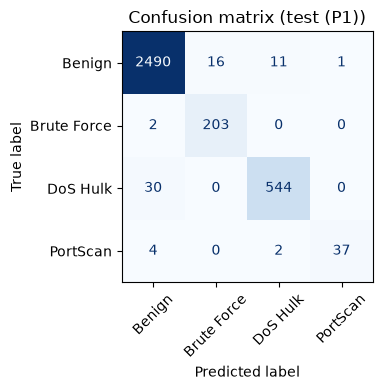

=== O4 ===
test (O4): accuracy 0.9877 (trivial 0.7539) | macro-F1 0.9770
              precision    recall  f1-score   support

      Benign      0.992     0.992     0.992      2518
 Brute Force      0.931     0.990     0.960       205
    DoS Hulk      0.988     0.972     0.980       574
    PortScan      1.000     0.953     0.976        43

    accuracy                          0.988      3340
   macro avg      0.978     0.977     0.977      3340
weighted avg      0.988     0.988     0.988      3340



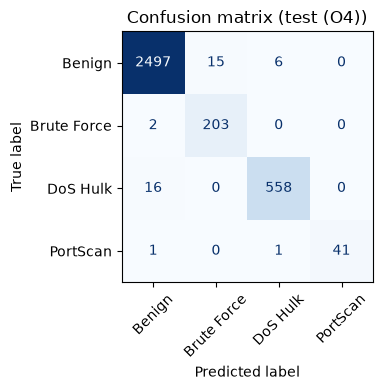

                          P1 val    P1 test     O4 val    O4 test
macro-F1                  0.9726     0.9551     0.9835     0.9770
accuracy                  0.9841     0.9802     0.9895     0.9877
recall Benign             0.9921     0.9889     0.9929     0.9917
recall Brute Force        0.9951     0.9902     0.9951     0.9902
recall DoS Hulk           0.9495     0.9477     0.9739     0.9721
recall PortScan           0.9286     0.8605     0.9762     0.9535
precision Benign          0.9877     0.9857     0.9936     0.9924
precision Brute Force     0.9533     0.9269     0.9533     0.9312
precision DoS Hulk        0.9785     0.9767     0.9842     0.9876
precision PortScan        1.0000     0.9737     1.0000     1.0000
missed attacks           31.0000    36.0000    16.0000    19.0000
false alarms             20.0000    28.0000    18.0000    21.0000
parameters             1284.0000  1284.0000  1284.0000  1284.0000
training time (s)        26.5979    26.5979    15.5124    15.5124

test macr

In [46]:
#5D - BEST TASK 5 MODEL (on validation) vs P1, ON THE PORT-FREE TEST SET (used here for the first and only time)
task5_ids = ["D1", "D2", "D3", "B1", "B2", "O1", "O2", "O3", "O4", "O5"]
BEST_T5 = max(task5_ids, key=lambda rid: runs[rid]["macro_f1"])
ok, gain, worst = beats_baseline(BEST_T5)
print(f"best Task 5 model on validation: {BEST_T5} (macro-F1 {runs[BEST_T5]['macro_f1']:.4f}, "
      f"{gain:+.4f} vs P1) -> meets the criterion: {ok}\n")

test_res = {}
for rid in [BASELINE_PF, BEST_T5]:
    print(f"=== {rid} ===")
    test_res[rid] = evaluate(runs[rid]["model"], X_test_pf_t, y_test_pf_t, f"test ({rid})", filename=f"task5D_{rid}_cm_test.png")

#side by side: validation and test, P1 vs best Task 5 model
y_test_pf_encoded = y_test_pf_t.numpy()
def detector_view(y_true, y_pred):
    attack = (y_true != BENIGN)
    return {"missed attacks": int((attack & (y_pred == BENIGN)).sum()),
            "false alarms": int((~attack & (y_pred != BENIGN)).sum())}
side = {}
for rid in [BASELINE_PF, BEST_T5]:
    for part, res, y_true in [("val", runs[rid], y_val_pf_encoded), ("test", test_res[rid], y_test_pf_encoded)]:
        side[f"{rid} {part}"] = {"macro-F1": res["macro_f1"], "accuracy": res["accuracy"],
                                 **{f"recall {c}": res["recall"][c] for c in le.classes_},
                                 **{f"precision {c}": res["precision"][c] for c in le.classes_},
                                 **detector_view(y_true, res["y_pred"])}
side = pd.DataFrame(side)
side.loc["parameters"] = [runs[rid]["n_params"] for rid in [BASELINE_PF, BASELINE_PF, BEST_T5, BEST_T5]]
side.loc["training time (s)"] = [runs[rid]["time_s"] for rid in [BASELINE_PF, BASELINE_PF, BEST_T5, BEST_T5]]
print(side.round(4))
print(f"\ntest macro-F1: {BEST_T5} - P1 = {test_res[BEST_T5]['macro_f1'] - test_res[BASELINE_PF]['macro_f1']:+.4f}")

**5D – outcome vs hypothesis**

| | P1 val | P1 test | O4 val | O4 test |
|---|---|---|---|---|
| macro-F1 | 0.9726 | 0.9551 | 0.9835 | 0.9770 |
| accuracy | 0.9841 | 0.9802 | 0.9895 | 0.9877 |
| recall Brute Force / DoS Hulk / PortScan | 0.995 / 0.950 / 0.929 | 0.990 / 0.948 / 0.860 | 0.995 / 0.974 / 0.976 | 0.990 / 0.972 / 0.953 |
| missed attacks / false alarms | 31 / 20 | 36 / 28 | 16 / 18 | 19 / 21 |
| parameters / training time | 1,284 / 27 s | | 1,284 / 16 s | |

- *Validation advantage shrinks on test – wrong.* It grew: O4 − P1 is +0.011 on validation and +0.022 on test. The test gap comes from two classes: DoS Hulk (recall 0.948 → 0.972, 14 more flows detected) and PortScan (37 → 41 of 43 flows, which moves its F1 by 0.06 because the class is so small). The missed attacks drop from 36 to 19 with fewer false alarms (28 → 21).
- *Both generalise – right for O4, wrong for P1.* O4 loses 0.007 of macro-F1 from validation to test (within ±0.01); P1 loses 0.018, mainly on PortScan (recall 0.929 → 0.860, i.e. 6 of 43 flows missed). With 42–43 PortScan flows per partition, a few flows move the macro-F1 by about 0.01, so part of this gap is sampling noise.
- *Caveat.* We did not measure the variance between runs or seeds, and it could be as large as the gain. O4 meets our criterion by 0.0009, so the evidence that it is better than P1 is real on test (17 fewer missed attacks) but not strong; confirming it would need several seeds, which our budget does not cover.

**Q: Did the added complexity beat the simple baseline? Was it worth the runs it cost?**
**No added complexity beat the baseline.** The networks that are actually more complex (D1 and D2, 4–7× the parameters) gain less than our +0.01 threshold, and the batch-size changes make things worse or much slower. The only model that clears the threshold, O4, is **not more complex**: it is the same one-layer network with 1,284 parameters, trained with SGD + momentum at a higher learning rate, and it is even faster to train (16 s vs 27 s). On test it is better than P1 (macro-F1 0.977 vs 0.955, missed attacks 19 vs 36), which says that the gain was in the optimisation, not in the architecture.
Were the 10 runs worth it? As a detector, little: one run (O4) out of ten improved on P1, and by a margin of about one PortScan flow. As evidence, yes: they show that depth and batch size do not pay on this problem, and that the learning rate (paired with the optimizer) is the hyper-parameter worth tuning. In hindsight, a cheaper plan would have spent most of the budget on the learning rate and only one run on depth.

### Task 5 – logbook rows (for the appendix)

Each run changes one thing with respect to the run in brackets. P1 = port-free data, [64] ReLU, unweighted CE, AdamW lr 5e-4, batch 64, ≤200 epochs, patience 10. Key result = validation; the comparison in brackets in the key result is always with P1, the reference of the decision criterion.

| Run | Task | What I changed (one thing) | Hypothesis before running | Key result (val) | What I concluded |
|---|---|---|---|---|---|
| D1 (←P1) | 5A | hidden layers [64] → [64, 64] | depth does not help: macro-F1 within ±0.01 of P1; earlier best epoch | macro-F1 0.9820 (+0.0094); DoS Hulk recall 0.950 → 0.974; best epoch 61 | gain below threshold (about three PortScan flows); faster convergence |
| D2 (←P1) | 5A | [64] → [64, 64, 64] | as D1; gap less negative, maybe slightly positive | macro-F1 0.9821 (+0.0095); best epoch 40; gap −0.002 | a third layer adds nothing over the second; no overfitting |
| D3 (←P1) | 5A | [64] → [32, 32] (1,700 params) | behaves like P1 | macro-F1 0.9750 (+0.0024); same best epoch as P1 | depth at constant parameter count changes nothing |
| B1 (←P1) | 5B | batch 64 → 1 | jagged curve, best epoch ≤15, macro-F1 P1 −0.02 to +0.005; time ×5–15 | macro-F1 0.9706 (−0.002); best epoch 37; 360 s (×14) | no gain, 14× the time; roughness 3× P1; best epoch later than predicted |
| B2 (←P1) | 5B | batch 64 → 1024 | underfits (3,200 updates), macro-F1 −0.02 to −0.08; 3–6× faster | macro-F1 0.9567 (−0.016); best epoch 199/200; 27 s (P1: 27 s) | underfitting from too few updates; not faster in total (wrong on time) |
| O1 (←P1) | 5C | AdamW → SGD (lr 5e-4) | far too slow; macro-F1 0.6–0.9; PortScan ~0 | macro-F1 0.6975; PortScan recall 0.000; still falling at 200 | SGD needs a much larger lr than Adam |
| O2 (←O1) | 5C | lr 5e-4 → 5e-2 (SGD) | within 0.02 of P1 | macro-F1 0.9735 (+0.001) | at its own lr SGD matches AdamW |
| O3 (←O1) | 5C | + momentum 0.9 (SGD, lr 5e-4) | ~10× faster than O1, not converged; macro-F1 0.85–0.95 | macro-F1 0.9521; still falling at 200 | momentum helps, but the lr is still too small |
| O4 (←O3) | 5C | lr 5e-4 → 5e-2 (SGD + momentum 0.9) | close to P1, roughest SGD curve, stops earliest | macro-F1 0.9835 (+0.0109); missed attacks 31 → 16; stop at 76 | best run of Task 5; meets the criterion by 0.0009 (wrong prediction) → replaces P1 as reference |
| O5 (←P1) | 5C | AdamW lr 5e-4 → 5e-2 | jagged, early stop < 60, macro-F1 −0.03 to 0 | macro-F1 0.9665 (−0.006); best epoch 5; roughness 10× P1 | Adam tolerates a 100× lr range; lr dominates for SGD, not for AdamW |

Task 5 used 10 runs (total so far: 22). 5D evaluates already-trained models on the test set and is not a new run.

## Task 6 – Optimizations: the big network

**Setting (from the lab text).** Port-free data, 5 hidden layers {256, 128, 64, 32, 16}, ReLU, cross-entropy, AdamW lr 5e-4, batch 128, 200 epochs, **no regularization and no early stopping**. Two details we make explicit:
- *"No regularization" means `weight_decay=0`.* AdamW in PyTorch applies a decoupled weight decay of 0.01 by default, and every run so far used it. Here we set it to 0, otherwise the "unregularized" network would already carry one regularizer.
- *"No early stopping" means the model we evaluate is the one of the last epoch (200).* Our training function normally restores the weights of the best validation epoch; for these runs it keeps the last ones. The epoch of the lowest validation loss is still recorded, but only to analyse the curves.

The network has **47,924 parameters**, 37× P1 and about 3 per training flow (15,583). With batch 128 one epoch is 122 updates, so 200 epochs are 24,400 updates. Besides the loss we now record the **validation macro-F1 at every epoch** (no effect on training), to see whether overfitting in the loss is also overfitting in the metric we chose in Task 4.

**References.** P1 (simple port-free baseline of Task 4, the comparison the lab asks for) and O4 (the current reference after 5C). Both are one-layer networks with 1,284 parameters.

**Budget and plan.** 22 runs so far. Task 6 gets **5 runs**, one change each:

| run | starts from | one change | step of the lab text |
|---|---|---|---|
| T0 | – | the big network, unregularized, 200 epochs | starting point |
| T1 | T0 | early stopping (patience 10, best weights restored) | 1. stop earlier |
| T2 | T0 | weight decay 0.1 | 2. first regularizer |
| T3 | T2 (or T0 if T2 is dropped) | dropout p = 0.2 | 2. second regularizer |
| T4 | T3 (or its parent if T3 is dropped) | batch normalization | 2. third regularizer |

Total after Task 6: 27 runs, two more than the ~25 of the lab text (the S2 sweep cost four). We use 5 runs instead of the ~6 suggested and do not plan a sixth "best combination" run.

**Why these choices.**
- *Early stopping rather than a smaller network for step 1.* It is the simplest change of all: no architecture change, no new hyper-parameter (we reuse patience 10 from every earlier run) and it can only shorten training. A smaller network would largely repeat 5A, which already measured one- to three-layer networks of 1,300–9,600 parameters on this data.
- *The regularizer chain runs without early stopping.* Early stopping would cut each run before the overfitting appears and hide what the regularizer itself does. Keeping 200 epochs and the last weights, each regularizer must fix the overfitting on its own, and the curves show whether it does.
- *Weight decay 0.1.* With decoupled weight decay every step shrinks each weight by lr × wd. Over 24,400 steps the default 0.01 shrinks a weight that receives no gradient to exp(−5e-4 · 0.01 · 24,400) ≈ 0.89 of its value, which is barely noticeable; 0.1 shrinks it to ≈ 0.30, a real pull towards zero that the gradient has to justify; 1.0 would take it to ≈ 6·10⁻⁶, i.e. erase every weight the data does not constantly support. 0.1 is the middle value.
- *Dropout p = 0.2.* The last hidden layers have only 32 and 16 units: with p = 0.5 the 16-unit layer would keep about 8 units per step, which is close to removing capacity rather than regularizing it. 0.2 is a mild value for a small tabular network.
- *Batch normalization before the ReLU,* the usual placement: it normalises each pre-activation over the mini-batch of 128 flows during training and uses running averages at evaluation.

**Keep-or-drop rule for the regularizers (fixed now, before T2).** A regularizer is kept, and the next one is added on top of it, if compared with its parent (both evaluated at the last epoch): (1) the validation loss falls by at least 10%, **and** (2) the validation macro-F1 does not fall by more than 0.01. Otherwise it is dropped and the next regularizer is added to the last kept model. The validation loss is the primary measure here because it is where overfitting shows first (see the T0 hypothesis); 0.01 of macro-F1 is our threshold from Task 5.

In [47]:
#6.0 SETUP: big network, Task 6 summary table, keep-or-drop rule and plot
BIG = [256, 128, 64, 32, 16]                                    #hidden layers given by the lab text
BATCH6, EPOCHS6, WD6 = 128, 200, 0.1                            #batch and epochs of the lab text; weight decay chosen for T2 (see above)

print("parameters of the big network:", sum(p.numel() for p in build_deep_model(BIG).parameters()))
print("updates per epoch:", int(np.ceil(len(y_train_pf_t) / BATCH6)), "| total updates in 200 epochs:", int(np.ceil(len(y_train_pf_t) / BATCH6)) * EPOCHS6)
#dropout and batch norm add no randomly initialised weights: the Linear layers start from the same values in every Task 6 run
a, b = build_deep_model(BIG), build_deep_model(BIG, dropout=0.2, batchnorm=True)
lin = lambda m: [l for l in m.modules() if isinstance(l, nn.Linear)]
print("same initial Linear weights with and without dropout/batch norm:",
      all(torch.equal(x.weight, y.weight) and torch.equal(x.bias, y.bias) for x, y in zip(lin(a), lin(b))))

def returned_epoch(rid):
    """Epoch whose weights the run returns: the best one with early stopping, the last one without."""
    r = runs[rid]
    return r["best_epoch"] if r.get("early_stopping", True) else r["last_epoch"]

def t6_row(rid):
    r, d = runs[rid], detection_summary(rid)
    va, tr, f1 = (np.array(r["history"][k]) for k in ["val_loss", "train_loss", "val_f1"])
    e = returned_epoch(rid)
    return {"macro-F1 (returned model)": r["macro_f1"], "accuracy": r["accuracy"],
            **{f"recall {c}": r["recall"][c] for c in le.classes_},
            "missed attacks": d["attacks predicted Benign (missed)"],
            "false alarms": d["Benign predicted as attack (false alarms)"],
            "returned epoch": e,
            "val loss (returned)": va[e - 1], "train loss (returned)": tr[e - 1],
            "val - train (returned)": va[e - 1] - tr[e - 1],
            "min val loss": va.min(), "epoch of min val loss": int(va.argmin()) + 1,
            "val loss returned / min": va[e - 1] / va.min(),
            "max val macro-F1 (epoch)": f"{f1.max():.4f} ({int(f1.argmax()) + 1})",
            "val roughness": r["curve"]["val roughness"],
            "time (s)": r["time_s"], "s / epoch": r["time_s"] / r["last_epoch"], "parameters": r["n_params"]}

def t6_table(rids):
    return pd.DataFrame({rid: t6_row(rid) for rid in rids})

def keep_regularizer(rid, parent):
    """Rule fixed before T2: val loss (returned model) -10% or more AND val macro-F1 not lower by more than 0.01."""
    vl = lambda x: runs[x]["history"]["val_loss"][returned_epoch(x) - 1]
    loss_drop = 1 - vl(rid) / vl(parent)
    f1_loss = runs[parent]["macro_f1"] - runs[rid]["macro_f1"]
    keep = (loss_drop >= 0.10) and (f1_loss <= 0.01)
    print(f"{rid} vs {parent}: val loss {vl(parent):.4f} -> {vl(rid):.4f} ({-loss_drop:+.1%}) | "
          f"macro-F1 {runs[parent]['macro_f1']:.4f} -> {runs[rid]['macro_f1']:.4f} -> keep: {keep}")
    return keep

def plot_t6(rids, title, filename):
    """Left: training (dashed) and validation (solid) loss. Right: validation macro-F1 per epoch."""
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 3.8))
    for k, rid in enumerate(rids):
        h, col = runs[rid]["history"], f"C{k}"
        ep = np.arange(1, len(h["val_loss"]) + 1)
        ax1.plot(ep, h["train_loss"], ls="--", lw=1, color=col)
        ax1.plot(ep, h["val_loss"], lw=1.3, color=col, label=rid)
        ax2.plot(ep, h["val_f1"], lw=1.1, color=col, label=rid)
    ax1.set_yscale("log"); ax1.set_xlabel("Epoch"); ax1.set_ylabel("Loss (log scale)")
    ax1.set_title("training (dashed) / validation (solid) loss"); ax1.legend(fontsize=8)
    ax2.set_xlabel("Epoch"); ax2.set_ylabel("Validation macro-F1"); ax2.set_ylim(0.90, 1.0)
    ax2.set_title("validation macro-F1"); ax2.legend(fontsize=8)
    fig.suptitle(title); plt.tight_layout(); plt.savefig(os.path.join(FIG_DIR, filename), dpi=300); plt.show()

parameters of the big network: 47924
updates per epoch: 122 | total updates in 200 epochs: 24400
same initial Linear weights with and without dropout/batch norm: True


#### T0 – big network, no regularization, no early stopping

**Hypothesis (written before running): what will the loss curves look like?**
- *Training loss: keeps falling for all 200 epochs*, to about 0.005–0.02 at epoch 200 (P1 stopped at about 0.05). With 3 parameters per training flow the network can memorise most of the training set, and nothing (no weight decay, no stopping) prevents it.
- *Validation loss: U shape.* It falls fast at first, reaches a minimum early (epoch 20–60, min val loss 0.033–0.045, around the 0.039 of D2, the deepest network of 5A), then **rises** while the training loss keeps falling, ending 1.5–4× above its minimum (about 0.06–0.15). After the minimum the two curves separate: val − train becomes positive and grows (in every earlier run it was negative).
- *Spikes.* Without weight decay the weights can grow freely; we expect occasional spikes in both curves late in training.
- *Macro-F1 overfits much less than the loss.* The validation macro-F1 peaks near the loss minimum and then drifts down only a little: macro-F1 of the last-epoch model between 0.96 and 0.98, 0.005–0.02 below its best epoch. Reason: past the minimum the network becomes more and more confident; on the few flows it gets wrong, the cross-entropy grows with the confidence of the mistake (−log of a probability close to 0), so the mean loss rises even when the number of mistakes hardly changes.
- *Cost.* About 0.4–0.6 s per epoch (bigger matrices, half as many batches as P1), 80–120 s in total.

epoch   1 | train loss 0.6403 | val loss 0.2238
epoch  10 | train loss 0.0704 | val loss 0.0558
epoch  20 | train loss 0.0545 | val loss 0.0460
epoch  30 | train loss 0.0455 | val loss 0.0463
epoch  40 | train loss 0.0423 | val loss 0.0390
epoch  50 | train loss 0.0408 | val loss 0.0383
epoch  60 | train loss 0.0374 | val loss 0.0370
epoch  70 | train loss 0.0366 | val loss 0.0384
epoch  80 | train loss 0.0348 | val loss 0.0376
epoch  90 | train loss 0.0363 | val loss 0.0375
epoch 100 | train loss 0.0335 | val loss 0.0404
epoch 110 | train loss 0.0336 | val loss 0.0391
epoch 120 | train loss 0.0327 | val loss 0.0382
epoch 130 | train loss 0.0311 | val loss 0.0387
epoch 140 | train loss 0.0348 | val loss 0.0398
epoch 150 | train loss 0.0309 | val loss 0.0402
epoch 160 | train loss 0.0298 | val loss 0.0401
epoch 170 | train loss 0.0322 | val loss 0.0442
epoch 180 | train loss 0.0299 | val loss 0.0467
epoch 190 | train loss 0.0293 | val loss 0.0424
epoch 200 | train loss 0.0314 | val loss

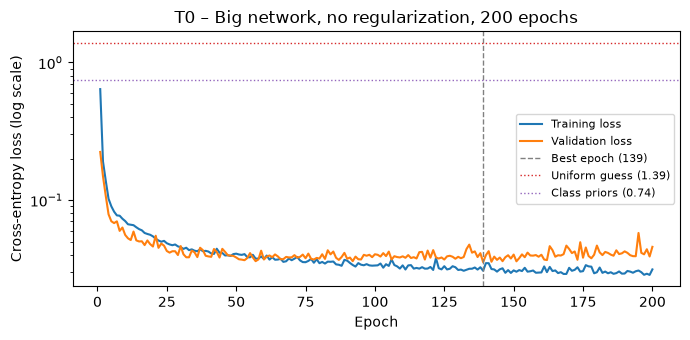

validation: accuracy 0.9883 (trivial 0.7541) | macro-F1 0.9804
              precision    recall  f1-score   support

      Benign      0.994     0.990     0.992      2518
 Brute Force      0.958     0.995     0.976       205
    DoS Hulk      0.976     0.977     0.977       574
    PortScan      0.955     1.000     0.977        42

    accuracy                          0.988      3339
   macro avg      0.971     0.991     0.980      3339
weighted avg      0.988     0.988     0.988      3339



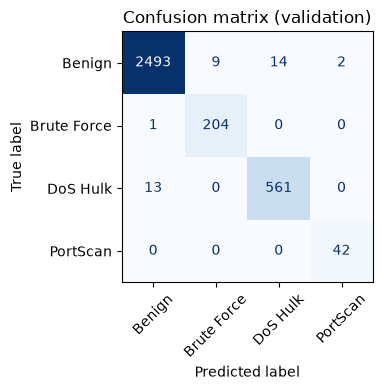

In [48]:
#T0 - BIG NETWORK [256,128,64,32,16], AdamW lr 5e-4 WITHOUT WEIGHT DECAY, BATCH 128, 200 EPOCHS, NO EARLY STOPPING (last weights)
model_T0 = run_experiment("T0", X_train_pf_t, X_val_pf_t, y_tr=y_train_pf_t, y_v=y_val_pf_t,
                          hidden_sizes=BIG, batch_size=BATCH6, num_epochs=EPOCHS6,
                          weight_decay=0.0, early_stopping=False, title="Big network, no regularization, 200 epochs")

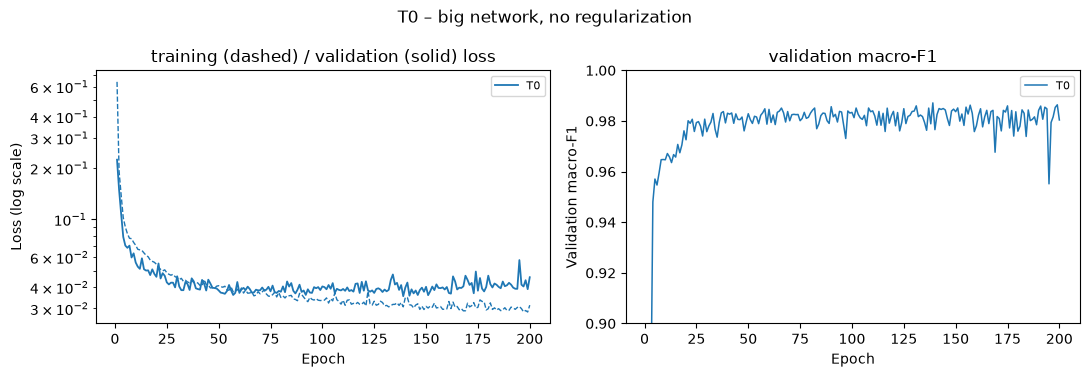

   macro-F1 (returned model) accuracy recall Benign recall Brute Force recall DoS Hulk recall PortScan missed attacks false alarms returned epoch val loss (returned) train loss (returned) val - train (returned) min val loss epoch of min val loss val loss returned / min max val macro-F1 (epoch) val roughness   time (s) s / epoch parameters
T0                   0.98039  0.98832      0.990071           0.995122        0.977352             1.0             14           25            200             0.04576              0.031374               0.014386     0.035424                   139                1.291787             0.9871 (139)      0.071024  60.884199  0.304421      47924 

epoch  10 | train loss 0.0704 | val loss 0.0558 | val - train -0.0146 | val macro-F1 0.9647
epoch  50 | train loss 0.0408 | val loss 0.0383 | val - train -0.0025 | val macro-F1 0.9829
epoch 100 | train loss 0.0335 | val loss 0.0404 | val - train +0.0069 | val macro-F1 0.9834
epoch 139 | train loss 0.0307 | val loss

In [49]:
#T0 - WHERE IS THE OVERFITTING? curves, numbers at key epochs, and the confident mistakes
plot_t6(["T0"], "T0 – big network, no regularization", "task6_T0_curves.png")
print(t6_table(["T0"]).T.to_string(), "\n")

h0 = runs["T0"]["history"]
e_min = int(np.argmin(h0["val_loss"])) + 1
for e in sorted({10, e_min, 50, 100, 150, 200}):
    print(f"epoch {e:3d} | train loss {h0['train_loss'][e-1]:.4f} | val loss {h0['val_loss'][e-1]:.4f} "
          f"| val - train {h0['val_loss'][e-1] - h0['train_loss'][e-1]:+.4f} | val macro-F1 {h0['val_f1'][e-1]:.4f}")

#why the loss rises more than the errors: confidence of the last-epoch model on its misclassified validation flows
with torch.no_grad():
    p = torch.softmax(runs["T0"]["model"](X_val_pf_t), dim=1)
wrong = p.argmax(1) != y_val_pf_t
ce = -torch.log(p[torch.arange(len(y_val_pf_t)), y_val_pf_t].clamp_min(1e-12))
print(f"\nlast epoch: {int(wrong.sum())} misclassified validation flows; they carry {ce[wrong].sum() / ce.sum():.1%} of the validation loss; "
      f"median confidence in the wrong class {p[wrong].max(1).values.median():.3f}")

**T0 – outcome vs hypothesis**

| epoch | 10 | 50 | 100 | 139 (lowest val loss) | 150 | 200 |
|---|---|---|---|---|---|---|
| training loss | 0.070 | 0.041 | 0.034 | 0.031 | 0.031 | 0.031 |
| validation loss | 0.056 | 0.038 | 0.040 | **0.035** | 0.040 | 0.046 |
| val − train | −0.015 | −0.003 | +0.007 | +0.005 | +0.009 | **+0.014** |
| validation macro-F1 | 0.965 | 0.983 | 0.983 | **0.987** | 0.984 | 0.980 |

- *Training loss – wrong.* It does not go towards zero: it flattens around 0.03 (we expected 0.005–0.02). With 3 parameters per training flow the network *could* memorise the training set, but 24,400 updates at lr 5e-4 do not get it there, and part of the training loss probably comes from flows that look like flows of another class (the same DoS Hulk / Benign confusion every model has).
- *Validation loss – right on the shape, wrong on timing and size.* There is no sharp U: the loss reaches about 0.038 by epoch 50, then stays on a noisy plateau (0.037–0.040) and its lowest point is at epoch 139 (0.035), much later than the 20–60 we expected. After that it rises to 0.046 at epoch 200, 1.29× its minimum (expected 1.5–4×).
- *Gap – right.* The validation loss ends clearly above the training loss: the two curves cross around epoch 60 and the gap grows to +0.014 at epoch 200 (in earlier runs the two stayed within a few thousandths of each other, e.g. +0.0023 for P2 at epoch 180 and +0.0009 for D3 at epoch 100).
- *Spikes – right.* Late in training both curves have spikes (validation loss 0.058 near epoch 195, with a macro-F1 dip to 0.955; visible in the T0 figure, since the printed log shows only every 10th epoch).
- *Macro-F1 overfits much less than the loss – right.* The last-epoch model has macro-F1 0.980, 0.007 below its best epoch (0.987 at epoch 139; expected 0.005–0.02 below).
- *Mechanism – confirmed.* At the last epoch the 39 misclassified validation flows (1.2%) carry **79% of the validation loss**, with a median confidence of 0.88 in the wrong class: the loss rises because a few mistakes become very confident, not because there are many more mistakes.
- *Cost – wrong.* 0.30 s per epoch, about 60 s in total (expected 0.4–0.6 s and 80–120 s): batch 128 halves the number of steps and the matrices are still small.

**Q: Is it overfitting? Show exactly where you see it in the curves.**
**Yes, but mildly, and almost only in the loss.** Three places in the T0 figure:
1. *The crossing of the curves around epoch 60.* Before it the training loss is above the validation loss, as in every earlier run; after it the training loss keeps falling (0.041 at epoch 50 → 0.031) while the validation loss stops falling, so val − train goes from −0.003 (epoch 50) to +0.014 (epoch 200). The network keeps improving on flows it trains on and no longer on new ones.
2. *The last ~60 epochs of the validation loss.* After its lowest point (0.035, epoch 139) it climbs to 0.046 at epoch 200 (+29%) while the training loss stays flat: the textbook overfitting signature, though small.
3. *The validation macro-F1 barely shows it.* It sits on a noisy plateau around 0.98 from epoch ~30 to 200; the last-epoch model is 0.007 below the best epoch, less than our 0.01 threshold. What overfits is the **confidence** of the predictions (79% of the loss from 39 confident mistakes), much more than the decisions.

The practical consequence for the next runs: there is little overfitting to remove, so we expect any fix to give small gains.

#### T1 – T0 with early stopping (←T0)

**Why this run:** step 1 of the lab text, the simplest possible fix: the same network and settings as T0, but training stops after 10 epochs without improvement of the validation loss and the best weights are restored (as in every run before Task 6).

**Hypothesis (written before running):**
- *Same start as T0:* same seed, same batches, so the curves coincide with T0 until early stopping ends the run, **between epoch 30 and 70**.
- *Metrics:* the returned model is T0 at its best validation epoch: min val loss 0.033–0.045 and macro-F1 0.975–0.985, about the level of D1/D2 and O4. Better than T0's last-epoch model by 0.005–0.02.
- *Cost:* 3–6× less training time than T0.
- *Compared with the references:* within ±0.01 of O4 on validation, so the big network gains nothing over the one-layer networks; it only costs 37× the parameters.

epoch   1 | train loss 0.6403 | val loss 0.2238
epoch  10 | train loss 0.0704 | val loss 0.0558
epoch  20 | train loss 0.0545 | val loss 0.0460
epoch  30 | train loss 0.0455 | val loss 0.0463
epoch  40 | train loss 0.0423 | val loss 0.0390
early stopping at epoch 42: no improvement for 10 epochs
best epoch: 32 (val loss 0.0384) | last epoch: 42 | time: 13.8 s


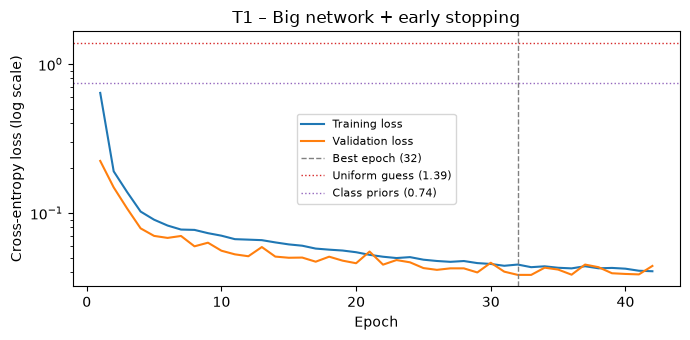

validation: accuracy 0.9886 (trivial 0.7541) | macro-F1 0.9796
              precision    recall  f1-score   support

      Benign      0.992     0.994     0.993      2518
 Brute Force      0.949     0.995     0.971       205
    DoS Hulk      0.991     0.965     0.978       574
    PortScan      0.976     0.976     0.976        42

    accuracy                          0.989      3339
   macro avg      0.977     0.983     0.980      3339
weighted avg      0.989     0.989     0.989      3339



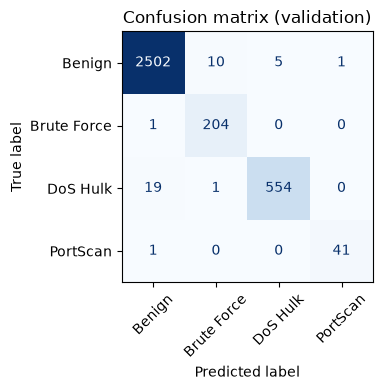

In [50]:
#T1 - SAME AS T0, WITH EARLY STOPPING (patience 10, best weights restored)
model_T1 = run_experiment("T1", X_train_pf_t, X_val_pf_t, y_tr=y_train_pf_t, y_v=y_val_pf_t,
                          hidden_sizes=BIG, batch_size=BATCH6, num_epochs=EPOCHS6,
                          weight_decay=0.0, early_stopping=True, title="Big network + early stopping")

**T1 – outcome vs hypothesis**

- *Same start, stop in range – right.* The curves are identical to T0 until early stopping ends the run at epoch 42 (best epoch 32; expected 30–70).
- *Cost – right.* About 14 s instead of about 61 s (≈4.4× less; expected 3–6×).
- *Metrics – wrong.* We expected the returned model to beat T0's last-epoch model by 0.005–0.02; it does not: macro-F1 0.9796 vs 0.9804. Early stopping fired on the first plateau of the validation loss (0.038 at epoch 32), while T0's lowest point came much later (0.035 at epoch 139): on a noisy curve that keeps improving slowly, a patience of 10 epochs stops early. The two models also sit at different points of the trade-off (T1: 21 missed attacks and 16 false alarms; T0: 14 and 25) with the same macro-F1.
- *Against the references – right.* 0.004 below O4 (within ±0.01) and 0.007 above P1.

Early stopping gives the same macro-F1 as 200 epochs of training at less than a quarter of the cost. It does not give a better model here, because T0 had little overfitting to cut off.

#### T2 – T0 with weight decay 0.1 (←T0)

**Why this run:** first regularizer of the lab text. It starts from T0, not from T1 (see the plan): 200 epochs, last weights, only `weight_decay` 0 → 0.1.

**Hypothesis (written before running):**
- *Curves.* The validation loss still has a minimum and still rises after it, but less: last-epoch val loss **20–50% lower than T0's**. Weight decay keeps the weights small, so the outputs stay less confident and the confident mistakes that drive T0's rise cost less. The training loss ends higher than in T0 (the decay fights the fit: about 0.01–0.03). The minimum of the validation loss stays about the same as T0's.
- *Macro-F1.* Within ±0.01 of T0: weight decay changes the confidence more than the decisions.
- *Rule.* Expected: kept (val loss −20% or more, macro-F1 within 0.01).

epoch   1 | train loss 0.6422 | val loss 0.2251
epoch  10 | train loss 0.0714 | val loss 0.0569
epoch  20 | train loss 0.0559 | val loss 0.0480
epoch  30 | train loss 0.0459 | val loss 0.0507
epoch  40 | train loss 0.0434 | val loss 0.0378
epoch  50 | train loss 0.0424 | val loss 0.0429
epoch  60 | train loss 0.0392 | val loss 0.0364
epoch  70 | train loss 0.0384 | val loss 0.0369
epoch  80 | train loss 0.0379 | val loss 0.0404
epoch  90 | train loss 0.0373 | val loss 0.0375
epoch 100 | train loss 0.0411 | val loss 0.0416
epoch 110 | train loss 0.0372 | val loss 0.0402
epoch 120 | train loss 0.0362 | val loss 0.0367
epoch 130 | train loss 0.0353 | val loss 0.0352
epoch 140 | train loss 0.0344 | val loss 0.0365
epoch 150 | train loss 0.0358 | val loss 0.0404
epoch 160 | train loss 0.0343 | val loss 0.0388
epoch 170 | train loss 0.0349 | val loss 0.0387
epoch 180 | train loss 0.0342 | val loss 0.0440
epoch 190 | train loss 0.0365 | val loss 0.0379
epoch 200 | train loss 0.0350 | val loss

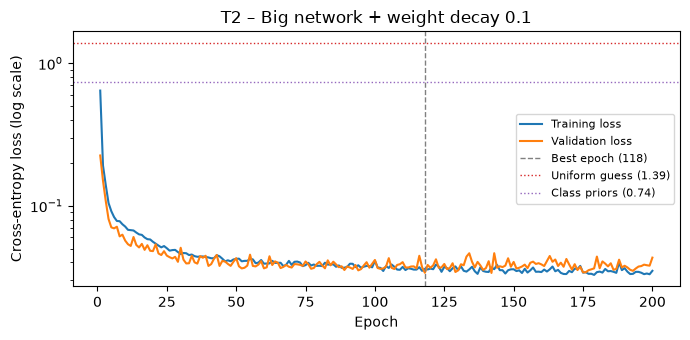

validation: accuracy 0.9886 (trivial 0.7541) | macro-F1 0.9799
              precision    recall  f1-score   support

      Benign      0.997     0.988     0.993      2518
 Brute Force      0.953     0.995     0.974       205
    DoS Hulk      0.966     0.988     0.977       574
    PortScan      0.976     0.976     0.976        42

    accuracy                          0.989      3339
   macro avg      0.973     0.987     0.980      3339
weighted avg      0.989     0.989     0.989      3339



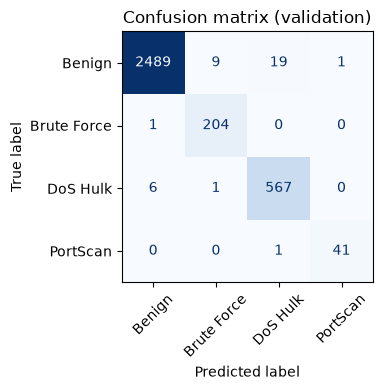

T2 vs T0: val loss 0.0458 -> 0.0433 (-5.5%) | macro-F1 0.9804 -> 0.9799 -> keep: False


In [51]:
#T2 - SAME AS T0, WITH WEIGHT DECAY 0.1 (still 200 epochs and last weights)
model_T2 = run_experiment("T2", X_train_pf_t, X_val_pf_t, y_tr=y_train_pf_t, y_v=y_val_pf_t,
                          hidden_sizes=BIG, batch_size=BATCH6, num_epochs=EPOCHS6,
                          weight_decay=WD6, early_stopping=False, title="Big network + weight decay 0.1")
KEEP_WD = keep_regularizer("T2", "T0")

**T2 – outcome vs hypothesis and decision**

| | T0 | T2 (wd 0.1) |
|---|---|---|
| val loss, last epoch / lowest | 0.0458 / 0.0354 (ep. 139) | 0.0433 / 0.0338 (ep. 142) |
| train loss, last epoch | 0.031 | 0.035 |
| macro-F1 (last epoch) | 0.9804 | 0.9799 |
| missed attacks / false alarms | 14 / 25 | 7 / 29 |

- *Val loss – wrong.* The last-epoch validation loss falls by only 5.5% (expected 20–50%); the lowest point is about the same as T0's, as expected. The training loss ends higher (0.035 vs 0.031), as expected, though just above the range we gave.
- *Macro-F1 – right.* Unchanged (−0.0005). T2 moves the errors rather than removing them: it misses the fewest attacks of all Task 6 runs (7) but raises more false alarms (29).
- *Decision (rule fixed before the run).* −5.5% is below the 10% threshold: **weight decay is dropped**, and T3 adds dropout to T0. We expected it to be kept.
- *Why it did less than predicted.* Our estimate (weights shrink to 30% over the run) holds only for weights the gradient does not support; the weights that matter are pushed back by the gradient at every step. And T0's overfitting was small (+29% on the validation loss), so there was little for weight decay to remove.

#### T3 – + dropout 0.2 (←T2 if weight decay was kept, otherwise ←T0)

**Why this run:** second regularizer. It is added on top of the last kept model, as the lab text asks ("check each on validation before adding the next"); the cell below takes the parent from the decision of T2.

**Hypothesis (written before running):**
- *Training loss above validation loss for the whole run.* The training loss is measured with dropout active (20% of the units switched off), the validation loss with all units, so val − train is negative again; this is not a sign of health in itself, just a consequence of how the two are measured.
- *Overfitting almost gone from the loss:* after its minimum the validation loss stays nearly flat (last-epoch value at most 1.3× the minimum) and ends at least 10% below its parent. Training is slower: the minimum comes later than in T0.
- *Macro-F1.* Within ±0.01 of its parent; the curve of the validation macro-F1 is noisier from epoch to epoch.
- *Rule.* Expected: kept.

T3 starts from T0 | weight decay 0.0
epoch   1 | train loss 0.7324 | val loss 0.2828
epoch  10 | train loss 0.1115 | val loss 0.0737
epoch  20 | train loss 0.0768 | val loss 0.0490
epoch  30 | train loss 0.0661 | val loss 0.0435
epoch  40 | train loss 0.0537 | val loss 0.0407
epoch  50 | train loss 0.0537 | val loss 0.0379
epoch  60 | train loss 0.0505 | val loss 0.0354
epoch  70 | train loss 0.0473 | val loss 0.0357
epoch  80 | train loss 0.0447 | val loss 0.0353
epoch  90 | train loss 0.0478 | val loss 0.0364
epoch 100 | train loss 0.0436 | val loss 0.0362
epoch 110 | train loss 0.0427 | val loss 0.0333
epoch 120 | train loss 0.0416 | val loss 0.0357
epoch 130 | train loss 0.0398 | val loss 0.0338
epoch 140 | train loss 0.0375 | val loss 0.0383
epoch 150 | train loss 0.0376 | val loss 0.0355
epoch 160 | train loss 0.0366 | val loss 0.0361
epoch 170 | train loss 0.0377 | val loss 0.0320
epoch 180 | train loss 0.0366 | val loss 0.0340
epoch 190 | train loss 0.0379 | val loss 0.0353
epo

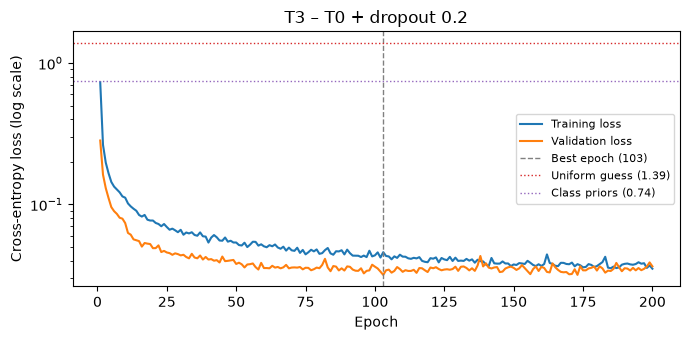

validation: accuracy 0.9904 (trivial 0.7541) | macro-F1 0.9849
              precision    recall  f1-score   support

      Benign      0.996     0.991     0.994      2518
 Brute Force      0.958     0.995     0.976       205
    DoS Hulk      0.979     0.984     0.982       574
    PortScan      0.977     1.000     0.988        42

    accuracy                          0.990      3339
   macro avg      0.977     0.993     0.985      3339
weighted avg      0.991     0.990     0.990      3339



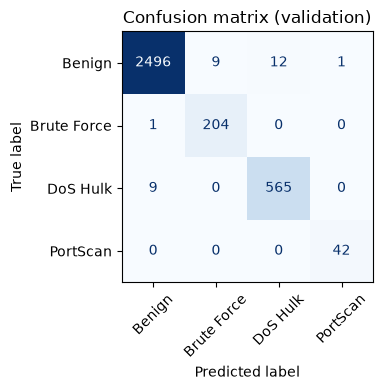

T3 vs T0: val loss 0.0458 -> 0.0364 (-20.4%) | macro-F1 0.9804 -> 0.9849 -> keep: True


In [52]:
#T3 - PARENT + DROPOUT 0.2 AFTER EVERY HIDDEN ReLU (parent: T2 if its weight decay was kept, otherwise T0)
PARENT_T3, WD_T3 = ("T2", WD6) if KEEP_WD else ("T0", 0.0)
print("T3 starts from", PARENT_T3, "| weight decay", WD_T3)
model_T3 = run_experiment("T3", X_train_pf_t, X_val_pf_t, y_tr=y_train_pf_t, y_v=y_val_pf_t,
                          hidden_sizes=BIG, batch_size=BATCH6, num_epochs=EPOCHS6, weight_decay=WD_T3,
                          dropout=0.2, early_stopping=False, title=f"{PARENT_T3} + dropout 0.2")
KEEP_DO = keep_regularizer("T3", PARENT_T3)

**T3 – outcome vs hypothesis and decision**

| | T0 | T3 (T0 + dropout 0.2) |
|---|---|---|
| val loss, last epoch / lowest | 0.0458 / 0.0354 (ep. 139) | 0.0364 / 0.0317 (ep. 103) |
| last-epoch val loss / lowest | 1.29 | 1.15 |
| val − train, last epoch | +0.014 | +0.001 |
| macro-F1 (last epoch) | 0.9804 | 0.9849 |
| missed attacks / false alarms | 14 / 25 | 10 / 22 |

- *Training loss above validation loss – mostly right.* For most of the run the training loss (measured with 20% of the units switched off) is above the validation loss; only near the end do the two meet (+0.001 at epoch 200, against +0.014 for T0).
- *Overfitting reduced – right.* The last-epoch validation loss is 20.4% lower than T0's and only 1.15× its own minimum (we expected at most 1.3×). Its lowest point, 0.0317, is the lowest on the port-free data so far.
- *Slower training – partly wrong.* The start is slower (validation loss at epoch 10: 0.074 vs 0.056), as expected, but the lowest point comes earlier than in T0 (epoch 103 vs 139), not later.
- *Macro-F1 – right.* 0.9849, +0.0045 over T0 (within ±0.01). We expected a noisier macro-F1 curve; it is actually steadier over the last 20 epochs (standard deviation 0.0041 vs 0.0066, see the check below).
- *Decision (rule fixed before the run).* Validation loss −20.4% (threshold 10%) and macro-F1 not lower: **dropout is kept**, and T4 adds batch norm on top of T3.
- *A plausible reading (not tested).* Dropout acts on the mechanism found in T0: a network that cannot rely on any single unit has a harder time building very confident outputs, so its mistakes cost less. Weight decay limits the size of the weights, which turned out to matter less here.

#### T4 – + batch normalization (←T3 if dropout was kept, otherwise ←its parent)

**Why this run:** third regularizer of the lab text, added on top of the last kept model.

**Hypothesis (written before running):**
- *Mostly an optimisation tool here, not a regularizer.* Batch norm rescales every pre-activation over the mini-batch, which speeds up the first epochs (faster initial drop of both losses). Its regularizing effect comes from the noise of the batch statistics, which is small with 128 flows per batch.
- *Validation curve noisier.* At evaluation the network uses running averages of the batch statistics, which lag behind the weights; together with dropout (which changes the variance of the activations between training and evaluation) we expect a jagged validation loss.
- *Rule.* Expected: **dropped**. The last-epoch validation loss does not fall by 10% compared with its parent; macro-F1 within ±0.01.
- *Cost.* Time per epoch +30–60% (one more operation per layer).

T4 starts from T3 | weight decay 0.0 | dropout 0.2
epoch   1 | train loss 0.8069 | val loss 0.4854
epoch  10 | train loss 0.1187 | val loss 0.0653
epoch  20 | train loss 0.0888 | val loss 0.0491
epoch  30 | train loss 0.0742 | val loss 0.0428
epoch  40 | train loss 0.0668 | val loss 0.0381
epoch  50 | train loss 0.0677 | val loss 0.0387
epoch  60 | train loss 0.0587 | val loss 0.0394
epoch  70 | train loss 0.0537 | val loss 0.0392
epoch  80 | train loss 0.0573 | val loss 0.0371
epoch  90 | train loss 0.0513 | val loss 0.0368
epoch 100 | train loss 0.0497 | val loss 0.0384
epoch 110 | train loss 0.0509 | val loss 0.0355
epoch 120 | train loss 0.0471 | val loss 0.0360
epoch 130 | train loss 0.0481 | val loss 0.0336
epoch 140 | train loss 0.0478 | val loss 0.0353
epoch 150 | train loss 0.0462 | val loss 0.0346
epoch 160 | train loss 0.0464 | val loss 0.0354
epoch 170 | train loss 0.0449 | val loss 0.0362
epoch 180 | train loss 0.0429 | val loss 0.0359
epoch 190 | train loss 0.0457 | val l

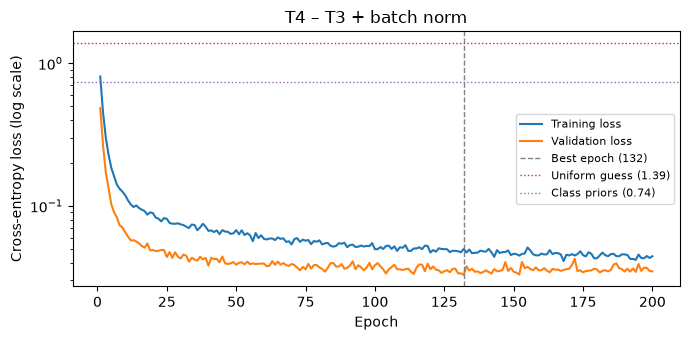

validation: accuracy 0.9901 (trivial 0.7541) | macro-F1 0.9842
              precision    recall  f1-score   support

      Benign      0.994     0.992     0.993      2518
 Brute Force      0.953     0.995     0.974       205
    DoS Hulk      0.984     0.979     0.982       574
    PortScan      1.000     0.976     0.988        42

    accuracy                          0.990      3339
   macro avg      0.983     0.986     0.984      3339
weighted avg      0.990     0.990     0.990      3339



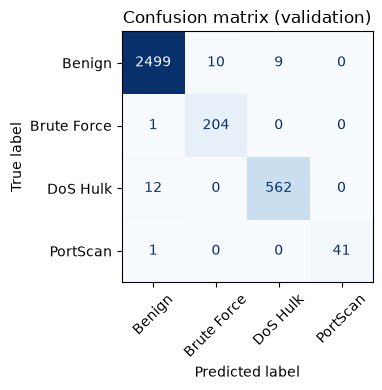

T4 vs T3: val loss 0.0364 -> 0.0348 (-4.5%) | macro-F1 0.9849 -> 0.9842 -> keep: False


In [53]:
#T4 - PARENT + BATCH NORMALIZATION BEFORE EVERY HIDDEN ReLU (parent: T3 if its dropout was kept, otherwise T3's parent)
PARENT_T4, DO_T4 = ("T3", 0.2) if KEEP_DO else (PARENT_T3, 0.0)
print("T4 starts from", PARENT_T4, "| weight decay", WD_T3, "| dropout", DO_T4)
model_T4 = run_experiment("T4", X_train_pf_t, X_val_pf_t, y_tr=y_train_pf_t, y_v=y_val_pf_t,
                          hidden_sizes=BIG, batch_size=BATCH6, num_epochs=EPOCHS6, weight_decay=WD_T3,
                          dropout=DO_T4, batchnorm=True, early_stopping=False, title=f"{PARENT_T4} + batch norm")
KEEP_BN = keep_regularizer("T4", PARENT_T4)

**T4 – outcome vs hypothesis and decision**

| | T3 | T4 (T3 + batch norm) |
|---|---|---|
| val loss, last epoch / lowest | 0.0364 / 0.0317 (ep. 103) | 0.0348 / 0.0328 (ep. 132) |
| macro-F1 (last epoch) | 0.9849 | 0.9842 |
| missed attacks / false alarms | 10 / 22 | 14 / 19 |
| val macro-F1, std of the last 20 epochs | 0.0041 | 0.0058 |
| s per epoch | 0.38 | 0.49 |

- *Faster start – wrong.* Batch norm did not speed up the first epochs: the validation loss after epoch 1 is 0.49 (T3: 0.28); by epoch 10 it has caught up and is slightly lower (0.065 vs 0.074).
- *Not a regularizer here – right.* The last-epoch validation loss falls by only 4.5% compared with T3, below the 10% threshold, and T4's lowest validation loss (0.0328) is higher than T3's (0.0317). Averaged over the last 20 epochs T4 is even slightly worse than T3 (+2.0%, see the check below).
- *Macro-F1 – right.* 0.9842 vs 0.9849 (−0.0007, within ±0.01).
- *Noisier – right.* The validation curves move more from one epoch to the next than T3's (macro-F1 standard deviation over the last 20 epochs 0.0058 vs 0.0041; loss roughness 0.053 vs 0.046). A plausible cause: at evaluation batch norm uses running averages of the batch statistics, and with dropout active during training these do not match exactly the activations seen at evaluation.
- *Cost – right, at the low end.* +30% per epoch over T3 (expected +30–60%).
- *Decision (rule fixed before the run).* **Batch norm is dropped.** The final regularized configuration is **T3: the big network with dropout 0.2, no weight decay**.

                                     T0           T1            T2            T3            T4           P1           O4
macro-F1 (returned model)       0.98039     0.979553      0.979875      0.984924        0.9842     0.972588     0.983482
accuracy                        0.98832     0.988619      0.988619      0.990416      0.990117     0.984127     0.989518
recall Benign                  0.990071     0.993646      0.988483      0.991263      0.992454     0.992057     0.992851
recall Brute Force             0.995122     0.995122      0.995122      0.995122      0.995122     0.995122     0.995122
recall DoS Hulk                0.977352     0.965157      0.987805      0.984321      0.979094     0.949477     0.973868
recall PortScan                     1.0      0.97619       0.97619           1.0       0.97619     0.928571     0.976190
missed attacks                       14           21             7            10            14    31.000000    16.000000
false alarms                    

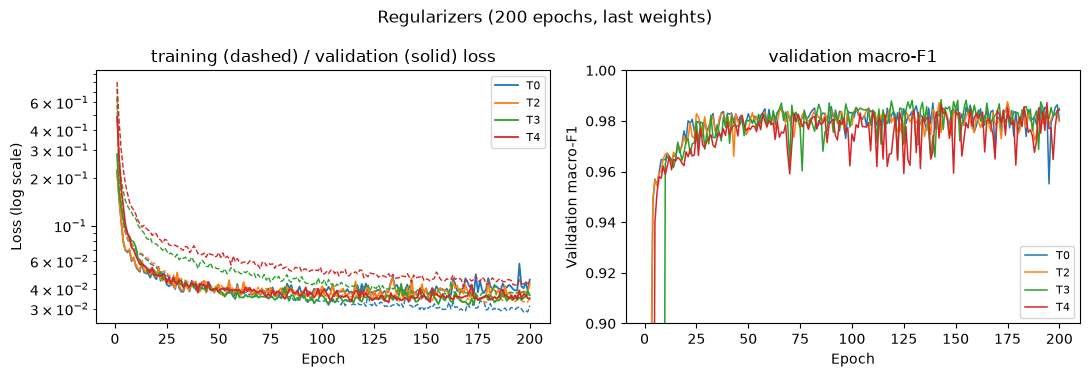

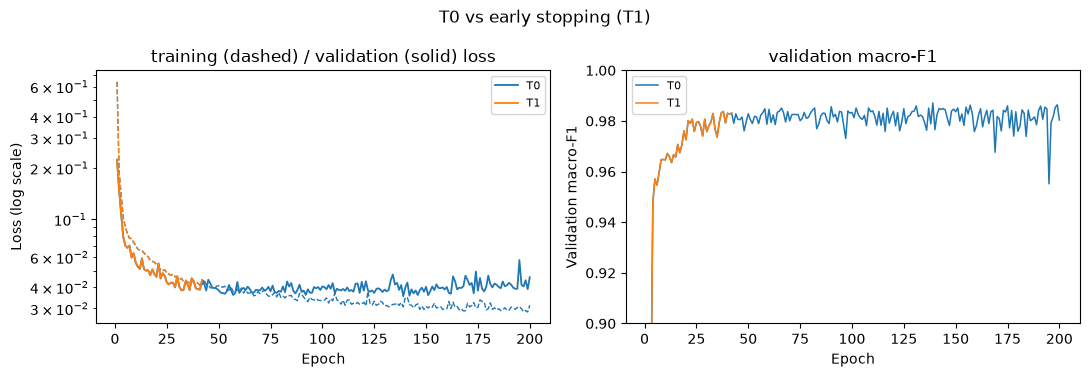

In [54]:
#TASK 6 SUMMARY (validation): T0-T4 next to the one-layer references P1 and O4
cols = ["T0", "T1", "T2", "T3", "T4"]
tab6 = t6_table(cols)
ref = pd.DataFrame({rid: {"macro-F1 (returned model)": runs[rid]["macro_f1"], "accuracy": runs[rid]["accuracy"],
                          **{f"recall {c}": runs[rid]["recall"][c] for c in le.classes_},
                          "missed attacks": detection_summary(rid)["attacks predicted Benign (missed)"],
                          "false alarms": detection_summary(rid)["Benign predicted as attack (false alarms)"],
                          "returned epoch": runs[rid]["best_epoch"], "min val loss": min(runs[rid]["history"]["val_loss"]),
                          "time (s)": runs[rid]["time_s"], "parameters": runs[rid]["n_params"]} for rid in ["P1", "O4"]})
print(pd.concat([tab6, ref], axis=1).to_string())
print(f"\nkept: weight decay {KEEP_WD} | dropout {KEEP_DO} | batch norm {KEEP_BN}")
plot_t6(["T0", "T2", "T3", "T4"], "Regularizers (200 epochs, last weights)", "task6_regularizers_curves.png")
plot_t6(["T0", "T1"], "T0 vs early stopping (T1)", "task6_T0_T1_curves.png")

In [55]:
#POST-HOC CHECK (analysis of the curves already recorded, not a new run and not part of the keep-or-drop rule):
#the rule compares single last-epoch values, but the validation loss moves by about 5-10% from one epoch to the next
#(roughness 0.05-0.07): averages over the last 20 epochs tell whether the decisions depend on that noise
post = {}
for rid in ["T0", "T2", "T3", "T4"]:
    h = runs[rid]["history"]
    post[rid] = {"val loss, last epoch": h["val_loss"][-1], "val loss, mean of last 20": np.mean(h["val_loss"][-20:]),
                 "train loss, mean of last 20": np.mean(h["train_loss"][-20:]),
                 "val macro-F1, last epoch": h["val_f1"][-1], "val macro-F1, mean of last 20": np.mean(h["val_f1"][-20:]),
                 "val macro-F1, std of last 20": np.std(h["val_f1"][-20:])}
post = pd.DataFrame(post)
print(post.round(4).to_string(), "\n")
for rid, parent in [("T2", "T0"), ("T3", "T0"), ("T4", "T3")]:
    d = 1 - post.loc["val loss, mean of last 20", rid] / post.loc["val loss, mean of last 20", parent]
    f = post.loc["val macro-F1, mean of last 20", rid] - post.loc["val macro-F1, mean of last 20", parent]
    print(f"{rid} vs {parent} (means of the last 20 epochs): val loss {-d:+.1%} | val macro-F1 {f:+.4f}")


                                   T0      T2      T3      T4
val loss, last epoch           0.0458  0.0433  0.0364  0.0348
val loss, mean of last 20      0.0420  0.0379  0.0353  0.0360
train loss, mean of last 20    0.0299  0.0346  0.0374  0.0445
val macro-F1, last epoch       0.9804  0.9799  0.9849  0.9842
val macro-F1, mean of last 20  0.9807  0.9802  0.9823  0.9783
val macro-F1, std of last 20   0.0066  0.0030  0.0041  0.0058 

T2 vs T0 (means of the last 20 epochs): val loss -9.6% | val macro-F1 -0.0005
T3 vs T0 (means of the last 20 epochs): val loss -15.9% | val macro-F1 +0.0016
T4 vs T3 (means of the last 20 epochs): val loss +2.0% | val macro-F1 -0.0040


**Post-hoc check – are the keep-or-drop decisions robust to the epoch-to-epoch noise?**

| comparison | last epoch (rule) | mean of the last 20 epochs |
|---|---|---|
| T2 vs T0, val loss | −5.5% → dropped | −9.6% → still below 10% (borderline) |
| T3 vs T0, val loss | −20.4% → kept | −15.9% → kept |
| T4 vs T3, val loss | −4.5% → dropped | +2.0% → dropped |
| T4 vs T3, macro-F1 | −0.0007 | −0.0040 |

The three decisions do not change when we average the last 20 epochs instead of reading only the last one. **Limit of our rule:** we fixed it on single last-epoch values, which on curves that move by 5–10% from one epoch to the next is fragile: T2 is 0.4 points from the threshold once averaged, and T3's lead over T0 shrinks from 20.4% to 15.9%. We keep the rule as it was written before the runs and report this as its weakness; a better rule would have used the average of the last epochs from the start.

**Q: Which change helped the most for the least effort?**

| change (one each) | extra effort | effect on validation |
|---|---|---|
| early stopping (T1) | none: a flag already in our code, no new hyper-parameter | same macro-F1 as T0 (0.980), **4.4× less training time** |
| weight decay 0.1 (T2) | one hyper-parameter | val loss −5.5%, macro-F1 unchanged: no measurable effect |
| dropout 0.2 (T3) | one line + one hyper-parameter, +24% time per epoch | **val loss −20%** (less overconfidence), macro-F1 +0.0045 |
| batch norm (T4) | one line, +30% time per epoch | val loss −4.5% (+2% on average), macro-F1 unchanged, noisier curves |

**Early stopping gave the most per unit of effort**: it costs nothing to add, removes about three quarters of the training time and gives the same detector. **Dropout is the only change that clearly improved something**, the validation loss (−20%), i.e. the calibration of the probabilities; its macro-F1 gain (+0.0045) is below our 0.01 threshold. Weight decay and batch norm cost tuning and time for no gain. All four changes are small because the problem they address, overfitting, was small in T0 to begin with.

### 6 – Test set: did the big network beat the simple baseline?

**Why this step:** the lab text asks for the comparison with the simple port-free baseline of Task 4 (P1) on the test set; we also show O4, the reference after Task 5. The big network evaluated is the best Task 6 model on validation (highest macro-F1 of the returned model, chosen by the code). P1 and O4 were already evaluated on this test set in 5D; we report the same numbers, no choice is made from them. Evaluating trained models is not a new run.

**Hypothesis (written before running):** the best big network is within ±0.015 of O4 on the test macro-F1 and does not beat it by more than our 0.01 threshold; it beats P1 only by about as much as O4 does (P1 had the weakest test PortScan result, 37 of 43). With 37× the parameters the answer we expect is "no gain worth the complexity".

best Task 6 model on validation: T3 (macro-F1 0.9849)

test (T3): accuracy 0.9883 (trivial 0.7539) | macro-F1 0.9747
              precision    recall  f1-score   support

      Benign      0.996     0.989     0.993      2518
 Brute Force      0.931     0.990     0.960       205
    DoS Hulk      0.978     0.986     0.982       574
    PortScan      0.976     0.953     0.965        43

    accuracy                          0.988      3340
   macro avg      0.970     0.980     0.975      3340
weighted avg      0.989     0.988     0.988      3340



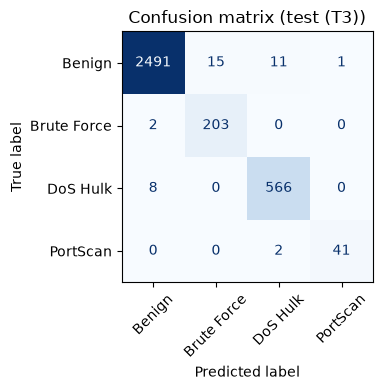

                                   P1         O4          T3
val macro-F1                   0.9726     0.9835      0.9849
test macro-F1                  0.9551     0.9770      0.9747
test accuracy                  0.9802     0.9877      0.9883
test recall Benign             0.9889     0.9917      0.9893
test recall Brute Force        0.9902     0.9902      0.9902
test recall DoS Hulk           0.9477     0.9721      0.9861
test recall PortScan           0.8605     0.9535      0.9535
test precision Benign          0.9857     0.9924      0.9960
test precision Brute Force     0.9269     0.9312      0.9312
test precision DoS Hulk        0.9767     0.9876      0.9775
test precision PortScan        0.9737     1.0000      0.9762
test missed attacks           36.0000    19.0000     10.0000
test false alarms             28.0000    21.0000     27.0000
parameters                  1284.0000  1284.0000  47924.0000
training time (s)             26.5979    15.5124     75.7257


In [56]:
#TEST: best Task 6 model (on validation) vs P1 and O4 (their test results come from 5D: test_res)
BEST_T6 = max(cols, key=lambda rid: runs[rid]["macro_f1"])
print(f"best Task 6 model on validation: {BEST_T6} (macro-F1 {runs[BEST_T6]['macro_f1']:.4f})\n")
test_res[BEST_T6] = evaluate(runs[BEST_T6]["model"], X_test_pf_t, y_test_pf_t, f"test ({BEST_T6})", filename=f"task6_{BEST_T6}_cm_test.png")

side6 = {}
for rid in ["P1", "O4", BEST_T6]:
    res = test_res[rid]
    side6[rid] = {"val macro-F1": runs[rid]["macro_f1"], "test macro-F1": res["macro_f1"], "test accuracy": res["accuracy"],
                  **{f"test recall {c}": res["recall"][c] for c in le.classes_},
                  **{f"test precision {c}": res["precision"][c] for c in le.classes_},
                  **{f"test {k}": v for k, v in detector_view(y_test_pf_encoded, res["y_pred"]).items()},
                  "parameters": runs[rid]["n_params"], "training time (s)": runs[rid]["time_s"]}
print(pd.DataFrame(side6).round(4).to_string())

**Test set – outcome vs hypothesis**

| | P1 | O4 | T3 (big + dropout) |
|---|---|---|---|
| parameters | 1,284 | 1,284 | 47,924 |
| macro-F1 val / test | 0.973 / 0.955 | 0.983 / 0.977 | 0.985 / 0.975 |
| test recall DoS Hulk / PortScan | 0.948 / 0.860 | 0.972 / 0.953 | 0.986 / 0.953 |
| test missed attacks / false alarms | 36 / 28 | 19 / 21 | **10** / 27 |
| training time, relative to O4 | ≈1.7× | 1× | ≈4.9× |

- *Within ±0.015 of O4, not better than O4 – right.* T3's test macro-F1 is 0.975, 0.002 below O4's 0.977.
- *Beats P1 by about as much as O4 does – right.* +0.020 (O4: +0.022).
- *Generalisation.* T3 loses 0.010 of macro-F1 from validation to test (at the edge of our ±0.01), O4 0.007.
- *Different trade-off.* T3 misses the fewest attacks on the test set (10, against 19 for O4 and 36 for P1), almost all thanks to DoS Hulk (recall 0.986), but raises 6 more false alarms than O4 (27 vs 21).

**Q: In the end, did the big network – even with regularization – do better on the test set than the simple port-free baseline of Task 4?**
**Against P1, yes; but not because it is big.** T3 beats P1 on the test set (macro-F1 0.975 vs 0.955, 10 missed attacks instead of 36). O4, which has exactly P1's architecture (1,284 parameters) and only a different optimizer and learning rate, does the same (0.977) with 37× fewer parameters and about a fifth of the training time. So the gain over P1 comes from how the network is trained, not from its size: the big network, even regularized, does not beat a well-trained one-layer network on macro-F1.
The one argument for T3 is the trade-off: compared with O4 it misses 9 fewer attacks for 6 more false alarms. Following the reasoning of Task 4, T3 is preferable only if a missed attack costs more than about 0.7 false alarms, which is plausible for an intrusion detector but is a deployment decision, not something our metric decides. On macro-F1, the metric we chose, the extra complexity is not worth it.
*Limits.* One seed; 43 PortScan test flows (one flow ≈ 2.3 points of recall). The test set has now been used for P1, O4 and T3: no choice was made from it (T3 was chosen on validation), but every extra model we look at on the same test set makes its numbers a little less of a clean estimate.

## Final reflection – which decisions gave the most performance per unit of effort?

Validation macro-F1 unless stated otherwise. Task 2 numbers are on the data with the port and are not directly comparable with the port-free ones; the comparison within each row is.

| decision | runs | measured effect | per run |
|---|---|---|---|
| scale the inputs at all (S1 vs R1) | 1 | 0.694 → 0.937; without scaling Brute Force is never detected | essential |
| log1p before the scaler (R1 → R1L) | 1 | 0.937 → 0.988, errors 182 → 28 | **largest gain of the lab** |
| learning rate in the right range (S3 on the data with the port; O1 → O2 port-free) | 2 | lr 100× too small: 0.913 (Adam), 0.698 (SGD); SGD at its own lr 0.974 | large, if wrong |
| converge before judging (R2: 200-epoch cap) | 1 | +0.002 | small |
| remove the port and de-duplicate (Task 3) | 0 | removed a fake score: Brute Force recall 0.995 → 0.000 on port 8080 | validity, not score |
| class-weighted loss (P2) | 1 | −0.036 macro-F1 (−26 missed attacks, +55 false alarms) | a trade-off, not a gain |
| depth (D1–D3) | 3 | at most +0.0095, below our threshold | ≈ 0 |
| batch size (B1, B2) | 2 | −0.002 and −0.016; batch 1 costs 14× the time | negative |
| optimizer × lr grid (O1–O5) | 5 | one run (O4) +0.011 on validation, +0.022 on test vs P1 | 1 useful run out of 5 |
| big network + regularization (T0–T4) | 5 | best (T3) equal to O4 on test | ≈ 0 vs O4 |

**Argument from our runs.**
- *The decisions about the inputs gave the most, for one run each.* Scaling and log1p are one line of code and moved the macro-F1 by 0.05–0.3. They also decided whether later experiments were readable at all: without log1p, R1 confused DoS Hulk and PortScan with Benign; without scaling, the loss was meaningless (S1).
- *The decisions about the data were worth more than any score.* Removing the port did not raise the macro-F1; it removed a fake one. The counterfactual of Task 3 showed that the 0.995 Brute Force recall was the port, and the de-duplication showed that the PortScan scores were memorised copies. Without these two decisions every later comparison would have measured the shortcut, not the detector. They cost no training runs.
- *The learning rate was the only hyper-parameter that paid inside Task 5.* Getting it wrong costs a lot (S3, O1); getting it right for the chosen optimizer gave the best one-layer model (O4).
- *Complexity gave nothing beyond our threshold.* Depth, batch size, the big network and three regularizers took 10 runs (Tasks 5–6) and none beat a one-layer network with 1,284 parameters by more than 0.01 on macro-F1. The remaining errors (mostly DoS Hulk flows that look like Benign flows in these 15 features) are a property of the data, and capacity cannot fix them.
- *What we would do differently.* On a new problem: check the scaling and the input distributions first, run a short learning-rate sweep, and stop. Two of our 27 runs answered nothing new (lr = 1e-2 in the S2 sweep and D2 in 5A, see their outcome cells): without them we would have stayed within the ~25 of the lab text. Spend the remaining budget on questions about the data (shortcut features, duplicates, mislabelled or contradictory flows) and on several seeds for the final comparison, which we never had the budget for. Our decision thresholds were fixed in advance and never checked against the real run-to-run variance.

### Task 6 – logbook rows (for the appendix)

Big network = [256, 128, 64, 32, 16] ReLU, cross-entropy, AdamW lr 5e-4, batch 128, 200 epochs, port-free data. Key result = validation; the model of runs without early stopping is the one of the last epoch.

| Run | Task | What I changed (one thing) | Hypothesis before running | Key result (val) | What I concluded |
|---|---|---|---|---|---|
| T0 | 6 | big network, weight decay 0, no early stopping | U-shaped val loss (min at ep. 20–60, ends 1.5–4× higher); train loss → 0.005–0.02; macro-F1 0.96–0.98 | val loss min 0.035 (ep. 139) → 0.046 (×1.29); train loss 0.031; val−train +0.014; macro-F1 0.980 | mild overfitting, mostly in the confidence (39 mistakes = 79% of the loss); macro-F1 barely affected |
| T1 (←T0) | 6 | early stopping (patience 10) | stop at ep. 30–70; better than T0 last epoch by 0.005–0.02; 3–6× faster | stop at 42 (best 32); macro-F1 0.980; ≈14 s vs ≈61 s | same detector at under 1/4 of the cost; stopped on an early plateau |
| T2 (←T0) | 6 | weight decay 0 → 0.1 | last-epoch val loss −20 to −50%; macro-F1 ±0.01; kept | val loss −5.5%; macro-F1 0.980; 7 missed / 29 false alarms | dropped by the rule (borderline once averaged: −9.6%) |
| T3 (←T0) | 6 | + dropout 0.2 | train > val; val loss ≤1.3× its min, −10% or more; macro-F1 ±0.01; kept | val loss −20.4%, ×1.15 its min; macro-F1 0.985 | kept; the only regularizer with a clear effect (on the loss) |
| T4 (←T3) | 6 | + batch norm | faster start; val loss not −10%; noisier; dropped | val loss −4.5% (+2.0% averaged); macro-F1 0.984 (−0.0007); slower start; noisier curves | dropped; no gain, +30% time per epoch, noisier than T3 |

Task 6 used 5 runs; total for the lab: **27 runs**. The test evaluation of T3 is not a new run.

## Appendix – Experiment logbook (all 27 runs)

One row per run that trains a model, in the order of the notebook. The run each one starts from is in brackets; the run name is the Markdown header of its cell (the four S2 runs share the sweep cell). Key result = validation set. Evaluations of already-trained models on the test set (2C, 3.2, 5D, Task 6) and the analysis cells are not runs.

*Budget:* Task 2: 10 runs; Task 4: 2; Task 5: 10; Task 6: 5; **total 27**, two more than the ~25 of the lab text (S2-lr0.01 and D2; see the final reflection).

| Run | Task | What I changed (one thing) | Hypothesis before running | Key result (val) | What I concluded |
|---|---|---|---|---|---|
| R1 | 2A | starting point: 1 hidden layer of 64 ReLU, AdamW lr 5e-4, batch 64, ≤100 epochs, patience 10, standard scaling | Brute Force hardest (rarest, inside the bulk), missed as Benign; DoS Hulk and PortScan easiest; macro-F1 < accuracy; early stop before epoch 100 | macro-F1 0.9365, acc. 0.9587; Brute Force precision 0.824 (43 false positives, all Benign on port 80), recall 0.944; lowest recalls PortScan 0.928, DoS Hulk 0.934; best epoch 100/100 (val loss 0.1166) | Brute Force fails by false positives, not misses, and port 80 drives them; DoS Hulk and PortScan lost to Benign; not converged → test log1p |
| R1L (←R1) | 2A | log1p before the StandardScaler | faster and lower val loss; Brute Force precision ≥ 0.85; DoS Hulk and PortScan about unchanged; adopt if macro-F1 +0.01 and no recall −0.02 | macro-F1 0.9875 (+0.0510); errors 182 → 28; DoS Hulk recall 0.934 → 0.993, PortScan 0.928 → 0.994; Brute Force precision 0.939; best epoch 99/100 (val loss 0.0273) | log1p kept for the whole lab; the biggest gains came where we expected none: standard scaling had squeezed the DoS Hulk and PortScan features |
| S1 (←R1) | 2B | StandardScaler removed (raw inputs, no scaling at all) | start loss 1e3–1e6, jagged curve, no NaN; min val loss far above 0.027; macro-F1 0.5–0.85 | untrained loss 1.373e+06; first-epoch train loss 86142.1984; min val loss 3058.5143; stop at epoch 13 (best 3); macro-F1 0.6943; Brute Force recall 0.000 | badly conditioned inputs (saturated softmax); scaling is the fundamental to fix first |
| S2-lr0.01 (←R1L) | 2B | lr 5e-4 → 1e-2 | about as good as R1L, maybe noisier | min val loss 0.0251; val roughness 0.1289 (R1L 0.0361); macro-F1 0.9870; stop at epoch 42 (best 32) | as predicted: as good as R1L but noisier; says nothing about where training breaks (redundant in hindsight) |
| S2-lr0.1 (←R1L) | 2B | lr 5e-4 → 1e-1 | noisy, worse min val loss, still learning | min val loss 0.0621; val roughness 0.723 (R1L 0.0361); macro-F1 0.9767; stop at epoch 17 | as predicted: noisier, not broken |
| S2 = S2-lr1 (←R1L) | 2B | lr 5e-4 → 1 | broken: spikes, no smooth descent; criterion: min val loss > 0.31 or NaN | first-epoch train loss 4.3650 (> ln 4); val loss 16.5687 at epoch 10; val roughness 1.657; min val loss 0.1393; macro-F1 0.9036 | overshoot; criterion met by no lr, so lr = 1 is S2 by the fallback rule; min val loss hides the breakdown, roughness shows it |
| S2-lr10 (←R1L) | 2B | lr 5e-4 → 10 | clearly broken | first-epoch train loss 388.1683; val roughness 3.2596; min val loss 0.2775 (< 0.31); macro-F1 0.9111 | broken in shape but not by our criterion: early stopping restores a lucky epoch |
| S3 (←R1L) | 2B | lr 5e-4 → 5e-6 | smooth, still falling at epoch 100; val loss ≈ R1L after one epoch (0.3–0.5); Brute Force lowest recall | val loss 0.2934 at epoch 100 (R1L at epoch 1: 0.3370); best = last epoch; macro-F1 0.9128; lowest recall DoS Hulk 0.807 | underfitting from too slow optimisation; distance estimate right, class prediction wrong |
| R2 (←R1L) | 2C | epoch cap 100 → 200 | min val loss 0.019–0.0245, best epoch 120–200; macro-F1 +0.000 to +0.005; adopt if val loss −10% and no recall −0.01 | min val loss 0.0232 (−14.8%); best epoch 158, stop 168; macro-F1 0.9894 (+0.0019); max recall loss 0.000 | criterion met: R2 replaces R1L as the baseline (converged) |
| R3 (←R1L) | 2C | ReLU → linear hidden layer (no activation) | min val loss 0.10–0.30; macro-F1 0.85–0.93 (at least −0.05); Brute Force precision < 0.80 | min val loss 0.1306; macro-F1 0.9308 (−0.0567); Brute Force precision 0.803, recall 0.860; 123 of the 137 errors among Benign / Brute Force / DoS Hulk are on port 80 | ReLU kept; a linear model cannot isolate "port ≈ 80" |
| P1 (←R2) | 4 | data with the port → port-free data (15 features) | PortScan suffers most (recall 0.6–0.9); Brute Force recall ≥ 0.9, precision 0.8–0.92; accuracy 0.975–0.99, macro-F1 0.90–0.95 | macro-F1 0.9726, acc. 0.9841; PortScan 39 of 42 (recall 0.929, precision 1.000); DoS Hulk recall 0.949 (28 → Benign); 31 missed attacks, 20 false alarms; best epoch 92/102 | PortScan still detected; without the port DoS Hulk suffers most; reference for Task 5 |
| P2 (←P1) | 4 | unweighted → class-weighted cross-entropy (balanced, from the training labels) | accuracy −0.001 to −0.01, macro-F1 +0.005 to +0.04, PortScan recall ≥ 0.95; wrong if macro-F1 falls | macro-F1 0.9369 (−0.0357); acc. 0.9751; macro-recall 0.9663 → 0.9883; missed attacks 31 → 5, false alarms 20 → 75; PortScan precision 0.750 | the "wrong if" happened: P1 was not under-detecting; the weights trade 26 misses for 55 false alarms; P1 kept |
| D1 (←P1) | 5A | hidden layers [64] → [64, 64] | depth does not help: macro-F1 within ±0.01 of P1; earlier best epoch | macro-F1 0.9820 (+0.0094); DoS Hulk recall 0.9495 → 0.9739; best epoch 61 | gain below threshold (about three PortScan flows); faster convergence |
| D2 (←P1) | 5A | [64] → [64, 64, 64] (9,604 params) | as D1; gap less negative, maybe slightly positive | macro-F1 0.9821 (+0.0095); best epoch 40; gap −0.0017 | a third layer adds nothing over the second; no overfitting (redundant in hindsight) |
| D3 (←P1) | 5A | [64] → [32, 32] (1,700 params) | behaves like P1 | macro-F1 0.9750 (+0.0024); best epoch 92, as P1 | depth at constant parameter count changes nothing |
| B1 (←P1) | 5B | batch 64 → 1 | jagged curve, best epoch ≤15, macro-F1 P1 −0.02 to +0.005; time ×5–15 | macro-F1 0.9706 (−0.0020); best epoch 37; 360.4 s (P1: 26.6 s) | no gain at about 14× the time; val roughness 3× P1 (0.0926 vs 0.0307); best epoch later than predicted |
| B2 (←P1) | 5B | batch 64 → 1024 | underfits (3,200 updates), macro-F1 −0.02 to −0.08; 3–6× faster | macro-F1 0.9567 (−0.0159); best epoch 199/200; 27.1 s (P1: 26.6 s) | underfitting from too few updates; not faster in total (wrong on time) |
| O1 (←P1) | 5C | AdamW → SGD (lr 5e-4) | far too slow; macro-F1 0.6–0.9; PortScan ~0 | macro-F1 0.6975; PortScan recall 0.000; best epoch 200/200 (still falling) | SGD needs a much larger lr than Adam |
| O2 (←O1) | 5C | lr 5e-4 → 5e-2 (SGD) | within 0.02 of P1 | macro-F1 0.9735 (+0.0010) | at its own lr SGD matches AdamW |
| O3 (←O1) | 5C | + momentum 0.9 (SGD, lr 5e-4) | ~10× faster than O1, not converged; macro-F1 0.85–0.95 | macro-F1 0.9521; best epoch 200/200 (still falling) | momentum helps, but the lr is still too small |
| O4 (←O3) | 5C | lr 5e-4 → 5e-2 (SGD + momentum 0.9) | close to P1, roughest SGD curve, stops earliest | macro-F1 0.9835 (+0.0109); missed attacks 31 → 16; stop at 76 | best run of Task 5; meets the criterion by 0.0009 (wrong prediction) → replaces P1 as reference |
| O5 (←P1) | 5C | AdamW lr 5e-4 → 5e-2 | jagged, early stop < 60, macro-F1 −0.03 to 0 | macro-F1 0.9665 (−0.0061); best epoch 5; val roughness 0.2996 (P1: 0.0307) | Adam tolerates a 100× lr range; lr dominates for SGD, not for AdamW |
| T0 | 6 | new starting point set by the lab text (not a one-change run): big network, weight decay 0, no early stopping | U-shaped val loss (min at ep. 20–60, ends 1.5–4× higher); train loss → 0.005–0.02; macro-F1 0.96–0.98 | min val loss 0.0354 (epoch 139) → 0.0458 at epoch 200 (×1.29); train loss 0.0314; val − train +0.0144; macro-F1 0.9804 | mild overfitting, mostly in the confidence (39 mistakes = 79.0% of the loss); macro-F1 barely affected |
| T1 (←T0) | 6 | early stopping (patience 10) | stop at ep. 30–70; better than T0 last epoch by 0.005–0.02; 3–6× faster | stop at 42 (best 32); macro-F1 0.9796; 13.8 s vs 60.9 s | same detector at under 1/4 of the cost; stopped on an early plateau |
| T2 (←T0) | 6 | weight decay 0 → 0.1 | last-epoch val loss −20 to −50%; macro-F1 ±0.01; kept | val loss 0.0458 → 0.0433 (−5.5%); macro-F1 0.9799; 7 missed / 29 false alarms | dropped by the rule (borderline once averaged: −9.6%) |
| T3 (←T0) | 6 | + dropout 0.2 | train > val; val loss ≤1.3× its min, −10% or more; macro-F1 ±0.01; kept | val loss 0.0458 → 0.0364 (−20.4%), ×1.15 its min; macro-F1 0.9849 | kept; the only regularizer with a clear effect (on the loss) |
| T4 (←T3) | 6 | + batch norm | faster start; val loss not −10%; noisier; dropped | val loss 0.0364 → 0.0348 (−4.5%; +2.0% averaged); macro-F1 0.9842 (−0.0007); slower start; noisier curves | dropped; no gain, s/epoch 0.4928 vs 0.3786 (+30%), noisier than T3 |
